# How `Qdrant/BM25` compute the sparse vector

In [2]:
from collections import Counter
from fastembed.sparse import SparseTextEmbedding


model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

text = """A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS."""

vec = next(model.embed([text]))
print(f"Text: {text} \nLength of text: {len(text)}\n")
print("=== Sparse vector ===")
print("indices:", vec.indices)
print("values:", vec.values)
print("non-zero dimensions:", len(vec.indices))


# Use FastEmbed's real internal BM25 preprocessing
tokens = bm25.tokenizer.tokenize(text.lower())

# Remove stopwords
tokens_no_stopwords = [
    token for token in tokens
    if token not in bm25.stopwords
]

# Stem correctly: pass a list, not one string
if not bm25.disable_stemmer:
    final_terms = bm25._stem(tokens_no_stopwords)
else:
    final_terms = tokens_no_stopwords

# Compute ids from final terms
term_counts = Counter(final_terms)

index_to_value = {
    int(i): float(v)
    for i, v in zip(vec.indices, vec.values)
}

print("\n=== Included terms ===")
print(f"{'term':<40} {'count':<8} {'index':<15} {'value'}")
print("-" * 60)

for term, count in term_counts.items():
    idx = int(bm25.compute_token_id(term))
    value = index_to_value.get(idx, 0.0)

    print(f"{term:<40} {count:<8} {idx:<15} {value}")


print("\n=== Dropped stopwords ===")
dropped = [
    token for token in tokens
    if token in bm25.stopwords
]
print(dropped)

Text: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS. 
Length of text: 92

=== Sparse vector ===
indices: [1471019746 1298296063  938217065  390168769  801873620 1796268431
 1714506967 1035623941 1270418937]
values: [1.65209739 1.65209739 1.65209739 1.65209739 1.65209739 1.65209739
 1.65209739 1.65209739 1.65209739]
non-zero dimensions: 9

=== Included terms ===
term                                     count    index           value
------------------------------------------------------------
retrospect                               1        1471019746      1.6520973892637139
analysi                                  1        1298296063      1.6520973892637139
conduct                                  1        938217065       1.6520973892637139
332                                      1        390168769       1.6520973892637139
adult                                    1        801873620       1.6520973892637139
patient                         

In [9]:
import math
from collections import Counter
from qdrant_client import QdrantClient, models
from fastembed.sparse import SparseTextEmbedding

model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

# A small toy corpus so we actually have document-frequency stats to work with
corpus = [
    "A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.",
    "Cardiogenic shock patients often require mechanical circulatory support.",
    "AMI-CS carries a high in-hospital mortality rate despite advances in treatment.",
    "This retrospective cohort study analyzed adult patients over five years.",
]

# --- Spin up an in-memory Qdrant instance ---
client = QdrantClient(":memory:")
client.create_collection(
    collection_name="demo",
    sparse_vectors_config={
        "bm25": models.SparseVectorParams(modifier=models.Modifier.IDF)
    },
)

client.upsert(
    collection_name="demo",
    points=[
        models.PointStruct(
            id=i,
            payload={"text": doc},
            vector={"bm25": models.Document(text=doc, model="Qdrant/bm25")},
        )
        for i, doc in enumerate(corpus)
    ],
)

# --- Manually compute IDF the same way Qdrant does, for comparison ---
N = len(corpus)
doc_freq = Counter()  # how many documents each token_id appears in

# embed each document and count how many documents each token_id appears in
for doc in corpus:
    vec = next(model.embed([doc]))
    print(f"Document: {doc}\nIndices: {vec.indices}\n")
    for idx in vec.indices:
        doc_freq[int(idx)] += 1

def qdrant_idf(n_qi, N):
    return math.log((N - n_qi + 0.5) / (n_qi + 0.5) + 1)

print(f"Corpus size N = {N}\n")
print(f"{'term_id':<15}{'doc_freq n(qi)':<18}{'IDF':<10}")
print("-" * 45)
for term_id, n_qi in sorted(doc_freq.items(), key=lambda x: -x[1]):
    print(f"{term_id:<15}{n_qi:<18}{qdrant_idf(n_qi, N):<10.4f}")

# --- Sanity check: run a real query and see the combined BM25 score Qdrant returns ---
query = "retrospective adult patients"
results = client.query_points(
    collection_name="demo",
    query=models.Document(text=query, model="Qdrant/bm25"),
    using="bm25",
    limit=len(corpus),
).points

print("\n=== Qdrant search results (full BM25 score = TF x IDF) ===")
for r in results:
    print(f"score={r.score:.4f}  doc={r.payload['text'][:60]}...")

Document: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.
Indices: [1471019746 1298296063  938217065  390168769  801873620 1796268431
 1714506967 1035623941 1270418937]

Document: Cardiogenic shock patients often require mechanical circulatory support.
Indices: [1064233887 1999205350 1796268431 1285937727  516115046 1207498445
  574692281 1100855371]

Document: AMI-CS carries a high in-hospital mortality rate despite advances in treatment.
Indices: [1035623941 1270418937 1523874731 1612531086  291013412  547113685
 1151308235  663941294  728487644 2114294529]

Document: This retrospective cohort study analyzed adult patients over five years.
Indices: [1471019746 1525777304  150760872  412527760  801873620 1796268431
  297260153  822745112]

Corpus size N = 4

term_id        doc_freq n(qi)    IDF       
---------------------------------------------
1796268431     3                 0.3567    
1471019746     2                 0.6931    
8018736

In [12]:
import math
from collections import Counter
from qdrant_client import QdrantClient, models
from fastembed.sparse import SparseTextEmbedding

model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

corpus = [
    "A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.",
    "Cardiogenic shock patients often require mechanical circulatory support.",
    "AMI-CS carries a high in-hospital mortality rate despite advances in treatment.",
    "This retrospective cohort study analyzed adult patients over five years.",
]

# --- Spin up an in-memory Qdrant instance ---
client = QdrantClient(":memory:")
client.create_collection(
    collection_name="demo",
    sparse_vectors_config={
        "bm25": models.SparseVectorParams(modifier=models.Modifier.IDF)
    },
)
client.upsert(
    collection_name="demo",
    points=[
        models.PointStruct(
            id=i,
            payload={"text": doc},
            vector={"bm25": models.Document(text=doc, model="Qdrant/bm25")},
        )
        for i, doc in enumerate(corpus)
    ],
)

# --- Manually replicate preprocessing per document to track terms, ids, and stopwords ---
N = len(corpus)
doc_freq = Counter()       # term -> number of docs it appears in
term_to_id = {}            # term -> hashed id (for display)
dropped_stopwords_per_doc = []

for doc in corpus:
    tokens = bm25.tokenizer.tokenize(doc.lower())

    dropped = [t for t in tokens if t in bm25.stopwords]
    dropped_stopwords_per_doc.append(dropped)

    kept = [t for t in tokens if t not in bm25.stopwords]
    stemmed = bm25._stem(kept) if not bm25.disable_stemmer else kept

    unique_terms_in_doc = set(stemmed)
    for term in unique_terms_in_doc:
        # calculate document frequency for each term (n(qi))
        doc_freq[term] += 1
        # to map term to its hashed id for display purposes
        term_to_id[term] = int(bm25.compute_token_id(term))

# --- Compute IDF using Qdrant's formula ---
def qdrant_idf(n_qi, N):
    return math.log((N - n_qi + 0.5) / (n_qi + 0.5) + 1)

# --- Print term / id / doc_freq / IDF table ---
print(f"Corpus size N = {N}\n")
print(f"{'term':<18}{'term_id':<15}{'doc_freq n(qi)':<18}{'IDF':<10}")
print("-" * 61)
for term, n_qi in sorted(doc_freq.items(), key=lambda x: -x[1]):
    idf = qdrant_idf(n_qi, N)
    print(f"{term:<18}{term_to_id[term]:<15}{n_qi:<18}{idf:<10.4f}")

# --- Print dropped stopwords per document ---
print("\n=== Dropped stopwords per document ===")
for i, (doc, dropped) in enumerate(zip(corpus, dropped_stopwords_per_doc)):
    print(f"[doc {i}] {doc[:60]}...")
    print(f"Dropped stopwords: {dropped}\n")

# --- Sanity check against real Qdrant search score ---
query = "retrospective adult patients"
results = client.query_points(
    collection_name="demo",
    query=models.Document(text=query, model="Qdrant/bm25"),
    using="bm25",
    limit=len(corpus),
).points

print("=== Qdrant search results (full BM25 score = TF x IDF) ===")
for r in results:
    print(f"score={r.score:.4f}  doc={r.payload['text'][:60]}...")

Corpus size N = 4

term              term_id        doc_freq n(qi)    IDF       
-------------------------------------------------------------
patient           1796268431     3                 0.3567    
adult             801873620      2                 0.6931    
cs                1270418937     2                 0.6931    
retrospect        1471019746     2                 0.6931    
ami               1035623941     2                 0.6931    
diagnos           1714506967     1                 1.2040    
conduct           938217065      1                 1.2040    
332               390168769      1                 1.2040    
analysi           1298296063     1                 1.2040    
requir            516115046      1                 1.2040    
circulatori       574692281      1                 1.2040    
mechan            1207498445     1                 1.2040    
often             1285937727     1                 1.2040    
cardiogen         1064233887     1                 

# Dense Vector

=== Dense vector ===
Model: nomic-embed-text:latest
Vector shape: (768,)
Number of dimensions: 768
Text: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.
Length of text: 92
First 20 values:
[ 0.12341617  0.47731912 -3.80318975 -0.86197102  0.29201481 -0.09571008
  0.35264501  0.29629505  0.32974315  0.07025451  0.20927286  0.80875099
  1.83334589 -0.70772731 -0.11114966 -1.90498936 -0.26641327 -0.76917195
 -1.31194413  1.27386403]

=== Dense vector stats ===
Min: -3.803189754486084
Max: 1.961925745010376
Mean: 0.005980435071402705
Non-zero values: 768
Zero values: 0


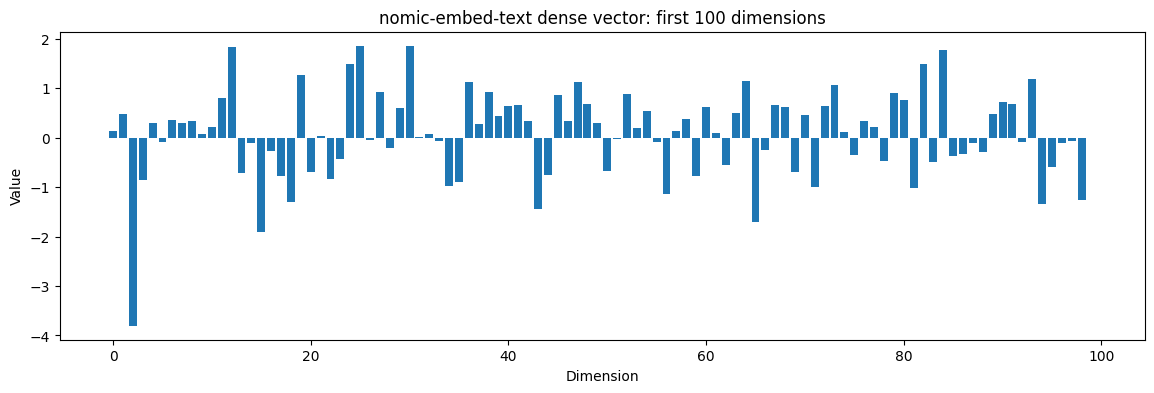

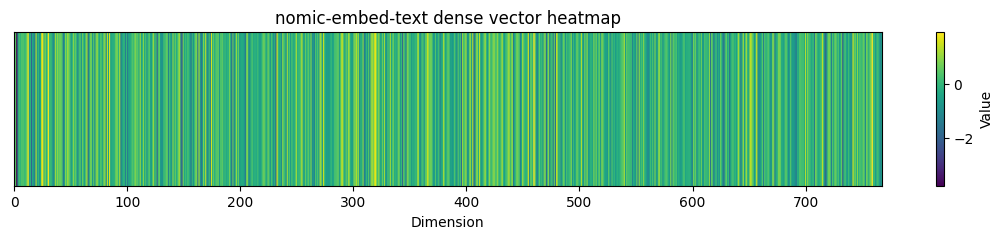

In [2]:
import requests
import numpy as np
import matplotlib.pyplot as plt

text = """A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS."""

response = requests.post(
    "http://localhost:11434/api/embeddings",
    json={
        "model": "nomic-embed-text:latest",
        "prompt": text,
    },
)

response.raise_for_status()

vec = np.array(response.json()["embedding"])

print("=== Dense vector ===")
print("Model: nomic-embed-text:latest")
print("Vector shape:", vec.shape)
print("Number of dimensions:", len(vec))
print("Text:", text)
print("Length of text:", len(text))
print("First 20 values:")
print(vec[:20])

print("\n=== Dense vector stats ===")
print("Min:", vec.min())
print("Max:", vec.max())
print("Mean:", vec.mean())
print("Non-zero values:", np.count_nonzero(vec))
print("Zero values:", len(vec) - np.count_nonzero(vec))

# Plot first 100 dimensions
n = 100

plt.figure(figsize=(14, 4))
plt.bar(range(n), vec[:n])
plt.title(f"nomic-embed-text dense vector: first {n} dimensions")
plt.xlabel("Dimension")
plt.ylabel("Value")
plt.show()

# Heatmap-like visualization
plt.figure(figsize=(14, 2))
plt.imshow(vec.reshape(1, -1), aspect="auto")
plt.title("nomic-embed-text dense vector heatmap")
plt.xlabel("Dimension")
plt.yticks([])
plt.colorbar(label="Value")
plt.show()

# Judge-Robust RAG Weakness Analysis

This section compares the same RAG outputs judged by `qwen2.5:7b` and `gpt-5.6-luna`. The goal is not to choose the best response model, but to find query categories where the RAG pipeline is reliably strong or weak across judges.

Use the judge-robust averages as the main signal. Use judge disagreement as a caution flag: when judges disagree strongly, avoid over-interpreting model/category deltas without manual review.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", context="notebook")
except ImportError:
    sns = None
    plt.style.use("seaborn-v0_8-whitegrid")

RETRIEVAL_SCOPE_LABELS = {
    "all_papers": "All papers",
    "specific_paper": "Paper specific",
}

JUDGE_COMPARISION_FILES = {
    # All-paper retrieval results: v3 and v4
    ("Llama", "Qwen 2.5 7B", "all_papers"): Path("results_v3/llama_3_2_3b__qwen2_5_7b.csv"),
    ("MedLlama", "Qwen 2.5 7B", "all_papers"): Path("results_v3/medllama_2_7b__qwen2_5_7b.csv"),
    ("Llama", "GPT-5.6 Luna", "all_papers"): Path("results_v4/llama_3_2b__gpt_5_6_luna.csv"),
    ("MedLlama", "GPT-5.6 Luna", "all_papers"): Path("results_v4/medllama_2_7b__gpt_5_6_luna.csv"),

    # Paper-specific retrieval results: v5 and v6
    ("Llama", "GPT-5.6 Luna", "specific_paper"): Path("results_v5/llama_3_2b__gpt_5_6_luna.csv"),
    ("MedLlama", "GPT-5.6 Luna", "specific_paper"): Path("results_v5/medllama_2_7b__gpt_5_6_luna.csv"),
    ("Llama", "Qwen 2.5 7B", "specific_paper"): Path("results_v6/llama_3_2b__qwen_2_5_7b.csv"),
    ("MedLlama", "Qwen 2.5 7B", "specific_paper"): Path("results_v6/medllama_2_7b__qwen_2_5_7b.csv"),
}

# Backward-compatible spelling for future cells/scripts that use the corrected name.
JUDGE_COMPARISON_FILES = JUDGE_COMPARISION_FILES

frames = []
for (response_model, judge_model, retrieval_scope), file_path in JUDGE_COMPARISION_FILES.items():
    df = pd.read_csv(file_path)
    df["response_family"] = response_model
    df["judge_family"] = judge_model
    df["retrieval_scope"] = retrieval_scope
    df["retrieval_scope_label"] = RETRIEVAL_SCOPE_LABELS[retrieval_scope]
    df["run_label"] = f"{response_model} judged by {judge_model} ({RETRIEVAL_SCOPE_LABELS[retrieval_scope]})"
    frames.append(df)

judge_results = pd.concat(frames, ignore_index=True)
judge_results["is_correct"] = judge_results["is_correct"].astype(bool)
judge_results.head()


,query_id,eval_unit,paper_index,article_id,article_title,reference_section,reference_status,source_row,api_latency_seconds,retrieved_context_count,...,min_paper_correctness,all_papers_correct,query_outcome,response_model,judge_model,embedding_model,response_family,judge_family,retrieval_scope_label,run_label
0,1,paper,1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,Methods,reported,2,91.713876,1,...,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama,Qwen 2.5 7B,All papers,Llama judged by Qwen 2.5 7B (All papers)
1,1,paper,2,s12933-023-02041-w,Association between triglyceride-glucose index...,Methods,reported,41,91.713876,1,...,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama,Qwen 2.5 7B,All papers,Llama judged by Qwen 2.5 7B (All papers)
2,1,paper,3,s12873-022-00582-z,Factors and machine learning models for predic...,"Abstract, Methods",reported,80,91.713876,2,...,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama,Qwen 2.5 7B,All papers,Llama judged by Qwen 2.5 7B (All papers)
3,1,paper,4,s12933-024-02265-4,Association between the stress hyperglycemia r...,Methods,reported,119,91.713876,1,...,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama,Qwen 2.5 7B,All papers,Llama judged by Qwen 2.5 7B (All papers)
4,1,paper,5,s40001-023-01593-7,Interpretable machine learning model for early...,Methods,reported,158,91.713876,1,...,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama,Qwen 2.5 7B,All papers,Llama judged by Qwen 2.5 7B (All papers)


## All-Paper Versus Paper-Specific Retrieval

Retrieval scope summary


,retrieval_scope_label,response_family,judge_family,mean_correctness,pass_rate,mean_context_recall,mean_context_precision,n,run_pair
0,All papers,Llama,GPT-5.6 Luna,0.506,0.066,0.404,0.746,457,Llama / GPT-5.6 Luna
4,Paper specific,Llama,GPT-5.6 Luna,0.518,0.051,0.494,0.821,39,Llama / GPT-5.6 Luna
1,All papers,Llama,Qwen 2.5 7B,0.449,0.074,0.541,0.775,457,Llama / Qwen 2.5 7B
5,Paper specific,Llama,Qwen 2.5 7B,0.454,0.077,0.535,0.744,39,Llama / Qwen 2.5 7B
2,All papers,MedLlama,GPT-5.6 Luna,0.518,0.028,0.411,0.755,457,MedLlama / GPT-5.6 Luna
6,Paper specific,MedLlama,GPT-5.6 Luna,0.512,0.000,0.553,0.872,39,MedLlama / GPT-5.6 Luna
3,All papers,MedLlama,Qwen 2.5 7B,0.521,0.048,0.541,0.775,457,MedLlama / Qwen 2.5 7B
7,Paper specific,MedLlama,Qwen 2.5 7B,0.457,0.026,0.543,0.744,39,MedLlama / Qwen 2.5 7B


Mean correctness delta by retrieval scope


retrieval_scope_label,All papers,Paper specific,Paper specific minus all papers
run_pair,,,
Llama / GPT-5.6 Luna,0.506,0.518,0.012
Llama / Qwen 2.5 7B,0.449,0.454,0.005
MedLlama / GPT-5.6 Luna,0.518,0.512,-0.006
MedLlama / Qwen 2.5 7B,0.521,0.457,-0.064


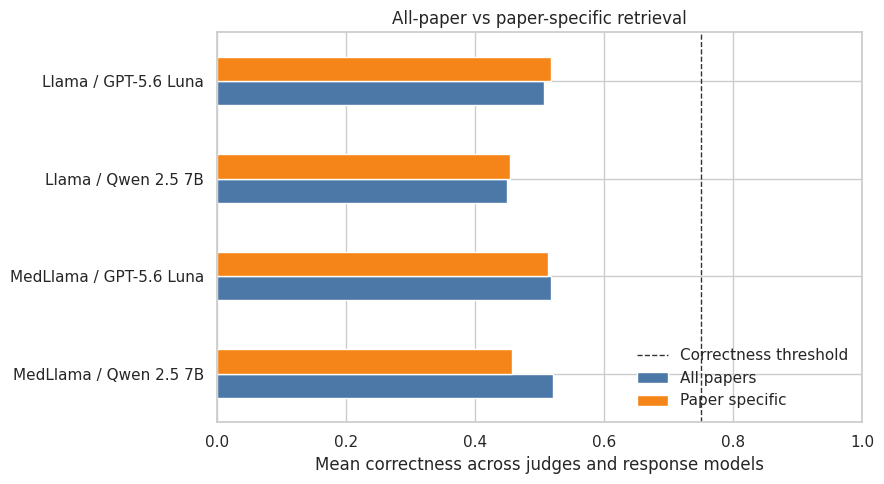

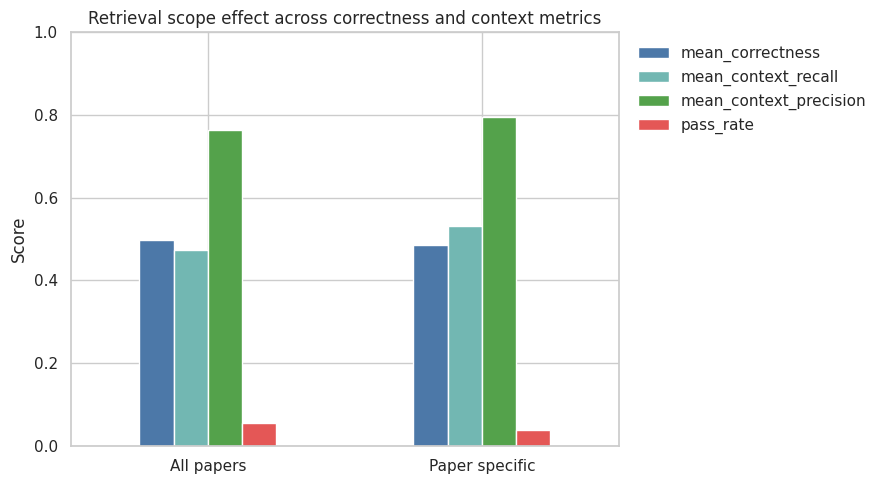

In [2]:
scope_summary = (
    judge_results.groupby(
        ["retrieval_scope_label", "response_family", "judge_family"],
        as_index=False,
    )
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        n=("correctness_score", "size"),
    )
)
scope_summary["run_pair"] = scope_summary["response_family"] + " / " + scope_summary["judge_family"]
scope_summary = scope_summary.sort_values(["run_pair", "retrieval_scope_label"])

print("Retrieval scope summary")
display(scope_summary.round(3))

scope_pivot = scope_summary.pivot(
    index="run_pair",
    columns="retrieval_scope_label",
    values="mean_correctness",
)
ordered_scope_cols = [
    col for col in ["All papers", "Paper specific"] if col in scope_pivot.columns
]
scope_pivot = scope_pivot[ordered_scope_cols]
if {"All papers", "Paper specific"}.issubset(scope_pivot.columns):
    scope_pivot["Paper specific minus all papers"] = (
        scope_pivot["Paper specific"] - scope_pivot["All papers"]
    )

print("Mean correctness delta by retrieval scope")
display(scope_pivot.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
scope_pivot[ordered_scope_cols].iloc[::-1].plot(
    kind="barh",
    ax=ax,
    color=["#4c78a8", "#f58518"][: len(ordered_scope_cols)],
)
ax.axvline(0.75, color="#333", linestyle="--", linewidth=1, label="Correctness threshold")
ax.set_xlim(0, 1)
ax.set_xlabel("Mean correctness across judges and response models")
ax.set_ylabel("")
ax.set_title("All-paper vs paper-specific retrieval")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

fig, ax = plt.subplots(figsize=(9, 5))
metric_scope_summary = (
    judge_results.groupby("retrieval_scope_label", as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        pass_rate=("is_correct", "mean"),
    )
    .set_index("retrieval_scope_label")
)
metric_scope_summary.loc[ordered_scope_cols].plot(
    kind="bar",
    ax=ax,
    color=["#4c78a8", "#72b7b2", "#54a24b", "#e45756"],
)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_title("Retrieval scope effect across correctness and context metrics")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()


## Comparing Across Models, Questions, And Question Groups

These plots compare mean correctness across response models, individual questions, and grouped question categories while preserving retrieval scope.


Model comparison by retrieval scope


,response_family,retrieval_scope_label,mean_correctness,pass_rate,mean_context_recall,mean_context_precision,n
0,Llama,All papers,0.478,0.070,0.473,0.760,914
1,Llama,Paper specific,0.486,0.064,0.514,0.782,78
2,MedLlama,All papers,0.519,0.038,0.476,0.765,914
3,MedLlama,Paper specific,0.484,0.013,0.548,0.808,78


Questions where paper-specific retrieval changes correctness most


,All papers,Paper specific,Paper specific minus all papers,question,category,field_id
query_id,,,,,,
11,0.633,0.210,-0.423,Which clinical domain or medical specialty bes...,cohort.clinical_domain,cohort
33,0.633,0.313,-0.321,Which performance metrics were used to evaluat...,evaluation.metrics,evaluation
18,0.383,0.098,-0.286,What period of patient data was used to constr...,window.observation,window
37,0.492,0.210,-0.282,Were model-interpretability or explainability ...,evaluation.explainability,evaluation
34,0.533,0.319,-0.214,What performance value was reported for each m...,evaluation.metrics_per_model,evaluation
39,0.349,0.181,-0.168,"Did the study evaluate fairness, subgroup perf...",evaluation.additional_analysis,evaluation
31,0.512,0.347,-0.165,"Was hyperparameter tuning performed? If so, wh...",model.tuning,modelling
17,0.372,0.266,-0.106,"For classification tasks, how many and what pe...",outcome.classbalance,outcome
2,0.606,0.504,-0.102,"Did the cohort include ICU patients, non-ICU p...",cohort.setting,cohort


,All papers,Paper specific,Paper specific minus all papers,question,category,field_id
query_id,,,,,,
38,0.476,0.712,0.236,Were statistical tests used to compare model p...,evaluation.stats_performance_comp,evaluation
12,0.550,0.779,0.228,What type of prediction target was used: class...,outcome.target_type,outcome
23,0.379,0.593,0.213,How many candidate and final input features we...,features.number,features
5,0.601,0.812,0.211,What were the cohort exclusion criteria? Repre...,cohort.exclusion,cohort
1,0.524,0.723,0.199,What patient population was included in the st...,cohort.overview,cohort
15,0.743,0.923,0.180,What clinical prediction task did the study ad...,outcome.prediction_task_category,outcome
10,0.503,0.683,0.180,How many admissions or ICU stays were included...,cohort.admission_count,cohort
35,0.479,0.651,0.171,Which model was identified as the best-perform...,evaluation.best_model,evaluation
7,0.629,0.792,0.163,"What was the unit of analysis, for example, pa...",cohort.unit,cohort


Question group comparison by retrieval scope


retrieval_scope_label,All papers,Paper specific,Paper specific minus all papers
question_group,,,
cohort / cohort.clinical_domain,0.633,0.210,-0.423
evaluation / evaluation.metrics,0.633,0.313,-0.321
window / window.observation,0.383,0.098,-0.286
evaluation / evaluation.explainability,0.492,0.210,-0.282
evaluation / evaluation.metrics_per_model,0.533,0.319,-0.214
evaluation / evaluation.additional_analysis,0.349,0.181,-0.168
modelling / model.tuning,0.512,0.347,-0.165
outcome / outcome.classbalance,0.372,0.266,-0.106
cohort / cohort.setting,0.606,0.504,-0.102


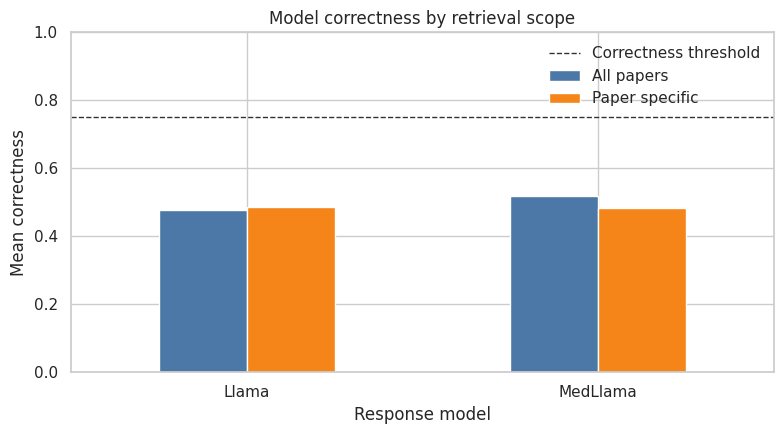

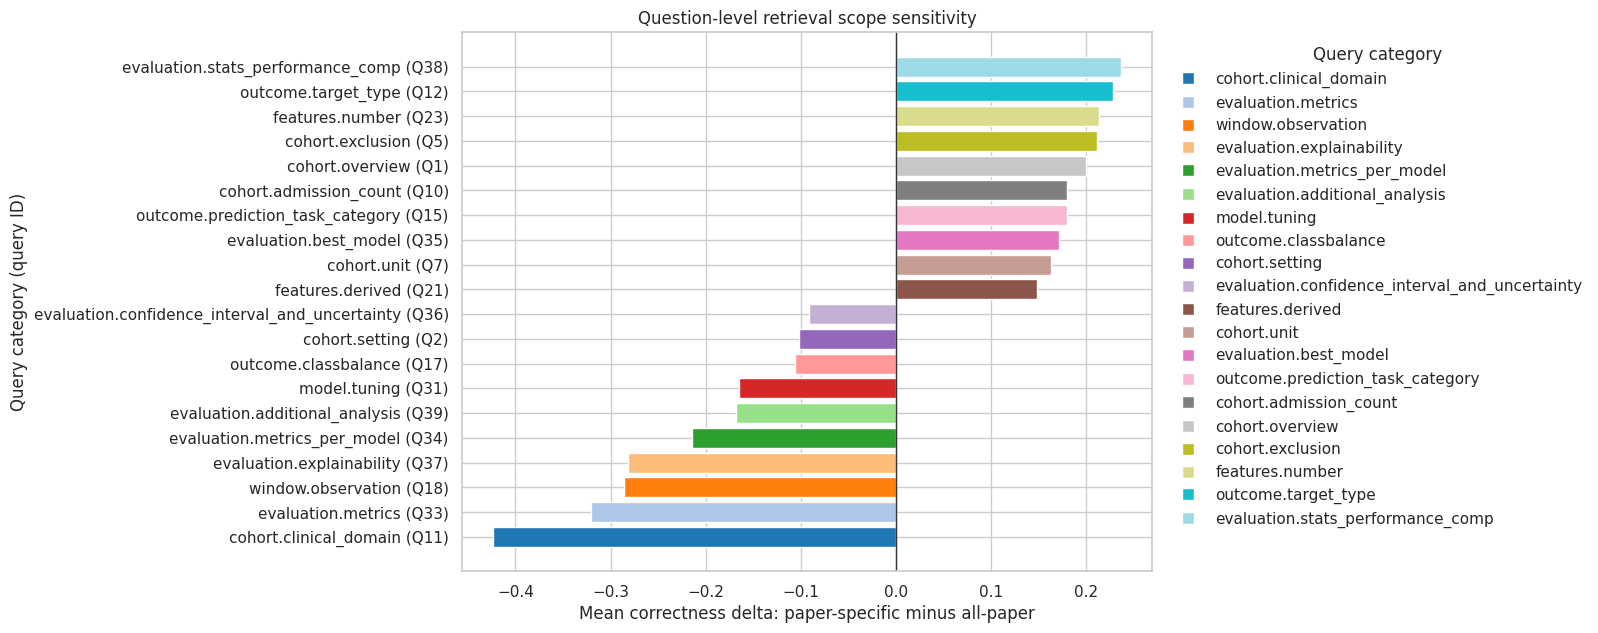

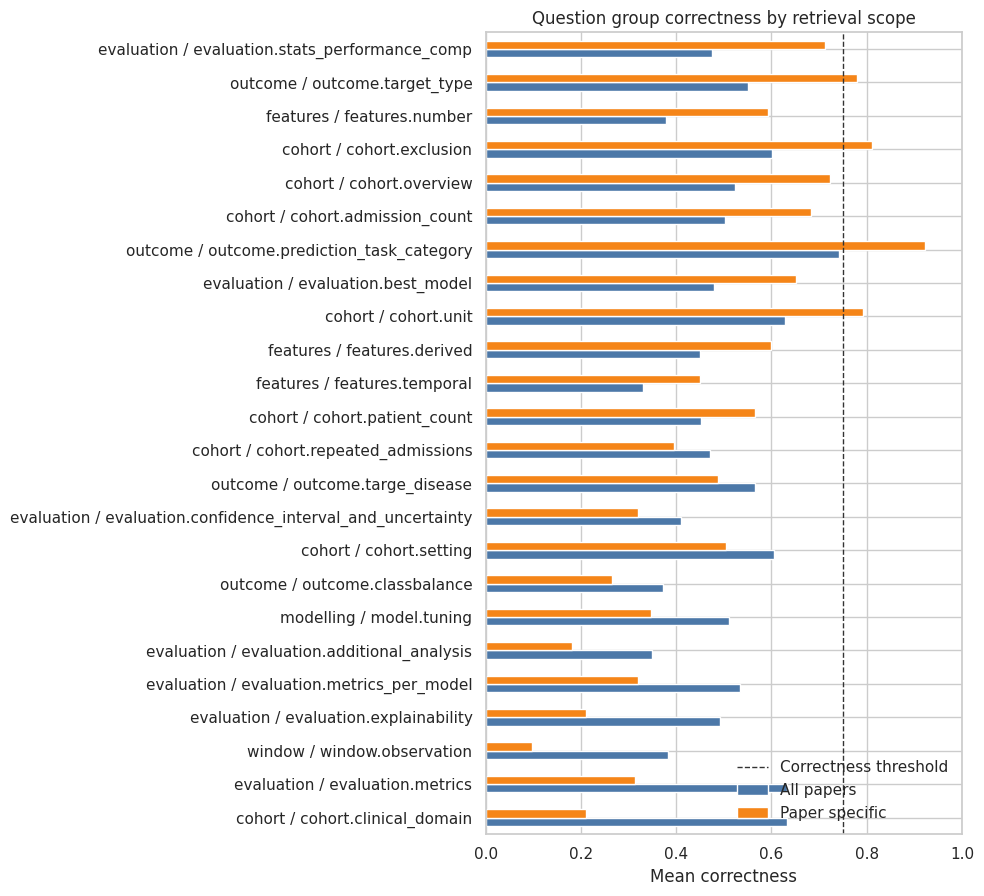

In [3]:
ordered_scope_cols = [
    col for col in ["All papers", "Paper specific"]
    if col in judge_results["retrieval_scope_label"].unique()
]

model_scope_summary = (
    judge_results.groupby(["response_family", "retrieval_scope_label"], as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        n=("correctness_score", "size"),
    )
)
model_scope_pivot = model_scope_summary.pivot(
    index="response_family",
    columns="retrieval_scope_label",
    values="mean_correctness",
)[ordered_scope_cols]

print("Model comparison by retrieval scope")
display(model_scope_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
model_scope_pivot.plot(
    kind="bar",
    ax=ax,
    color=["#4c78a8", "#f58518"][: len(ordered_scope_cols)],
)
ax.axhline(0.75, color="#333", linestyle="--", linewidth=1, label="Correctness threshold")
ax.set_ylim(0, 1)
ax.set_xlabel("Response model")
ax.set_ylabel("Mean correctness")
ax.set_title("Model correctness by retrieval scope")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()

question_summary = (
    judge_results.groupby(["query_id", "retrieval_scope_label"], as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        question=("user_input", "first"),
        category=("category", "first"),
        field_id=("field_id", "first"),
        n=("correctness_score", "size"),
    )
)
question_pivot = question_summary.pivot(
    index="query_id",
    columns="retrieval_scope_label",
    values="mean_correctness",
)[ordered_scope_cols]
if {"All papers", "Paper specific"}.issubset(question_pivot.columns):
    question_pivot["Paper specific minus all papers"] = (
        question_pivot["Paper specific"] - question_pivot["All papers"]
    )
question_meta = question_summary.drop_duplicates("query_id").set_index("query_id")[["question", "category", "field_id"]]
question_comparison = question_pivot.join(question_meta).sort_values(
    "Paper specific minus all papers" if "Paper specific minus all papers" in question_pivot.columns else ordered_scope_cols[0]
)

print("Questions where paper-specific retrieval changes correctness most")
display(question_comparison.round(3).head(12))
display(question_comparison.round(3).tail(12).sort_values("Paper specific minus all papers", ascending=False))

question_plot = pd.concat([
    question_comparison.head(10).assign(change_group="Paper specific lower"),
    question_comparison.tail(10).assign(change_group="Paper specific higher"),
]).drop_duplicates().sort_values("Paper specific minus all papers")
question_plot = question_plot.copy()
question_plot["plot_label"] = [
    f"{row.category} (Q{query_id})" for query_id, row in question_plot.iterrows()
]
plot_categories = question_plot["category"].dropna().unique()
category_palette = plt.get_cmap("tab20", len(plot_categories))
category_colors = {
    category: category_palette(i) for i, category in enumerate(plot_categories)
}

fig_height = max(6, 0.35 * len(question_plot))
fig, ax = plt.subplots(figsize=(12, fig_height))
ax.barh(
    question_plot["plot_label"],
    question_plot["Paper specific minus all papers"],
    color=question_plot["category"].map(category_colors),
)
ax.axvline(0, color="#333", linewidth=1)
ax.set_xlabel("Mean correctness delta: paper-specific minus all-paper")
ax.set_ylabel("Query category (query ID)")
ax.set_title("Question-level retrieval scope sensitivity")
legend_handles = [
    plt.Line2D([0], [0], marker="s", color="w", label=category, markerfacecolor=color, markersize=8)
    for category, color in category_colors.items()
]
ax.legend(handles=legend_handles, title="Query category", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.subplots_adjust(right=0.70)

question_group_summary = (
    judge_results.groupby(["field_id", "category", "retrieval_scope_label"], as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        n=("correctness_score", "size"),
    )
)
question_group_summary["question_group"] = (
    question_group_summary["field_id"].astype(str) + " / " + question_group_summary["category"].astype(str)
)
question_group_pivot = question_group_summary.pivot(
    index="question_group",
    columns="retrieval_scope_label",
    values="mean_correctness",
)[ordered_scope_cols]
if {"All papers", "Paper specific"}.issubset(question_group_pivot.columns):
    question_group_pivot["Paper specific minus all papers"] = (
        question_group_pivot["Paper specific"] - question_group_pivot["All papers"]
    )
question_group_pivot = question_group_pivot.sort_values(
    "Paper specific minus all papers" if "Paper specific minus all papers" in question_group_pivot.columns else ordered_scope_cols[0]
)

print("Question group comparison by retrieval scope")
display(question_group_pivot.round(3))

group_plot = pd.concat([
    question_group_pivot.head(12),
    question_group_pivot.tail(12),
]).drop_duplicates().sort_values("Paper specific minus all papers")

fig_height = max(7, 0.38 * len(group_plot))
fig, ax = plt.subplots(figsize=(10, fig_height))
group_plot[ordered_scope_cols].plot(
    kind="barh",
    ax=ax,
    color=["#4c78a8", "#f58518"][: len(ordered_scope_cols)],
)
ax.axvline(0.75, color="#333", linestyle="--", linewidth=1, label="Correctness threshold")
ax.set_xlim(0, 1)
ax.set_xlabel("Mean correctness")
ax.set_ylabel("")
ax.set_title("Question group correctness by retrieval scope")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()


## Judge-Robust Category Ranking

This ranks categories by average correctness across both response models and both judges, then compares all-paper retrieval against paper-specific retrieval side by side. Categories at the bottom are the most reliable RAG weaknesses because they stay weak even when the judge changes.


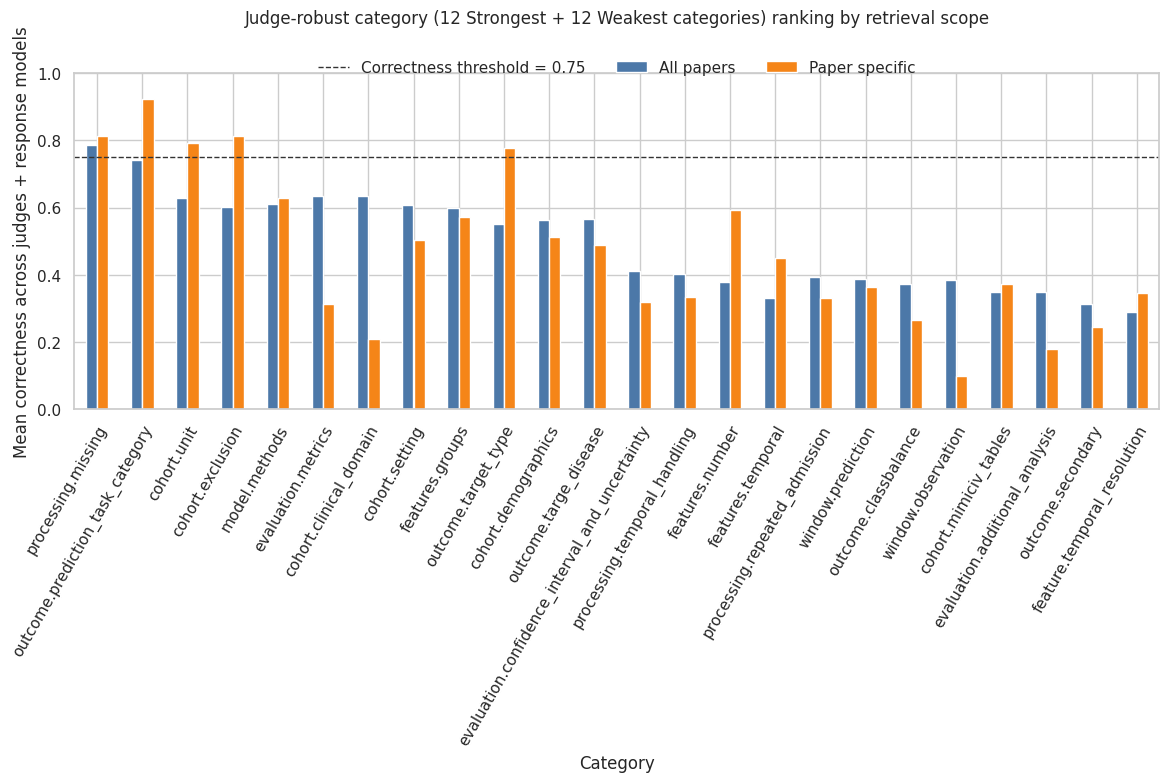

Saved: presentation_plots/02_category_ranking_by_retrieval_scope.png
Saved: presentation_plots/02_category_ranking_by_retrieval_scope.pdf


In [4]:
# PPT export: category ranking by retrieval scope
# This cell recreates presentation_plots/02_category_ranking_by_retrieval_scope
# from the judge-comparison CSVs loaded in JUDGE_COMPARISION_FILES.

OUTPUT_DIR = Path("presentation_plots")
OUTPUT_DIR.mkdir(exist_ok=True)

def export_category_ranking_by_retrieval_scope(
    judge_results: pd.DataFrame,
    output_dir: Path = OUTPUT_DIR,
    weakest_n: int = 12,
    strongest_n: int = 12,
    threshold: float = 0.75,
) -> pd.DataFrame:
    robust_category = (
        judge_results.groupby("category", as_index=False)
        .agg(mean_correctness=("correctness_score", "mean"))
        .sort_values("mean_correctness")
    )

    scope_category = (
        judge_results.groupby(["category", "retrieval_scope_label"], as_index=False)
        .agg(mean_correctness=("correctness_score", "mean"))
    )

    scope_category_pivot = scope_category.pivot(
        index="category",
        columns="retrieval_scope_label",
        values="mean_correctness",
    )
    ordered_scope_cols = [
        col for col in ["All papers", "Paper specific"]
        if col in scope_category_pivot.columns
    ]

    selected_categories = pd.Index(
        robust_category.head(weakest_n)["category"].tolist()
        + robust_category.tail(strongest_n)["category"].tolist()
    ).drop_duplicates()

    plot_df = (
        scope_category_pivot.reindex(selected_categories)
        .dropna(how="all", subset=ordered_scope_cols)
        .iloc[::-1]
    )

    fig_width = max(14, 0.55 * len(plot_df))
    fig, ax = plt.subplots(figsize=(fig_width, 7))
    plot_df[ordered_scope_cols].plot(
        kind="bar",
        ax=ax,
        color=["#4c78a8", "#f58518"][: len(ordered_scope_cols)],
    )
    ax.axhline(
        threshold,
        color="#333",
        linestyle="--",
        linewidth=1,
        label=f"Correctness threshold = {threshold:.2f}",
    )
    ax.set_xlabel("Category")
    ax.set_ylabel("Mean correctness across judges + response models")
    ax.set_ylim(0, 1)
    ax.set_title("Judge-robust category (12 Strongest + 12 Weakest categories) ranking by retrieval scope", pad=36)
    ax.set_xticks(range(len(plot_df.index)))
    ax.set_xticklabels(plot_df.index, rotation=60, ha="right", rotation_mode="anchor")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=3)
    fig.subplots_adjust(bottom=0.36, top=0.84)

    png_path = output_dir / "02_category_ranking_by_retrieval_scope.png"
    pdf_path = output_dir / "02_category_ranking_by_retrieval_scope.pdf"
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.show()

    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")
    return plot_df

category_ranking_plot_df = export_category_ranking_by_retrieval_scope(judge_results)



Most difficult categories across both judges, response models, and retrieval scopes


,category,mean_correctness,median_correctness,pass_rate,mean_context_recall,mean_context_precision,n
18,feature.temporal_resolution,0.293,0.258,0.000,0.219,0.231,52
30,outcome.secondary,0.309,0.258,0.000,0.308,0.615,52
11,evaluation.additional_analysis,0.336,0.322,0.000,0.377,0.673,52
5,cohort.mimiciv_tables,0.351,0.333,0.000,0.506,0.865,52
37,window.observation,0.361,0.333,0.000,0.286,0.423,52
27,outcome.classbalance,0.364,0.339,0.000,0.446,0.558,52
38,window.prediction,0.387,0.334,0.000,0.311,0.692,52
34,processing.repeated_admission,0.388,0.375,0.019,0.615,0.712,52
22,features.temporal,0.390,0.475,0.000,0.250,1.000,8
21,features.number,0.396,0.333,0.000,0.417,0.481,52


Best answered categories across both judges, response models, and retrieval scopes


,category,mean_correctness,median_correctness,pass_rate,mean_context_recall,mean_context_precision,n
33,processing.missing,0.789,0.833,0.423,0.836,1.000,52
28,outcome.prediction_task_category,0.757,0.838,0.192,0.696,0.962,52
10,cohort.unit,0.642,0.667,0.077,0.654,1.000,52
3,cohort.exclusion,0.617,0.748,0.135,0.603,0.769,52
24,model.methods,0.612,0.630,0.019,0.447,0.808,52
15,evaluation.metrics,0.609,0.667,0.000,0.405,0.885,52
1,cohort.clinical_domain,0.601,0.590,0.154,0.641,0.962,52
9,cohort.setting,0.599,0.648,0.000,0.612,0.981,52
20,features.groups,0.596,0.607,0.019,0.376,0.962,52
32,outcome.target_type,0.568,0.556,0.077,0.619,0.885,52


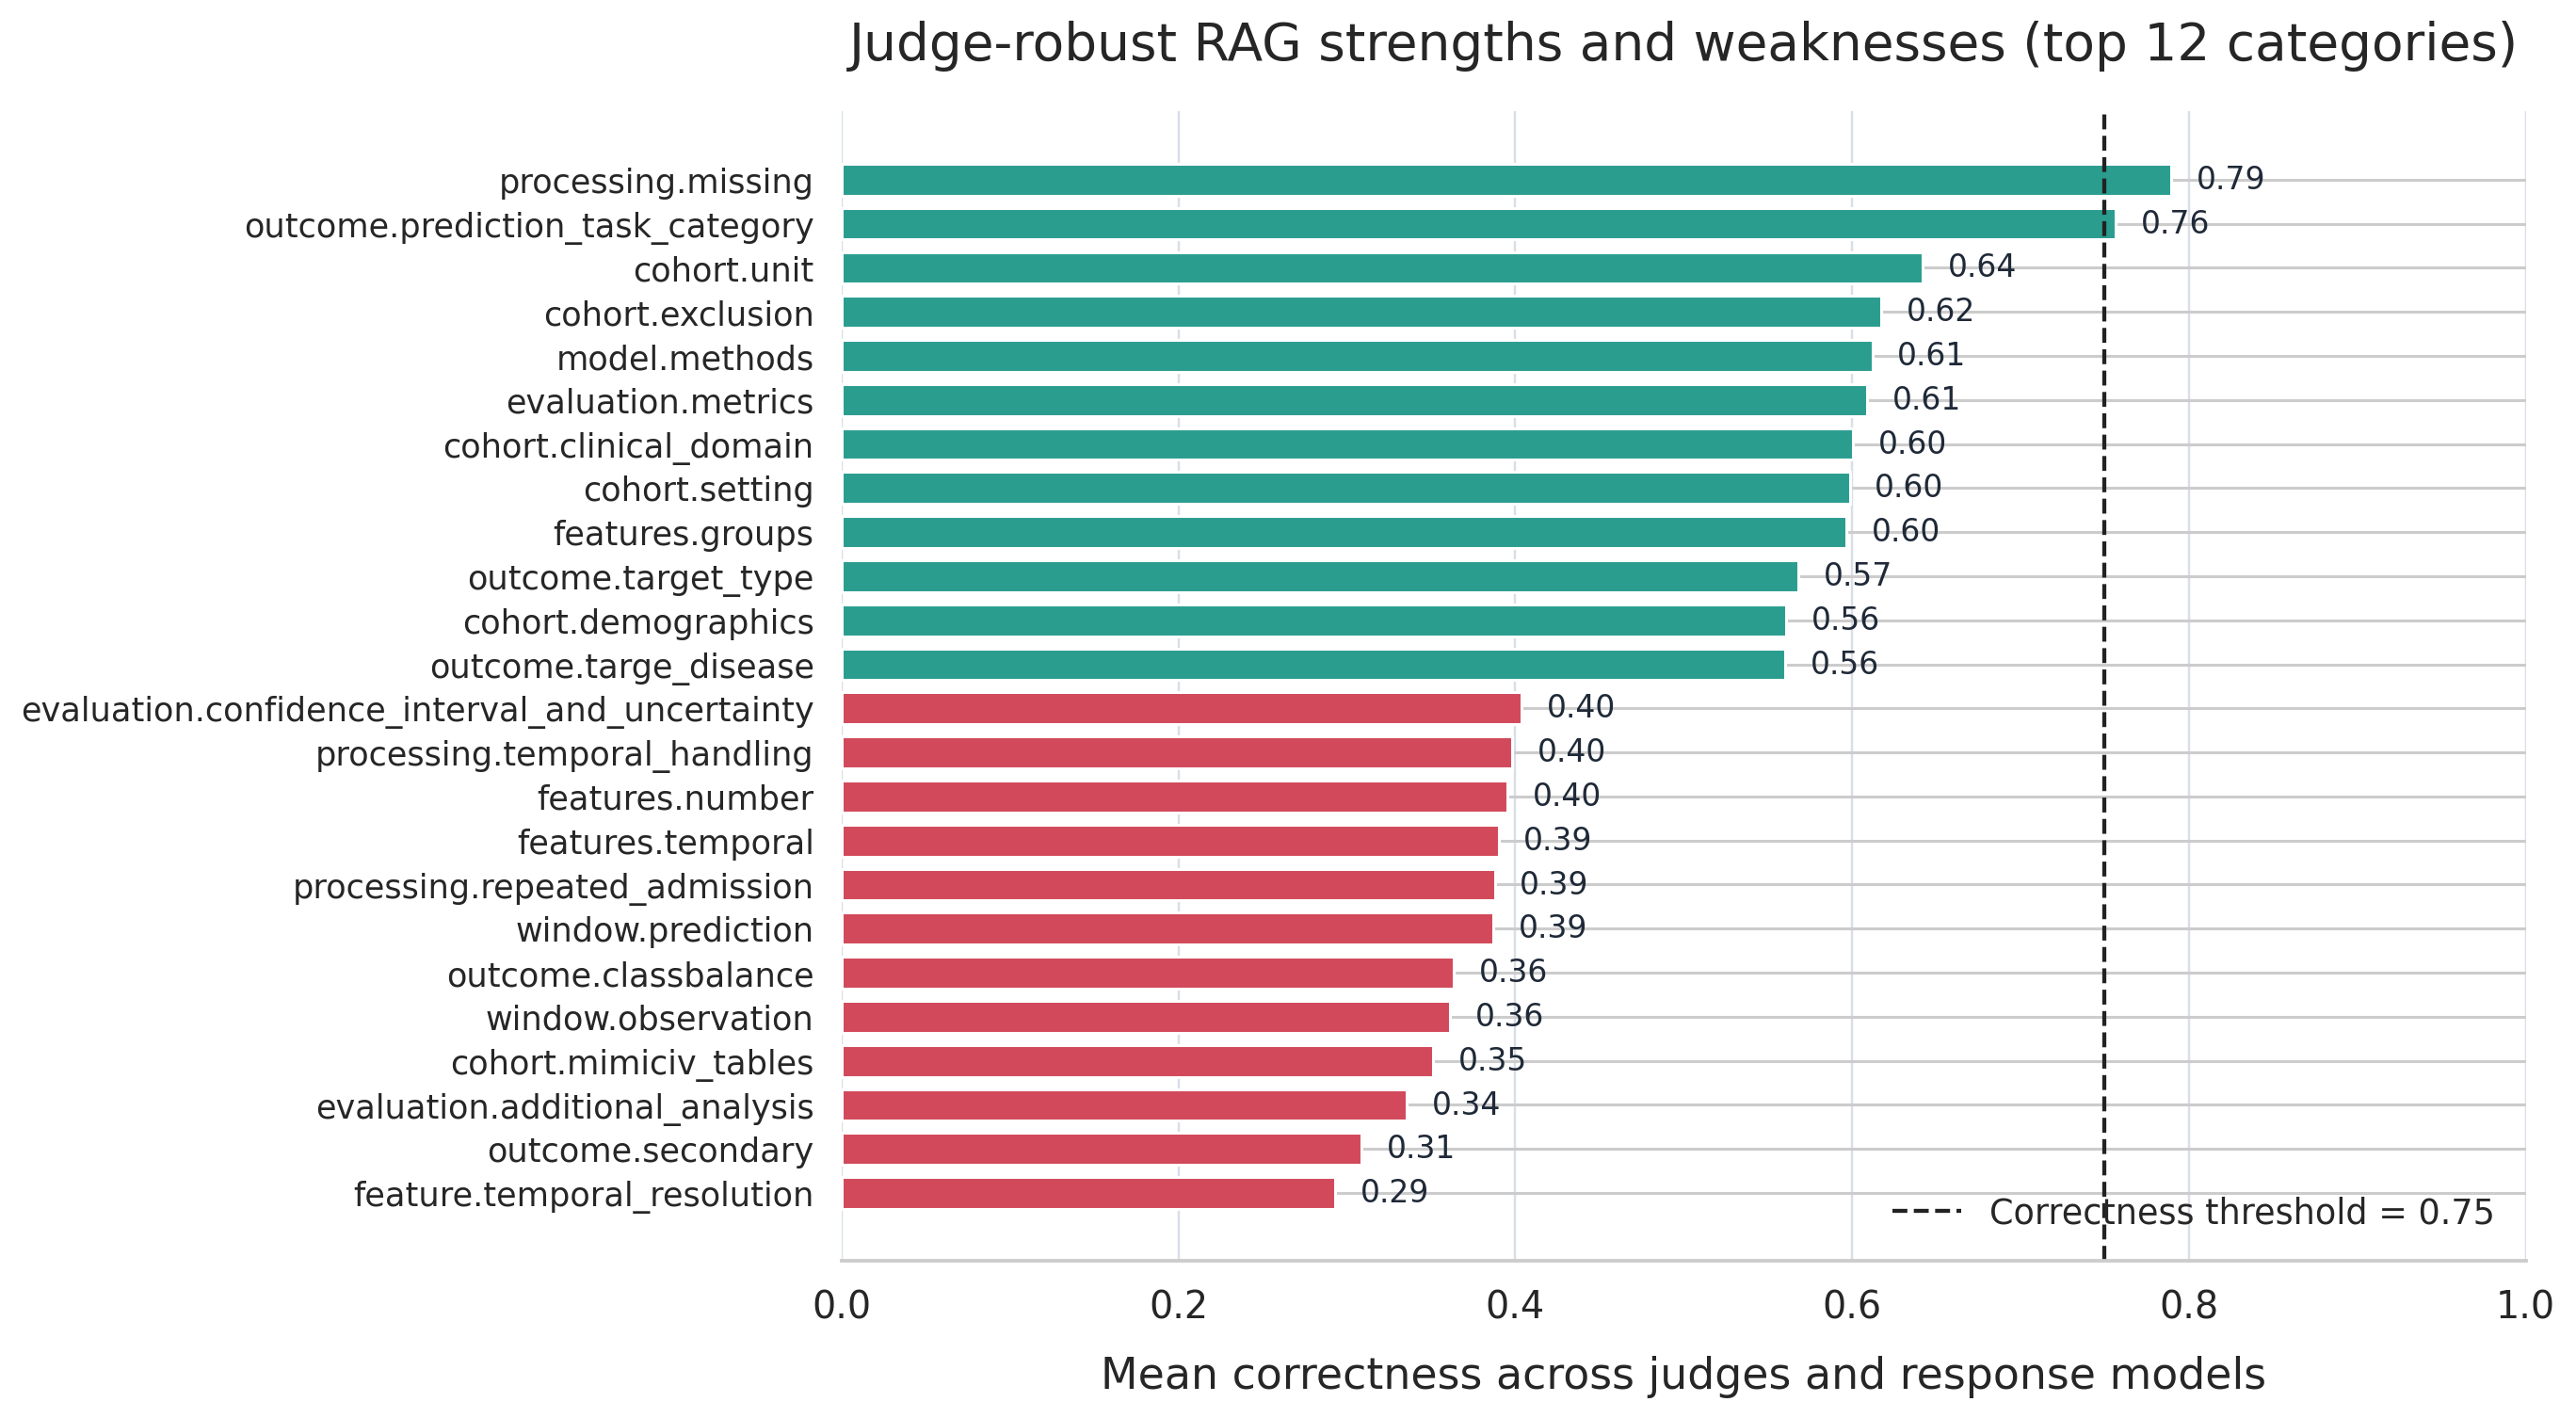

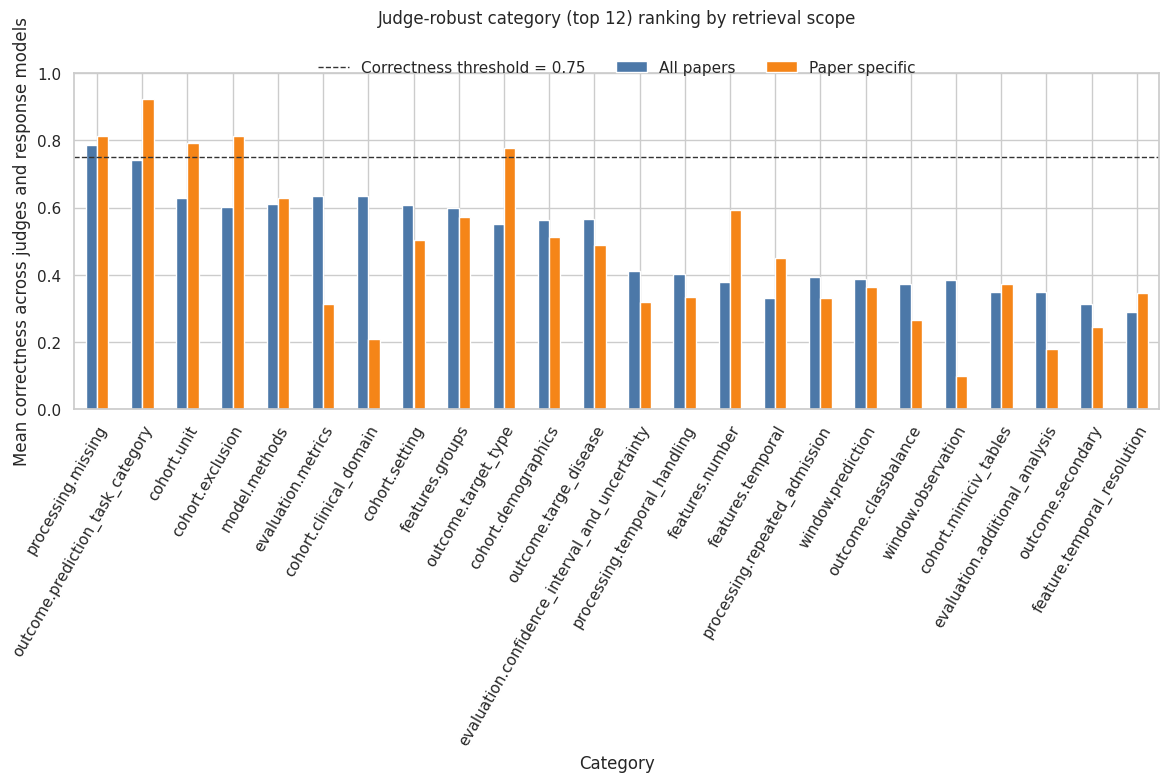

In [10]:
robust_category = (
    judge_results.groupby("category", as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        median_correctness=("correctness_score", "median"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        n=("correctness_score", "size"),
    )
    .sort_values("mean_correctness")
)

scope_category = (
    judge_results.groupby(["category", "retrieval_scope_label"], as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        n=("correctness_score", "size"),
    )
)

scope_category_pivot = scope_category.pivot(
    index="category",
    columns="retrieval_scope_label",
    values="mean_correctness",
)
ordered_scope_cols = [
    col for col in ["All papers", "Paper specific"] if col in scope_category_pivot.columns
]
scope_category_pivot = scope_category_pivot[ordered_scope_cols]
if {"All papers", "Paper specific"}.issubset(scope_category_pivot.columns):
    scope_category_pivot["Paper specific minus all papers"] = (
        scope_category_pivot["Paper specific"] - scope_category_pivot["All papers"]
    )

print("Most difficult categories across both judges, response models, and retrieval scopes")
display(robust_category.head(12).round(3))

print("Best answered categories across both judges, response models, and retrieval scopes")
display(robust_category.tail(12).sort_values("mean_correctness", ascending=False).round(3))

def wrap_category_labels(labels, width=34):
    import textwrap

    return ["\n".join(textwrap.wrap(str(label), width=width, break_long_words=False)) for label in labels]

OUTPUT_DIR = Path("presentation_plots")
OUTPUT_DIR.mkdir(exist_ok=True)

overall_plot_df = pd.concat([
    robust_category.head(12).assign(group="Weakest"),
    robust_category.tail(12).assign(group="Strongest"),
]).drop_duplicates(subset="category").sort_values("mean_correctness", ascending=True)

overall_plot_df = overall_plot_df.copy()
overall_plot_df["plot_label"] = wrap_category_labels(overall_plot_df["category"], width=38)

fig, ax = plt.subplots(figsize=(13.33, 7.5), dpi=220)
bar_colors = np.where(overall_plot_df["group"].eq("Strongest"), "#2a9d8f", "#d1495b")
bars = ax.barh(overall_plot_df["plot_label"], overall_plot_df["mean_correctness"], color=bar_colors, height=0.72)
ax.axvline(0.75, color="#222", linestyle="--", linewidth=1.4, label="Correctness threshold = 0.75")
ax.set_xlabel("Mean correctness across judges and response models", fontsize=15, labelpad=10)
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.set_title("Judge-robust RAG strengths and weaknesses (top 12 categories)", fontsize=18, pad=18)
ax.tick_params(axis="x", labelsize=13)
ax.tick_params(axis="y", labelsize=11.5)
ax.grid(axis="x", color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False, loc="lower right", fontsize=12)

for bar, value in zip(bars, overall_plot_df["mean_correctness"]):
    ax.text(
        min(value + 0.015, 0.98),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        ha="left" if value < 0.94 else "right",
        fontsize=10.8,
        color="#1f2937",
    )

fig.subplots_adjust(left=0.36, right=0.97, bottom=0.14, top=0.88)
fig.savefig(OUTPUT_DIR / "03_judge_robust_strengths_weaknesses.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "03_judge_robust_strengths_weaknesses.pdf", bbox_inches="tight")
plt.show()

selected_categories = pd.Index(
    robust_category.head(12)["category"].tolist()
    + robust_category.tail(12)["category"].tolist()
).drop_duplicates()
plot_df = (
    scope_category_pivot.reindex(selected_categories)
    .dropna(how="all", subset=ordered_scope_cols)
    .iloc[::-1]
)

fig_width = max(14, 0.55 * len(plot_df))
fig, ax = plt.subplots(figsize=(fig_width, 7))
plot_df[ordered_scope_cols].plot(
    kind="bar",
    ax=ax,
    color=["#4c78a8", "#f58518"][: len(ordered_scope_cols)],
)
ax.axhline(0.75, color="#333", linestyle="--", linewidth=1, label="Correctness threshold = 0.75")
ax.set_xlabel("Category")
ax.set_ylabel("Mean correctness across judges and response models")
ax.set_ylim(0, 1)
ax.set_title("Judge-robust category (top 12) ranking by retrieval scope", pad=36)
ax.set_xticks(range(len(plot_df.index)))
ax.set_xticklabels(plot_df.index, rotation=60, ha="right", rotation_mode="anchor")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=3)
fig.subplots_adjust(bottom=0.36, top=0.84)



## Field-Level Weakness

This compresses categories into broader extraction fields. It shows whether the RAG system struggles more with cohort, features, outcomes, processing, modelling, or time-window questions.

,field_id,mean_correctness,pass_rate,mean_context_recall,mean_context_precision,n,field_label
6,window,0.374,0.000,0.298,0.558,104,Window
2,features,0.435,0.005,0.338,0.625,216,Features
1,evaluation,0.475,0.036,0.384,0.736,364,Evaluation
5,processing,0.511,0.130,0.526,0.798,208,Processing
4,outcome,0.514,0.048,0.533,0.795,312,Outcome
3,modelling,0.530,0.048,0.521,0.861,208,Modelling
0,cohort,0.532,0.068,0.563,0.811,572,Cohort


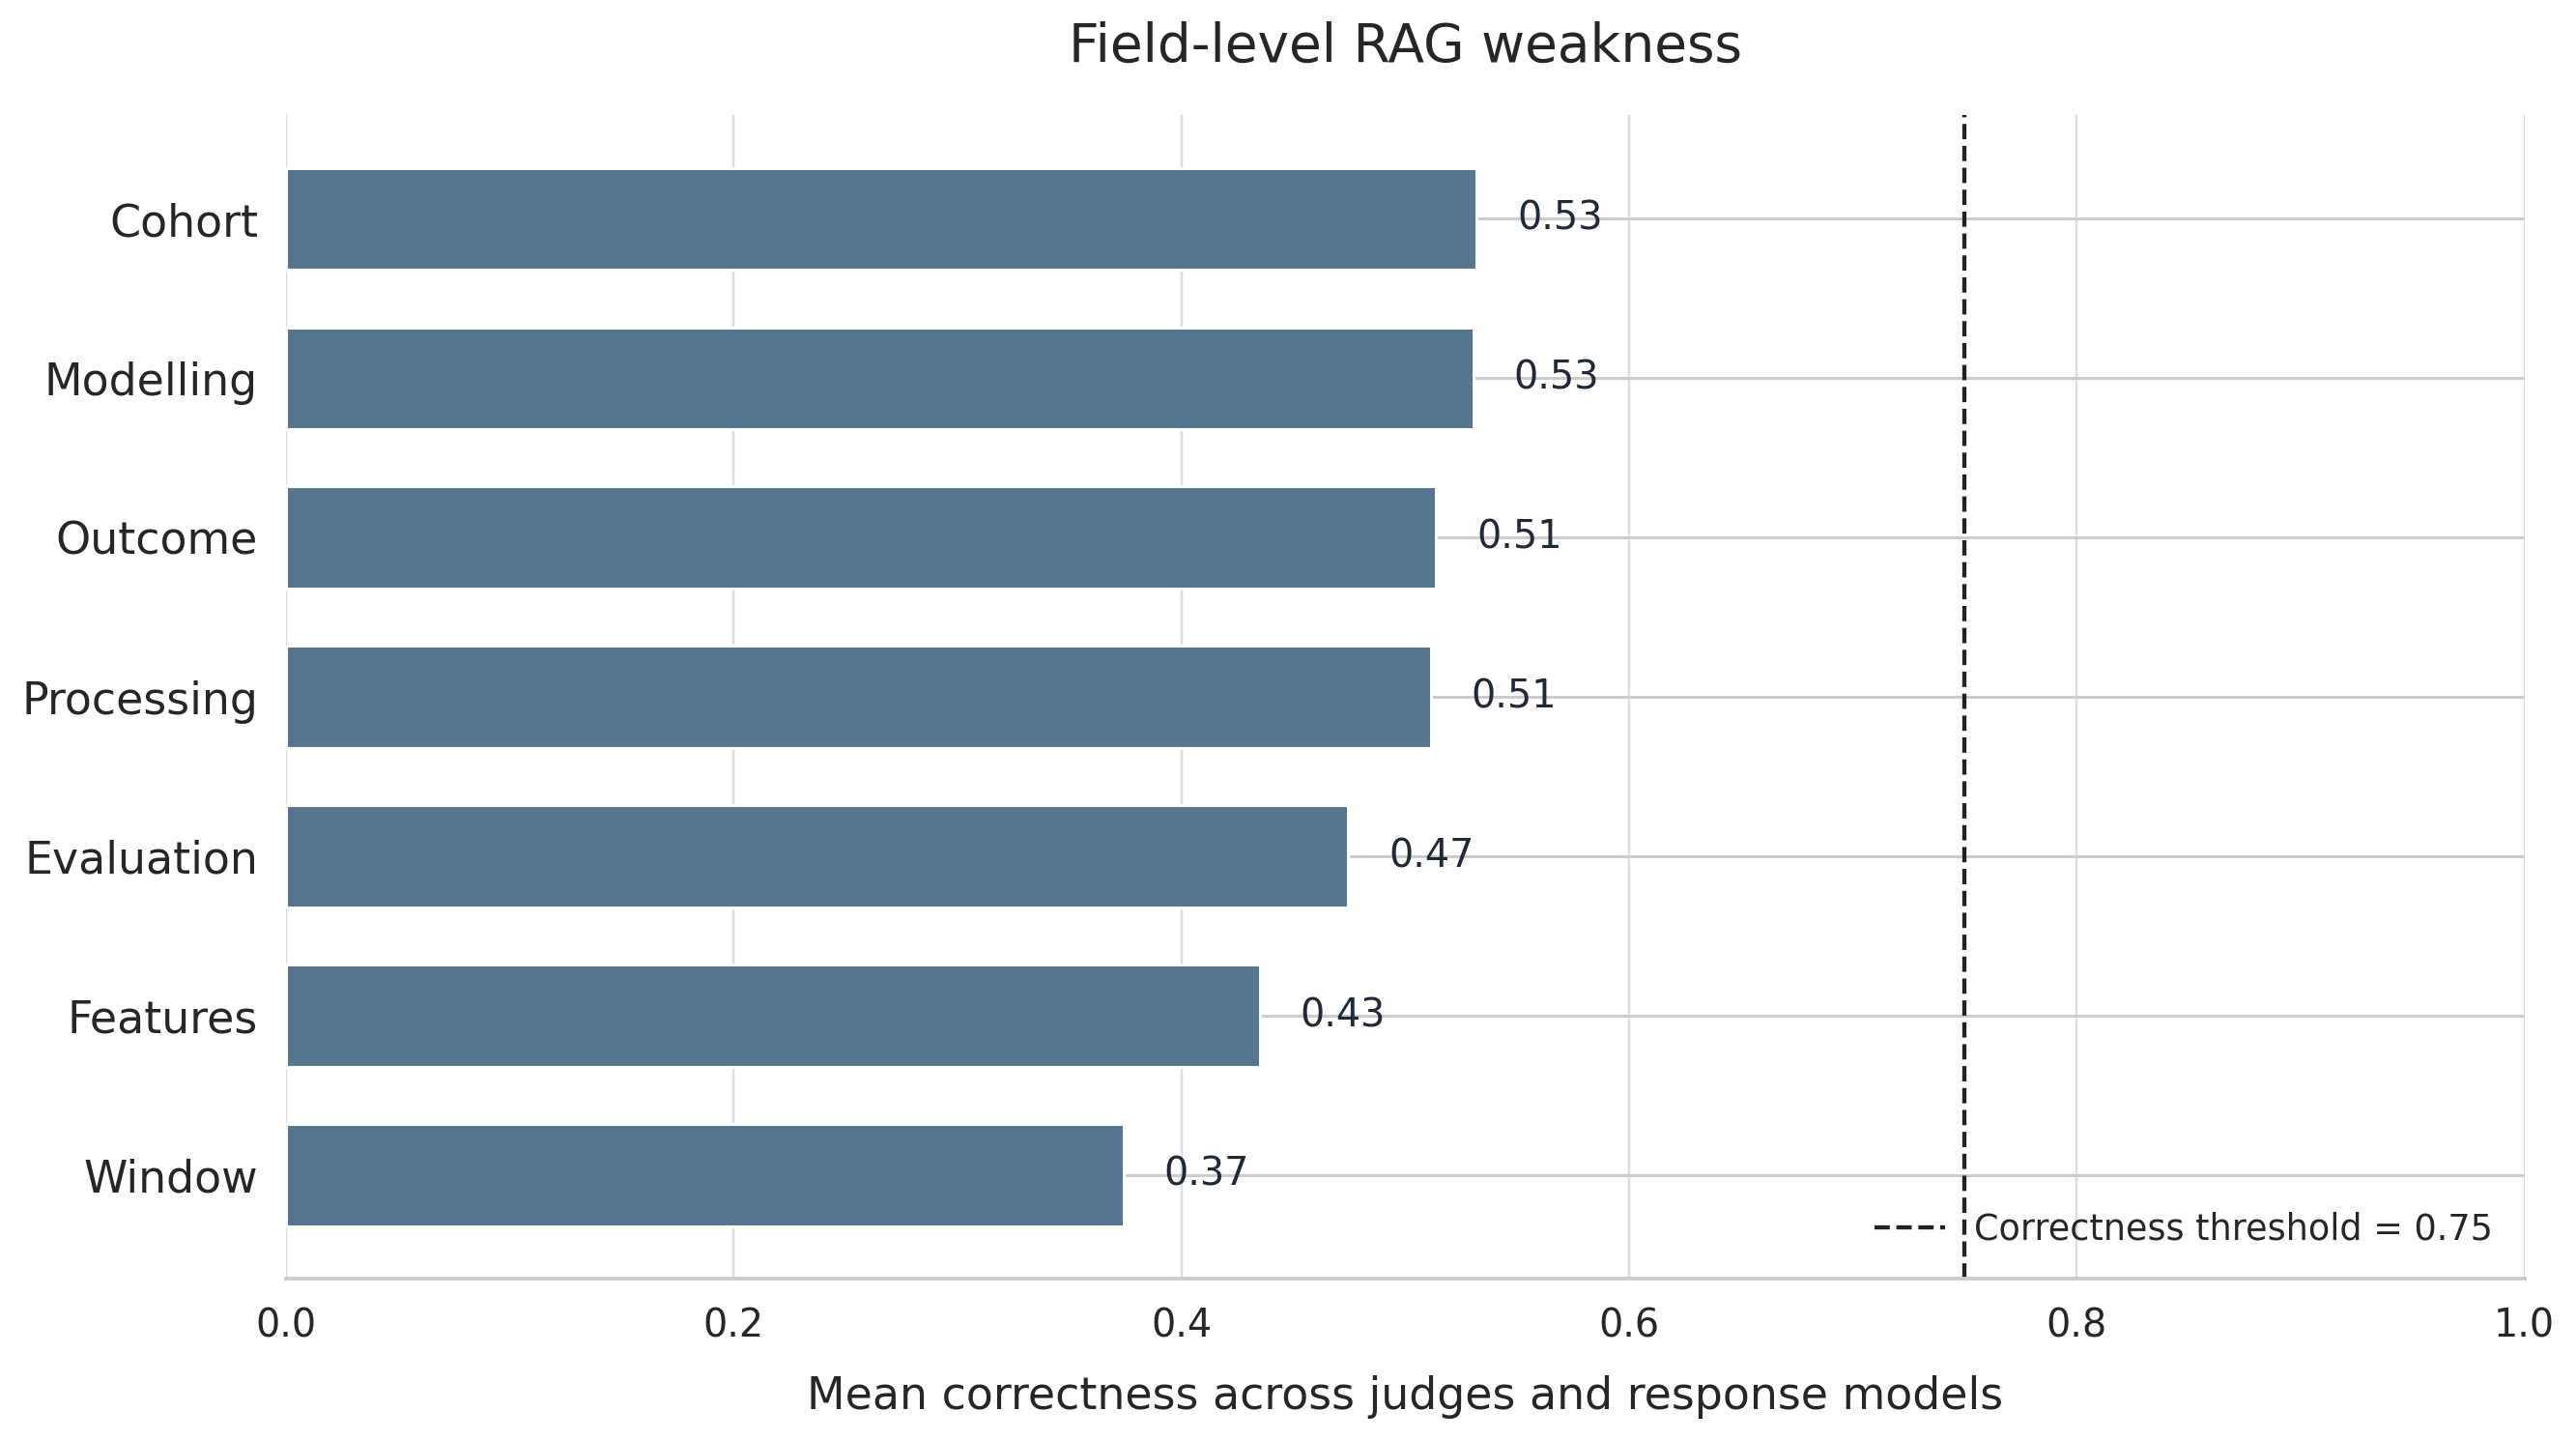

In [6]:
field_summary = (
    judge_results.groupby("field_id", as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        n=("correctness_score", "size"),
    )
    .sort_values("mean_correctness")
)

field_summary["field_label"] = field_summary["field_id"].astype(str).str.replace("_", " ").str.title()

display(field_summary.round(3))

OUTPUT_DIR = Path("presentation_plots")
OUTPUT_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(13.33, 7.5), dpi=220)
bars = ax.barh(field_summary["field_label"], field_summary["mean_correctness"], color="#577590", height=0.64)
ax.axvline(0.75, color="#222", linestyle="--", linewidth=1.4, label="Correctness threshold = 0.75")
ax.set_xlim(0, 1)
ax.set_xlabel("Mean correctness across judges and response models", fontsize=15, labelpad=10)
ax.set_ylabel("")
ax.set_title("Field-level RAG weakness", fontsize=18, pad=18)
ax.tick_params(axis="x", labelsize=13)
ax.tick_params(axis="y", labelsize=15)
ax.grid(axis="x", color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False, loc="lower right", fontsize=12)

for bar, value in zip(bars, field_summary["mean_correctness"]):
    ax.text(
        min(value + 0.018, 0.98),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        ha="left" if value < 0.94 else "right",
        fontsize=13,
        color="#1f2937",
    )

fig.subplots_adjust(left=0.18, right=0.97, bottom=0.15, top=0.88)
fig.savefig(OUTPUT_DIR / "04_field_level_weakness.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "04_field_level_weakness.pdf", bbox_inches="tight")
plt.show()



## Judge Disagreement

These categories should be treated carefully. A large judge delta means conclusions depend heavily on whether Qwen or GPT-Luna is judging. Stable hard/easy categories are more useful for diagnosing RAG behavior.

Categories with largest judge disagreement


judge_family,GPT-5.6 Luna,Qwen 2.5 7B,GPT-Luna minus Qwen,absolute_judge_delta
category,,,,
cohort.repeated_admissions,0.597,0.333,0.264,0.264
evaluation.stats_performance_comp,0.600,0.387,0.213,0.213
processing.repeated_admission,0.475,0.301,0.174,0.174
cohort.inclusion,0.432,0.567,-0.135,0.135
cohort.admission_count,0.582,0.452,0.130,0.130
processing.temporal_handling,0.463,0.333,0.130,0.130
cohort.unit,0.586,0.697,-0.111,0.111
features.groups,0.544,0.649,-0.106,0.106
cohort.mimiciv_tables,0.403,0.299,0.104,0.104


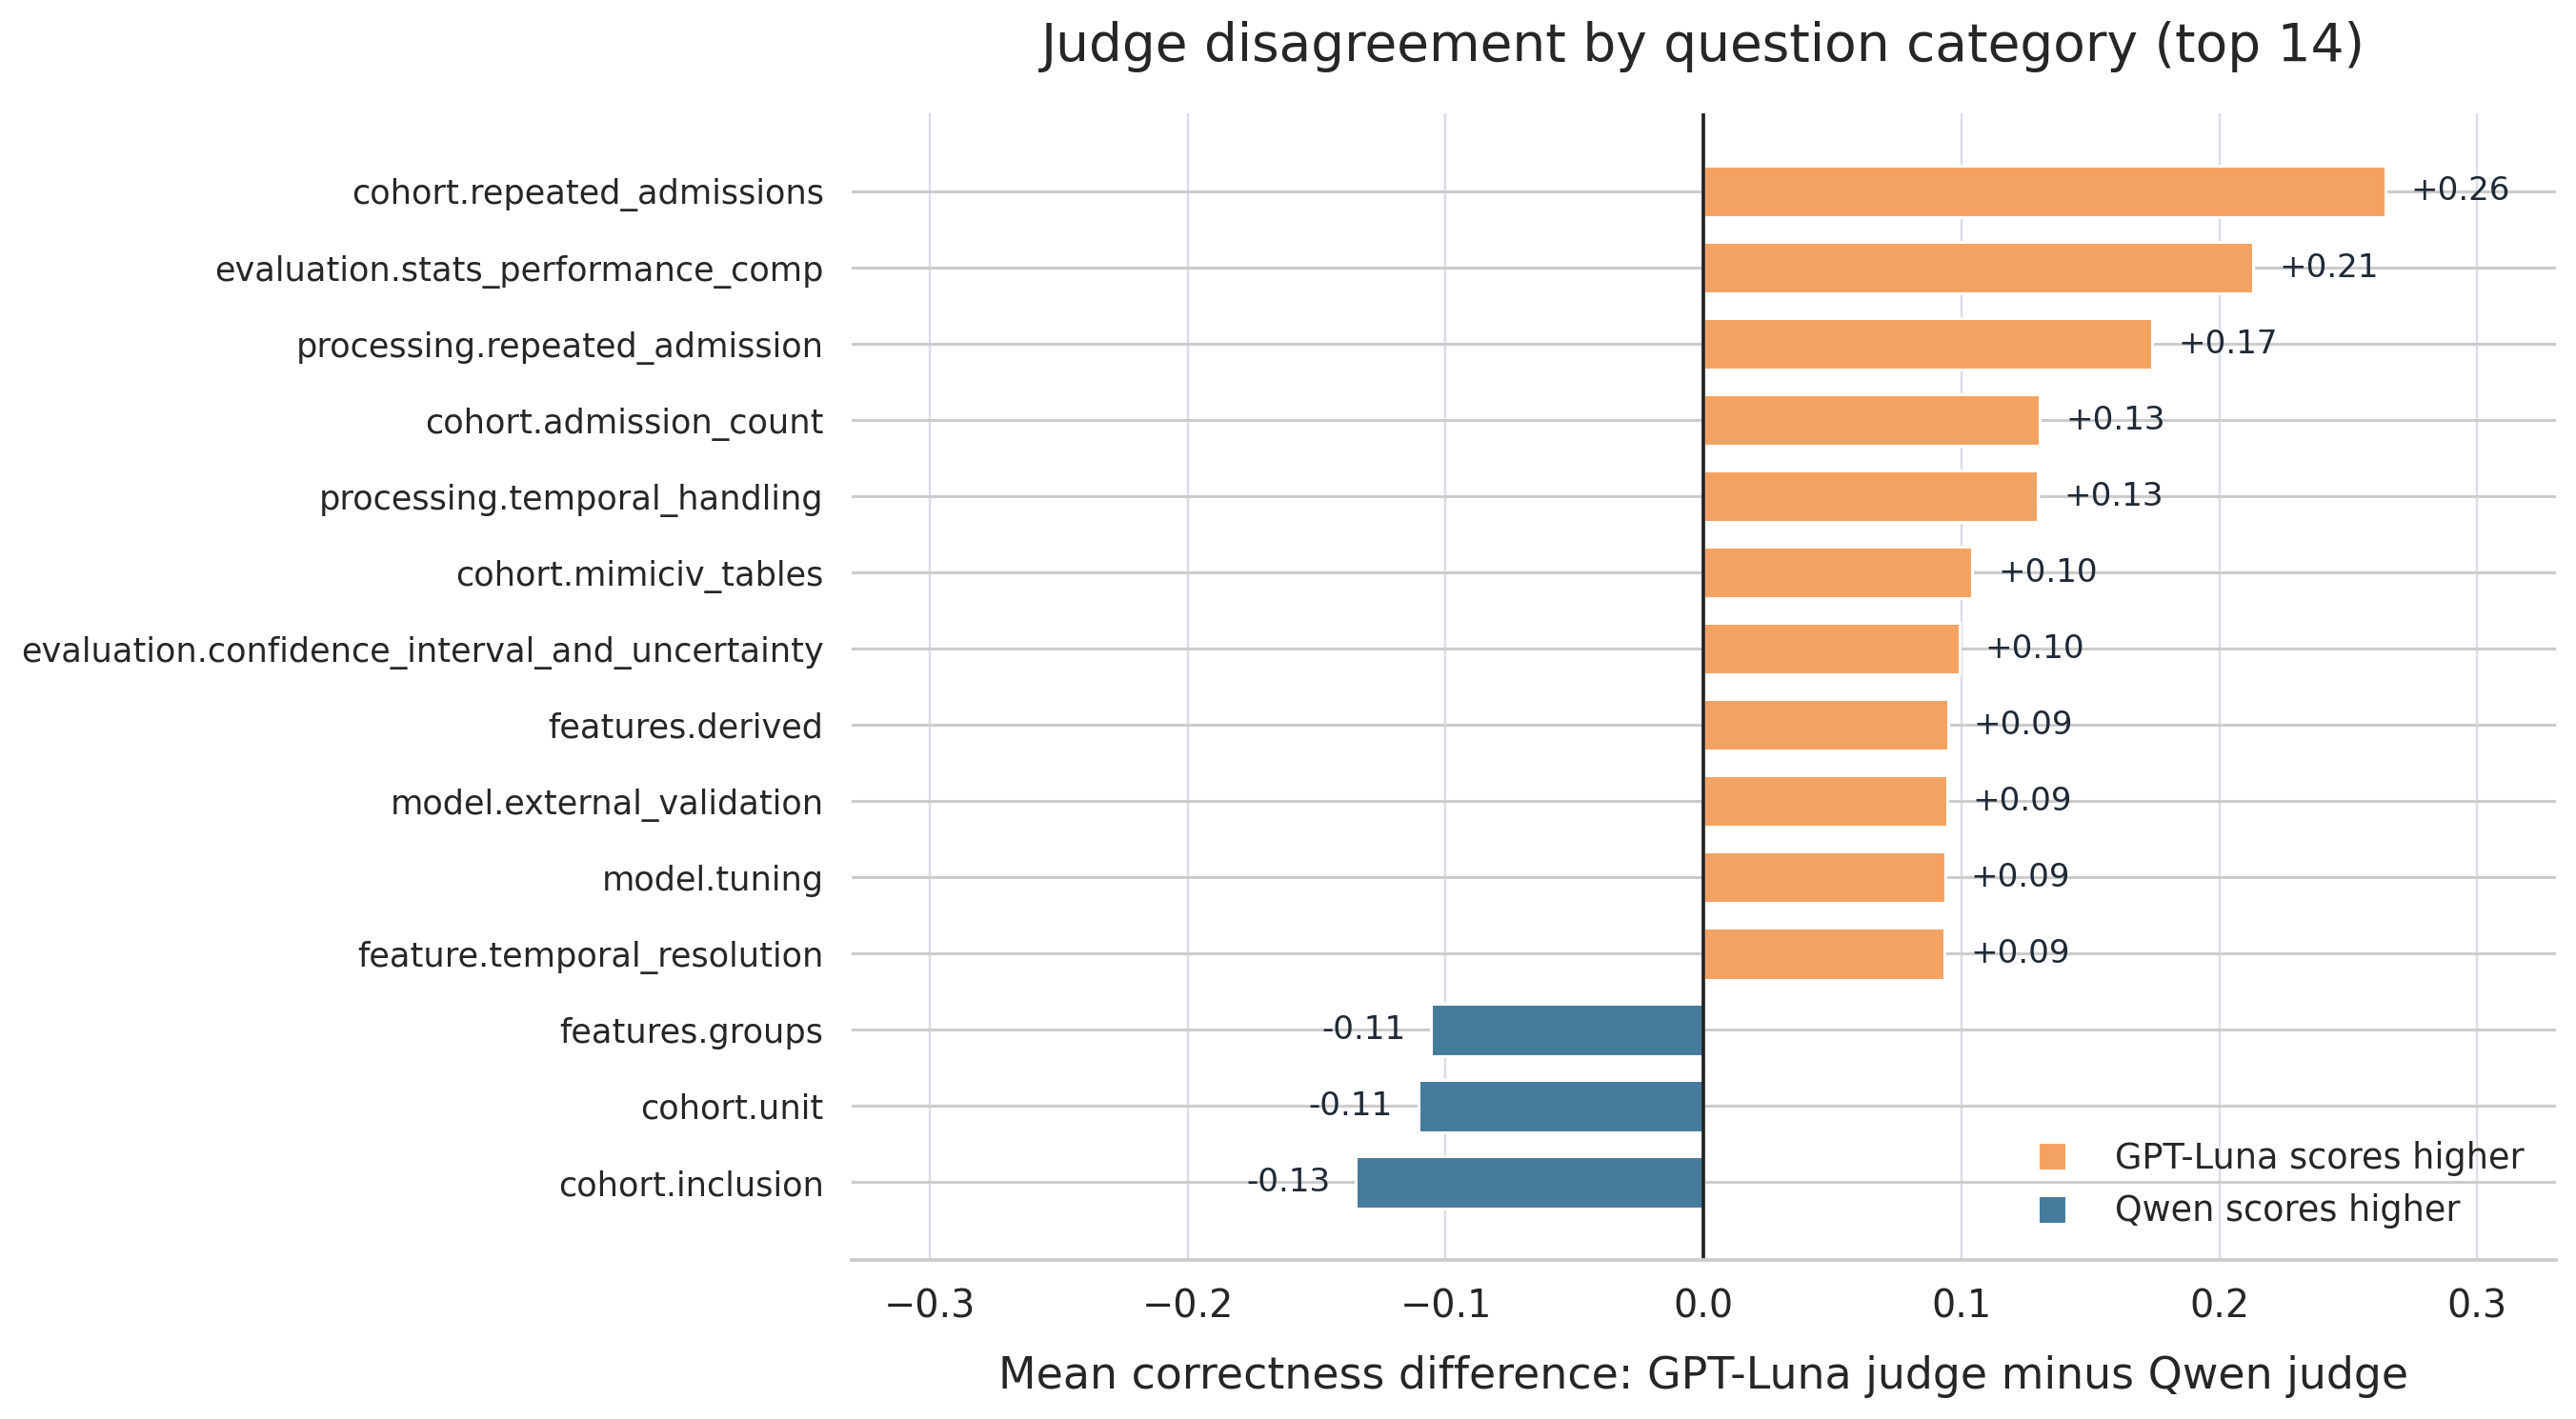

In [8]:
judge_category = (
    judge_results.groupby(["category", "judge_family"], as_index=False)["correctness_score"]
    .mean()
    .pivot(index="category", columns="judge_family", values="correctness_score")
)
judge_category["GPT-Luna minus Qwen"] = judge_category["GPT-5.6 Luna"] - judge_category["Qwen 2.5 7B"]

judge_category["absolute_judge_delta"] = judge_category["GPT-Luna minus Qwen"].abs()
judge_category = judge_category.sort_values("absolute_judge_delta", ascending=False)

print("Categories with largest judge disagreement")
display(judge_category.head(12).round(3))

OUTPUT_DIR = Path("presentation_plots")
OUTPUT_DIR.mkdir(exist_ok=True)

top_disagreement = judge_category.head(14).sort_values("GPT-Luna minus Qwen").copy()
top_disagreement["plot_label"] = wrap_category_labels(top_disagreement.index, width=38)

fig, ax = plt.subplots(figsize=(13.33, 7.5), dpi=220)
colors = np.where(top_disagreement["GPT-Luna minus Qwen"] >= 0, "#f4a261", "#457b9d")
bars = ax.barh(top_disagreement["plot_label"], top_disagreement["GPT-Luna minus Qwen"], color=colors, height=0.68)
ax.axvline(0, color="#222", linewidth=1.2)
ax.set_xlabel("Mean correctness difference: GPT-Luna judge minus Qwen judge", fontsize=15, labelpad=10)
ax.set_ylabel("")
ax.set_title("Judge disagreement by question category (top 14)", fontsize=18, pad=18)
ax.tick_params(axis="x", labelsize=13)
ax.tick_params(axis="y", labelsize=11.5)
ax.grid(axis="x", color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)

x_abs_max = max(0.05, top_disagreement["GPT-Luna minus Qwen"].abs().max())
ax.set_xlim(-x_abs_max * 1.25, x_abs_max * 1.25)

for bar, value in zip(bars, top_disagreement["GPT-Luna minus Qwen"]):
    offset = 0.01 if value >= 0 else -0.01
    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.2f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=11.2,
        color="#1f2937",
    )

legend_handles = [
    plt.Line2D([0], [0], marker="s", color="w", label="GPT-Luna scores higher", markerfacecolor="#f4a261", markersize=10),
    plt.Line2D([0], [0], marker="s", color="w", label="Qwen scores higher", markerfacecolor="#457b9d", markersize=10),
]
ax.legend(handles=legend_handles, frameon=False, loc="lower right", fontsize=12)
fig.subplots_adjust(left=0.36, right=0.97, bottom=0.15, top=0.88)
fig.savefig(OUTPUT_DIR / "05_judge_disagreement.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "05_judge_disagreement.pdf", bbox_inches="tight")
plt.show()



## Stable Strengths And Stable Weaknesses

This filters for categories that both judges agree are weak or strong. These are better candidates for thesis-level claims than model-vs-model deltas.

In [6]:
stable_weak = (
    judge_category[(judge_category["GPT-5.6 Luna"] < 0.40) & (judge_category["Qwen 2.5 7B"] < 0.40)]
    .sort_values(["GPT-5.6 Luna", "Qwen 2.5 7B"])
)
stable_strong = (
    judge_category[(judge_category["GPT-5.6 Luna"] > 0.60) & (judge_category["Qwen 2.5 7B"] > 0.60)]
    .sort_values(["GPT-5.6 Luna", "Qwen 2.5 7B"], ascending=False)
)

print("Stable weaknesses: both judges score below 0.40")
display(stable_weak.round(3))

print("Stable strengths: both judges score above 0.60")
display(stable_strong.round(3))

Stable weaknesses: both judges score below 0.40


judge_family,GPT-5.6 Luna,Qwen 2.5 7B,GPT-Luna minus Qwen,absolute_judge_delta
category,,,,
evaluation.additional_analysis,0.167,0.195,-0.028,0.028
window.observation,0.195,0.000,0.195,0.195
cohort.clinical_domain,0.201,0.219,-0.018,0.018
evaluation.metrics,0.238,0.388,-0.150,0.150
evaluation.explainability,0.254,0.167,0.087,0.087
evaluation.metrics_per_model,0.277,0.362,-0.085,0.085
model.tuning,0.309,0.385,-0.076,0.076
outcome.secondary,0.309,0.183,0.126,0.126
evaluation.confidence_interval_and_uncertainty,0.380,0.259,0.121,0.121


Stable strengths: both judges score above 0.60


judge_family,GPT-5.6 Luna,Qwen 2.5 7B,GPT-Luna minus Qwen,absolute_judge_delta
category,,,,
outcome.prediction_task_category,0.925,0.921,0.004,0.004
cohort.unit,0.870,0.715,0.155,0.155
cohort.exclusion,0.809,0.814,-0.005,0.005
outcome.target_type,0.748,0.809,-0.061,0.061
evaluation.stats_performance_comp,0.747,0.676,0.071,0.071
processing.missing,0.695,0.931,-0.236,0.236
model.methods,0.634,0.622,0.013,0.013
cohort.overview,0.619,0.828,-0.209,0.209


## Retrieval Versus Answering Failure

Low correctness with low context recall suggests retrieval/chunking weakness. Low correctness with high context precision but modest recall often means the system retrieved relevant material but missed specific details during answer extraction.

Lowest-correctness categories with likely failure mode


,category,mean_correctness,mean_context_recall,mean_context_precision,likely_failure_mode,n
37,window.observation,0.098,0.000,0.50,retrieval/chunk recall,4
11,evaluation.additional_analysis,0.181,0.250,0.50,retrieval/chunk recall,4
1,cohort.clinical_domain,0.210,0.000,0.50,retrieval/chunk recall,4
14,evaluation.explainability,0.210,0.250,0.50,retrieval/chunk recall,4
30,outcome.secondary,0.246,0.000,0.00,retrieval/chunk recall,4
27,outcome.classbalance,0.266,0.500,0.25,context ranking/noise,4
15,evaluation.metrics,0.313,0.167,0.50,retrieval/chunk recall,4
13,evaluation.confidence_interval_and_uncertainty,0.319,0.500,1.00,answer extraction/composition,4
16,evaluation.metrics_per_model,0.319,0.167,0.50,retrieval/chunk recall,4
34,processing.repeated_admission,0.331,0.250,0.50,retrieval/chunk recall,4


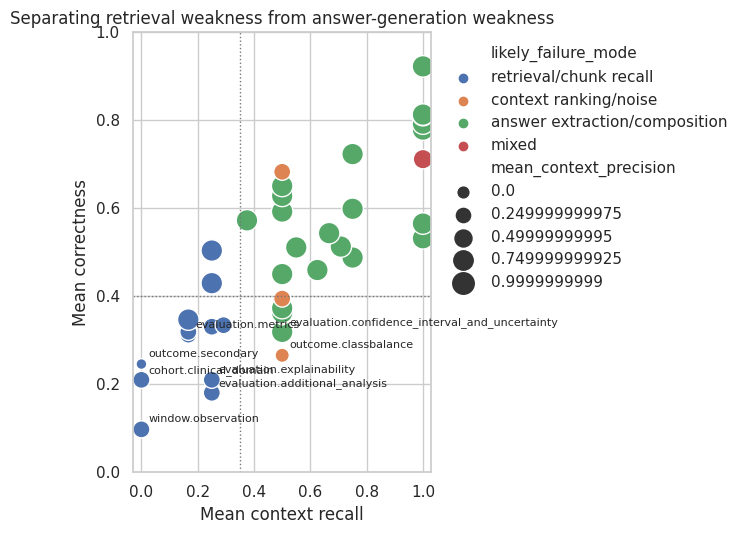

In [7]:
failure_diagnostics = robust_category.copy()
failure_diagnostics["likely_failure_mode"] = np.select(
    [
        failure_diagnostics["mean_context_recall"] < 0.35,
        (failure_diagnostics["mean_context_recall"] >= 0.35) & (failure_diagnostics["mean_context_precision"] >= 0.75),
        failure_diagnostics["mean_context_precision"] < 0.50,
    ],
    [
        "retrieval/chunk recall",
        "answer extraction/composition",
        "context ranking/noise",
    ],
    default="mixed",
)

print("Lowest-correctness categories with likely failure mode")
display(
    failure_diagnostics[
        ["category", "mean_correctness", "mean_context_recall", "mean_context_precision", "likely_failure_mode", "n"]
    ]
    .head(16)
    .round(3)
)

fig, ax = plt.subplots(figsize=(7, 5.5))
if sns:
    sns.scatterplot(
        data=failure_diagnostics,
        x="mean_context_recall",
        y="mean_correctness",
        hue="likely_failure_mode",
        size="mean_context_precision",
        sizes=(60, 240),
        ax=ax,
    )
else:
    ax.scatter(
        failure_diagnostics["mean_context_recall"],
        failure_diagnostics["mean_correctness"],
        s=120,
        alpha=0.75,
    )
for _, row in failure_diagnostics.head(8).iterrows():
    ax.annotate(row["category"], (row["mean_context_recall"], row["mean_correctness"]), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.axhline(0.40, color="#777", linestyle=":", linewidth=1)
ax.axvline(0.35, color="#777", linestyle=":", linewidth=1)
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean context recall")
ax.set_ylabel("Mean correctness")
ax.set_title("Separating retrieval weakness from answer-generation weakness")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

## Reported / Not-Reported Status Detection

This section evaluates whether the RAG pipeline correctly detects if requested information is present in the paper. It does **not** use RAGAS and does **not** judge answer content quality. It only compares the ground-truth reporting status with the model's reporting status.

Classification rule:

| Ground-truth reporting status | Model reporting status | Classification |
|---|---|---|
| Reported | Reported | TP |
| Reported | Not reported | FN |
| Not reported | Reported | FP |
| Not reported | Not reported | TN |

The current source files are `results_v7/*__status_mask.csv`, because these are the consistent paired Llama/MedLlama status-mask runs aligned with the manual review files. The loader applies the same 38-question cleanup used elsewhere: it drops the deprecated one-row `features.temporal` category, renames `feature.temporal_resolution` to `features.temporal_resolution`, and maps the old typo label `partially reporteed` to `reported`.

Reported/not-reported confusion counts


,response_family,ground_truth_reporting_status,model_reporting_status,classification,count
0,Llama,reported,reported,TP,289
1,Llama,reported,not_reported,FN,106
2,Llama,not_reported,reported,FP,21
3,Llama,not_reported,not_reported,TN,40
4,MedLlama,reported,reported,TP,352
5,MedLlama,reported,not_reported,FN,29
6,MedLlama,not_reported,reported,FP,47
7,MedLlama,not_reported,not_reported,TN,12


Excluded rows with unsupported status labels


,response_family,query_id,paper_index,category,reference_status,response_status
480,MedLlama,3,1,cohort.mimiciv_tables,unclear,reported
528,MedLlama,7,1,cohort.unit,inferred,reported
531,MedLlama,7,4,cohort.unit,inferred,reported
533,MedLlama,7,6,cohort.unit,inferred,reported
535,MedLlama,7,8,cohort.unit,inferred,reported
536,MedLlama,7,9,cohort.unit,inferred,reported
539,MedLlama,7,12,cohort.unit,inferred,reported
568,MedLlama,10,5,cohort.admission_count,inferred,reported
576,MedLlama,11,1,cohort.clinical_domain,inferred,not reported
577,MedLlama,11,2,cohort.clinical_domain,inferred,reported


Reported/not-reported detection metrics


,response_family,TP,FN,FP,TN,total,accuracy,reported_precision,reported_recall_sensitivity,reported_f1,not_reported_specificity,not_reported_npv,balanced_accuracy
0,Llama,289,106,21,40,456,0.721,0.932,0.732,0.820,0.656,0.274,0.694
1,MedLlama,352,29,47,12,440,0.827,0.882,0.924,0.903,0.203,0.293,0.564


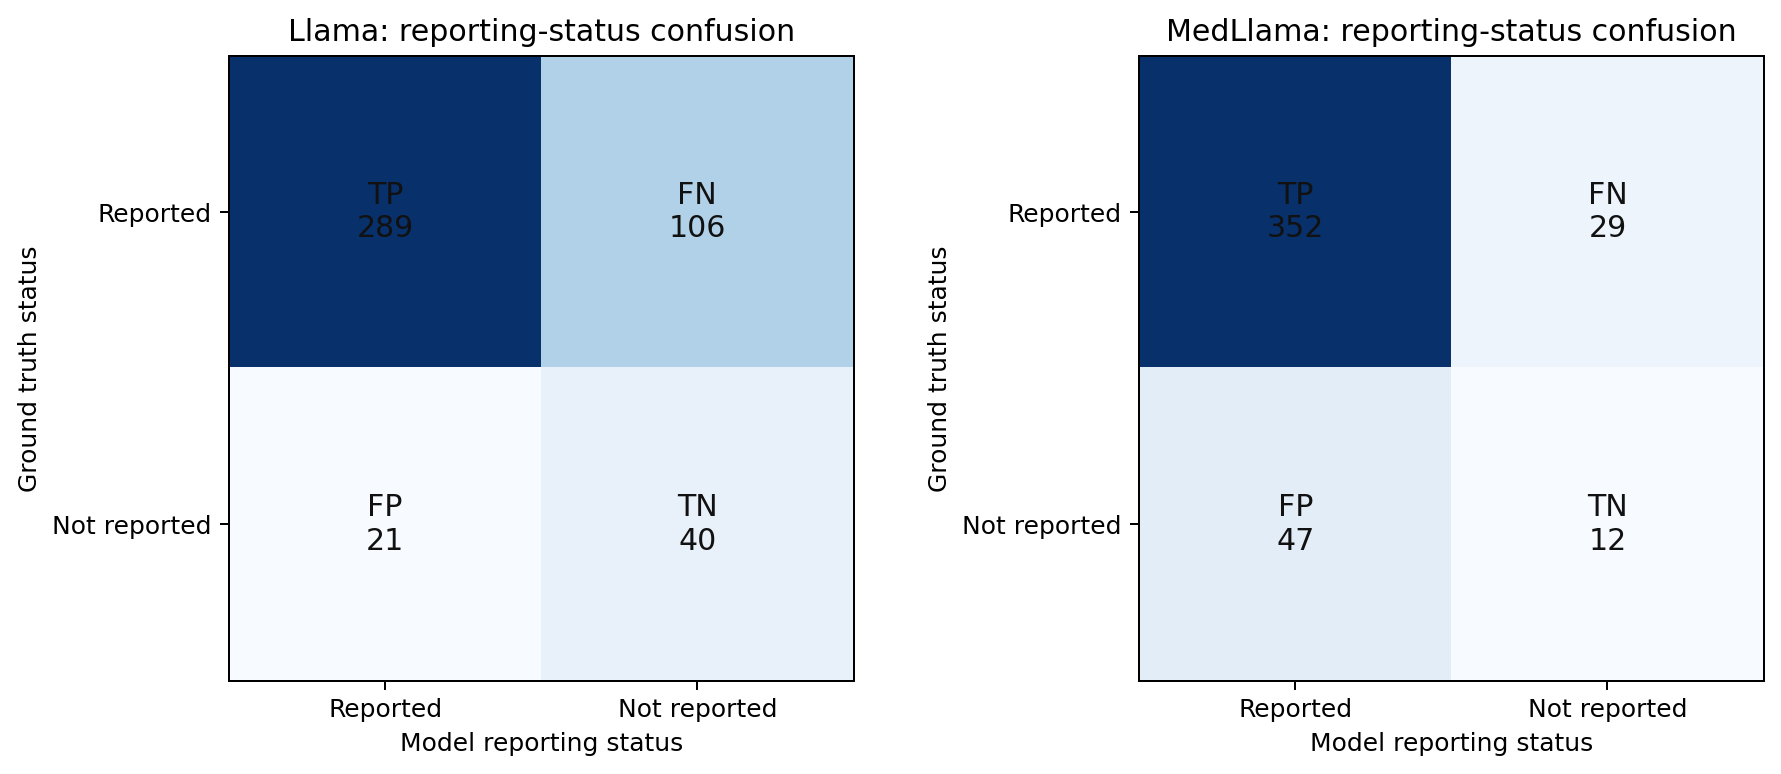

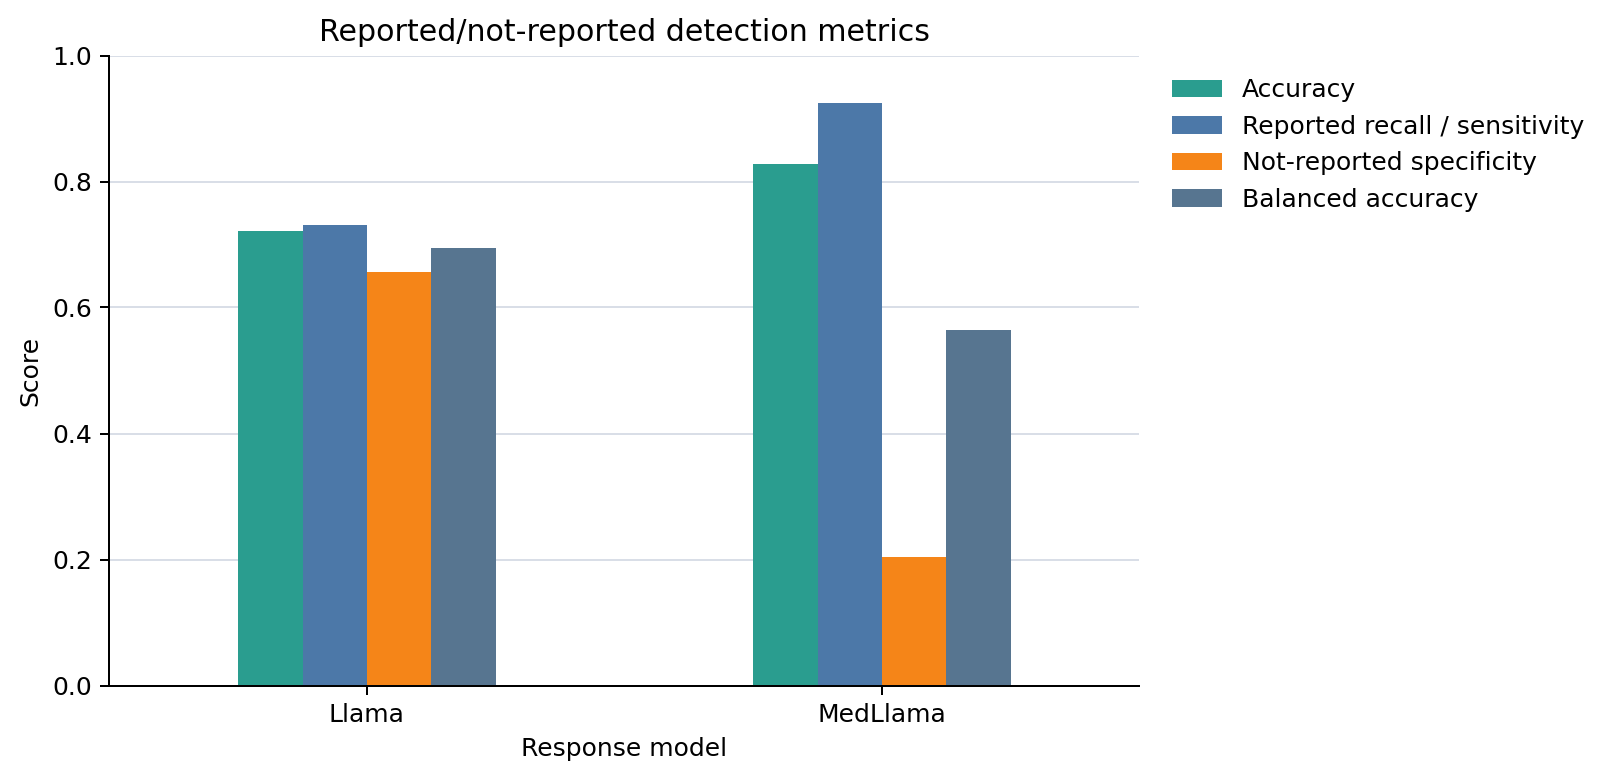

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPORTING_STATUS_FILES = {
    "Llama": Path("results_v8/llama_3_2b__status_mask.csv"),
    "MedLlama": Path("results_v8/medllama_2_7b__status_mask.csv"),
}

REPORTING_STATUS_CLASSIFICATION = {
    ("reported", "reported"): "TP",
    ("reported", "not_reported"): "FN",
    ("not_reported", "reported"): "FP",
    ("not_reported", "not_reported"): "TN",
}


def normalize_reporting_status(value):
    text = str(value).strip().lower().replace("_", " ").replace("-", " ")
    text = " ".join(text.split())
    if text in {"reported", "report", "partially reporteed", "partially reported", "partialy reported"}:
        return "reported"
    if text in {"not reported", "notreported", "no reported", "unreported", "non reported"}:
        return "not_reported"
    return text


def load_reporting_status(path: Path, response_family: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df = df.copy()
    df["response_family"] = response_family
    df["category"] = df["category"].replace({"feature.temporal_resolution": "features.temporal_resolution"})
    df = df[df["category"].ne("features.temporal")].copy()
    df["gt_reporting_status"] = df["reference_status"].map(normalize_reporting_status)
    df["model_reporting_status"] = df["response_status"].map(normalize_reporting_status)
    df["classification"] = [
        REPORTING_STATUS_CLASSIFICATION.get((gt, pred), "excluded")
        for gt, pred in zip(df["gt_reporting_status"], df["model_reporting_status"])
    ]
    return df

reporting_status_all = pd.concat(
    [load_reporting_status(path, model) for model, path in REPORTING_STATUS_FILES.items()],
    ignore_index=True,
)

reporting_status_eval = reporting_status_all[reporting_status_all["classification"].ne("excluded")].copy()
reporting_status_excluded = reporting_status_all[reporting_status_all["classification"].eq("excluded")].copy()

confusion_counts = (
    reporting_status_eval.groupby(
        ["response_family", "gt_reporting_status", "model_reporting_status", "classification"],
        as_index=False,
    )
    .agg(count=("classification", "size"))
)

# Ensure every model has all four cells in a stable order.
complete_rows = []
for model in REPORTING_STATUS_FILES:
    for gt, pred, classification in [
        ("reported", "reported", "TP"),
        ("reported", "not_reported", "FN"),
        ("not_reported", "reported", "FP"),
        ("not_reported", "not_reported", "TN"),
    ]:
        match = confusion_counts[
            confusion_counts["response_family"].eq(model)
            & confusion_counts["gt_reporting_status"].eq(gt)
            & confusion_counts["model_reporting_status"].eq(pred)
        ]
        count = int(match["count"].iloc[0]) if not match.empty else 0
        complete_rows.append({
            "response_family": model,
            "ground_truth_reporting_status": gt,
            "model_reporting_status": pred,
            "classification": classification,
            "count": count,
        })
reporting_confusion_table = pd.DataFrame(complete_rows)

print("Reported/not-reported confusion counts")
display(reporting_confusion_table)

if not reporting_status_excluded.empty:
    print("Excluded rows with unsupported status labels")
    display(reporting_status_excluded[[
        "response_family", "query_id", "paper_index", "category", "reference_status", "response_status"
    ]])


def safe_div(num, den):
    return num / den if den else np.nan

metric_rows = []
for model, group in reporting_confusion_table.groupby("response_family"):
    counts = group.set_index("classification")["count"].to_dict()
    tp = counts.get("TP", 0)
    fn = counts.get("FN", 0)
    fp = counts.get("FP", 0)
    tn = counts.get("TN", 0)
    total = tp + fn + fp + tn
    metric_rows.append({
        "response_family": model,
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
        "total": total,
        "accuracy": safe_div(tp + tn, total),
        "reported_precision": safe_div(tp, tp + fp),
        "reported_recall_sensitivity": safe_div(tp, tp + fn),
        "reported_f1": safe_div(2 * tp, 2 * tp + fp + fn),
        "not_reported_specificity": safe_div(tn, tn + fp),
        "not_reported_npv": safe_div(tn, tn + fn),
        "balanced_accuracy": np.nanmean([
            safe_div(tp, tp + fn),
            safe_div(tn, tn + fp),
        ]),
    })
reporting_status_metrics = pd.DataFrame(metric_rows)

print("Reported/not-reported detection metrics")
display(reporting_status_metrics.round(3))

OUTPUT_DIR = Path("presentation_plots")
OUTPUT_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(1, len(REPORTING_STATUS_FILES), figsize=(5.2 * len(REPORTING_STATUS_FILES), 4.4), dpi=180)
if len(REPORTING_STATUS_FILES) == 1:
    axes = [axes]
for ax, (model, group) in zip(axes, reporting_confusion_table.groupby("response_family")):
    matrix = group.pivot_table(
        index="ground_truth_reporting_status",
        columns="model_reporting_status",
        values="count",
        fill_value=0,
        aggfunc="sum",
    ).reindex(index=["reported", "not_reported"], columns=["reported", "not_reported"], fill_value=0)
    im = ax.imshow(matrix.to_numpy(), cmap="Blues")
    for i, gt in enumerate(matrix.index):
        for j, pred in enumerate(matrix.columns):
            value = int(matrix.loc[gt, pred])
            label = REPORTING_STATUS_CLASSIFICATION[(gt, pred)]
            ax.text(j, i, f"{label}\n{value}", ha="center", va="center", fontsize=12, color="#111")
    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(["Reported", "Not reported"])
    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(["Reported", "Not reported"])
    ax.set_xlabel("Model reporting status")
    ax.set_ylabel("Ground truth status")
    ax.set_title(f"{model}: reporting-status confusion")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "17_reporting_status_confusion_matrices.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "17_reporting_status_confusion_matrices.pdf", bbox_inches="tight")
plt.show()

metric_plot = reporting_status_metrics.set_index("response_family")[[
    "accuracy",
    "reported_recall_sensitivity",
    "not_reported_specificity",
    "balanced_accuracy",
]].rename(columns={
    "accuracy": "Accuracy",
    "reported_recall_sensitivity": "Reported recall / sensitivity",
    "not_reported_specificity": "Not-reported specificity",
    "balanced_accuracy": "Balanced accuracy",
})

fig, ax = plt.subplots(figsize=(10.5, 5), dpi=180)
metric_plot.plot(kind="bar", ax=ax, color=["#2a9d8f", "#4c78a8", "#f58518", "#577590"])
ax.set_ylim(0, 1)
ax.set_xlabel("Response model")
ax.set_ylabel("Score")
ax.set_title("Reported/not-reported detection metrics")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(right=0.67, bottom=0.16, top=0.86)
fig.savefig(OUTPUT_DIR / "18_reporting_status_detection_metrics.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "18_reporting_status_detection_metrics.pdf", bbox_inches="tight")
plt.show()


## Human Expert Analysis

This section uses the manually reviewed reported-information rows to diagnose where the RAG pipeline fails according to the human expert labels. It is intentionally separate from the RAGAS-only analysis above: manual labels distinguish retrieval failures, generation failures, ground-truth issues, and metric false alarms so the thesis can report whether failures come from missing evidence, missed/wrong generation, annotation problems, or judge over-penalization.

The analysis is restricted to `reference_status == reported`, matching the diagnosis plan for reported information. The deprecated one-off `features.temporal` category is removed and the retained temporal category is normalized to `features.temporal_resolution` so the manual review uses the corrected 38-category schema.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MANUAL_REVIEW_FILES = {
    "Llama": Path("manually_reviewed/llama_3_2b_manually_labeled.csv"),
    "MedLlama": Path("manually_reviewed/medllama_2_7b_labeled.csv"),
}

MANUAL_LABEL_ORDER = [
    "retrieval_miss",
    "generation_miss",
    "gt_error",
    "model_ok",
    "unclear",
    "unlabeled",
]

MANUAL_LABEL_SHORT = {
    "retrieval_miss": "Retrieval failure",
    "generation_miss": "Generation failure",
    "gt_error": "GT issue",
    "model_ok": "Metric false alarm",
    "unclear": "Ambiguous",
    "unlabeled": "Unlabeled",
}

MANUAL_LABEL_DESCRIPTIONS = {
    "retrieval_miss": "Context lacks the answer (retrieval failure)",
    "generation_miss": "Context has the answer, model missed/wrong (generation failure)",
    "gt_error": "Ground truth wrong or incomplete",
    "model_ok": "Model actually correct (metric false alarm)",
    "unclear": "Ambiguous / unsure",
    "unlabeled": "Unlabeled / not reviewed",
}

MANUAL_LABEL_COLORS = {
    "retrieval_miss": "#d1495b",
    "generation_miss": "#f58518",
    "gt_error": "#8f63a6",
    "model_ok": "#2a9d8f",
    "unclear": "#6c757d",
    "unlabeled": "#bab0ac",
}


def normalize_reference_status(value):
    text = str(value).strip().lower().replace("_", " ").replace("-", " ")
    text = " ".join(text.split())
    if text in {"reported", "report"}:
        return "reported"
    if text in {"not reported", "notreported", "no reported", "unreported"}:
        return "not_reported"
    return text


def parse_bool(value):
    if isinstance(value, bool):
        return value
    text = str(value).strip().lower()
    if text in {"true", "1", "yes"}:
        return True
    if text in {"false", "0", "no"}:
        return False
    return np.nan


def load_manual_review(path: Path, response_family: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df = df.copy()
    df["response_family"] = response_family
    df["category"] = df["category"].replace({"feature.temporal_resolution": "features.temporal_resolution"})
    df = df[df["category"].ne("features.temporal")].copy()
    df["reference_status_norm"] = df["reference_status"].map(normalize_reference_status)
    df["manual_label_clean"] = df["manual_label"].fillna("").astype(str).str.strip()
    df.loc[df["manual_label_clean"].eq(""), "manual_label_clean"] = "unlabeled"
    df["manual_label_short"] = df["manual_label_clean"].map(MANUAL_LABEL_SHORT).fillna(df["manual_label_clean"])
    df["manual_label_description"] = df["manual_label_clean"].map(MANUAL_LABEL_DESCRIPTIONS).fillna(df["manual_label_clean"])
    df["is_correct_bool"] = df["is_correct"].map(parse_bool)
    for metric_col in [
        "correctness_score",
        "faithfulness",
        "answer_relevancy",
        "context_recall",
        "llm_context_precision_with_reference",
    ]:
        if metric_col in df.columns:
            df[metric_col] = pd.to_numeric(df[metric_col], errors="coerce")
    return df

manual_frames = [
    load_manual_review(path, response_family)
    for response_family, path in MANUAL_REVIEW_FILES.items()
]
manual_review_all = pd.concat(manual_frames, ignore_index=True)

non_reported_manual = manual_review_all[manual_review_all["reference_status_norm"].ne("reported")].copy()
human_results = manual_review_all[manual_review_all["reference_status_norm"].eq("reported")].copy()

shape_check = (
    human_results.groupby("response_family", as_index=False)
    .agg(
        rows=("category", "size"),
        categories=("category", "nunique"),
        min_query_id=("query_id", "min"),
        max_query_id=("query_id", "max"),
        reported_rows=("reference_status_norm", lambda s: s.eq("reported").sum()),
    )
)

print("Manual review shape after reported-only + 38-category cleanup")
display(shape_check)

if not non_reported_manual.empty:
    print("Rows excluded because reference_status is not reported")
    display(non_reported_manual[["response_family", "query_id", "paper_index", "category", "reference_status"]].head(20))

label_legend = pd.DataFrame(
    [{"manual_label": label, "description": MANUAL_LABEL_DESCRIPTIONS[label]} for label in MANUAL_LABEL_ORDER]
)
display(label_legend)


Manual review shape after reported-only + 38-category cleanup


,response_family,rows,categories,min_query_id,max_query_id,reported_rows
0,Llama,393,38,1,38,393
1,MedLlama,393,38,1,39,393


,manual_label,description
0,retrieval_miss,Context lacks the answer (retrieval failure)
1,generation_miss,"Context has the answer, model missed/wrong (ge..."
2,gt_error,Ground truth wrong or incomplete
3,model_ok,Model actually correct (metric false alarm)
4,unclear,Ambiguous / unsure
5,unlabeled,Unlabeled / not reviewed


### Human Diagnosis Distribution

This plot answers the first practical question from the manual review: when reported information is judged problematic, is the dominant cause missing context, missed/wrong generation despite usable context, ground-truth error, or a metric false alarm?

Manual label counts


manual_label_clean,Retrieval failure,Generation failure,GT issue,Metric false alarm,Ambiguous,Unlabeled
response_family,,,,,,
Llama,127,109,4,152,0,1
MedLlama,121,129,2,139,1,1


Manual label shares


manual_label_clean,Retrieval failure,Generation failure,GT issue,Metric false alarm,Ambiguous,Unlabeled
response_family,,,,,,
Llama,32.3%,27.7%,1.0%,38.7%,0.0%,0.3%
MedLlama,30.8%,32.8%,0.5%,35.4%,0.3%,0.3%


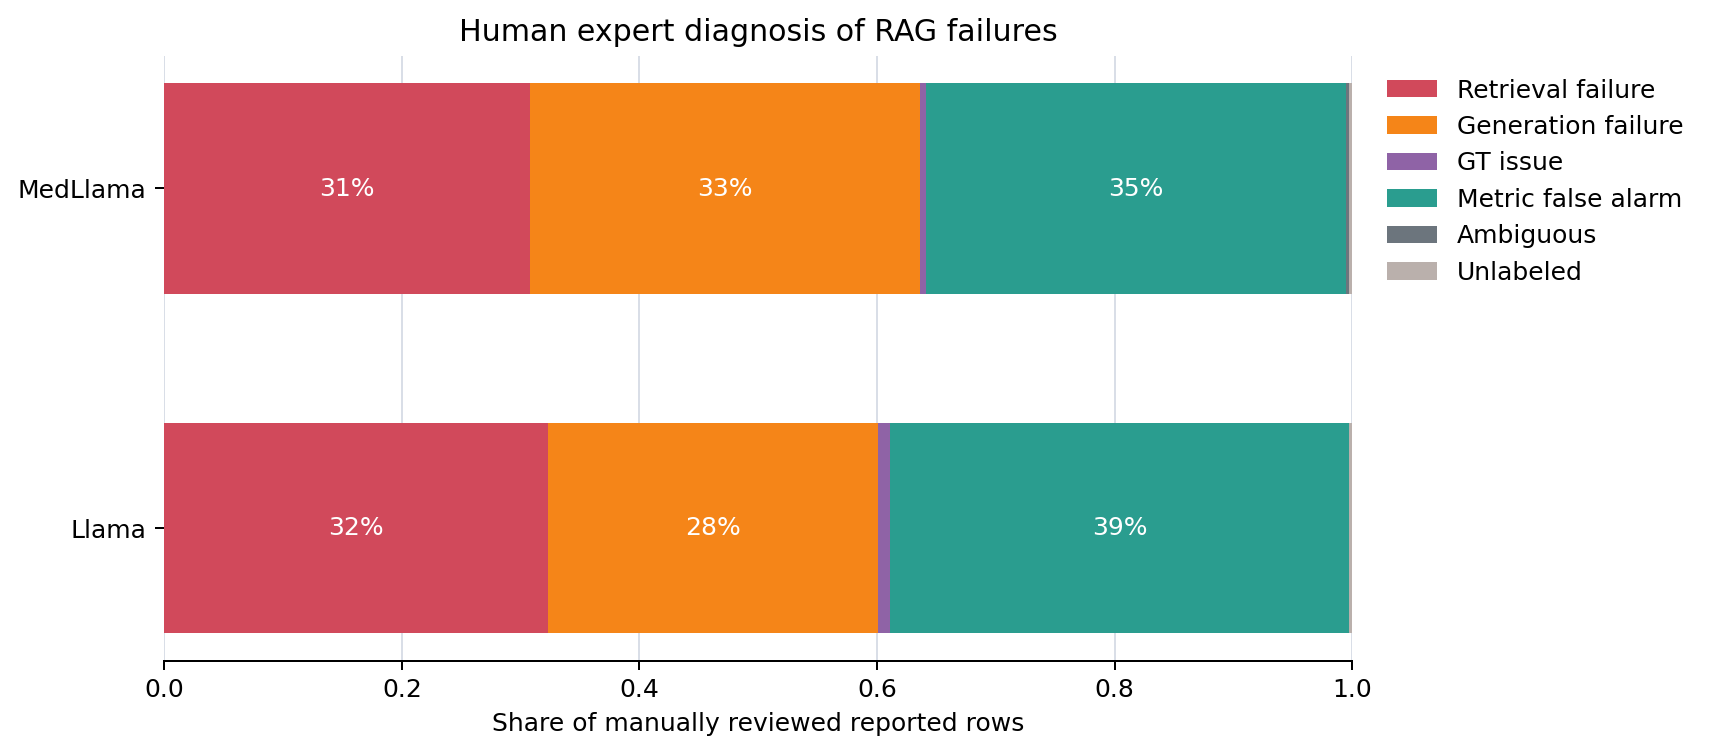

In [13]:
label_counts = (
    human_results.groupby(["response_family", "manual_label_clean"], as_index=False)
    .agg(count=("manual_label_clean", "size"))
)
label_counts["share"] = label_counts["count"] / label_counts.groupby("response_family")["count"].transform("sum")
label_counts["manual_label_short"] = label_counts["manual_label_clean"].map(MANUAL_LABEL_SHORT)

label_count_table = label_counts.pivot_table(
    index="response_family",
    columns="manual_label_clean",
    values="count",
    fill_value=0,
    aggfunc="sum",
)
for label in MANUAL_LABEL_ORDER:
    if label not in label_count_table.columns:
        label_count_table[label] = 0
label_count_table = label_count_table[MANUAL_LABEL_ORDER]

label_share_table = label_count_table.div(label_count_table.sum(axis=1), axis=0)

print("Manual label counts")
display(label_count_table.rename(columns=MANUAL_LABEL_SHORT))

print("Manual label shares")
display(label_share_table.rename(columns=MANUAL_LABEL_SHORT).style.format("{:.1%}"))

OUTPUT_DIR = Path("presentation_plots")
OUTPUT_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 4.8), dpi=180)
left = np.zeros(len(label_share_table))
y_positions = np.arange(len(label_share_table))
for label in MANUAL_LABEL_ORDER:
    values = label_share_table[label].to_numpy()
    ax.barh(
        y_positions,
        values,
        left=left,
        color=MANUAL_LABEL_COLORS[label],
        label=MANUAL_LABEL_SHORT[label],
        height=0.62,
    )
    for y, start, value in zip(y_positions, left, values):
        if value >= 0.08:
            ax.text(start + value / 2, y, f"{value:.0%}", ha="center", va="center", fontsize=10, color="white")
    left += values

ax.set_yticks(y_positions)
ax.set_yticklabels(label_share_table.index)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of manually reviewed reported rows")
ax.set_ylabel("")
ax.set_title("Human expert diagnosis of RAG failures")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="x", color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
fig.subplots_adjust(right=0.72, left=0.12, bottom=0.16, top=0.86)
fig.savefig(OUTPUT_DIR / "08_human_expert_diagnosis_distribution.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "08_human_expert_diagnosis_distribution.pdf", bbox_inches="tight")
plt.show()


### Human-Corrected Model Comparison

`model_ok` is treated as a human-corrected success: the answer was considered correct even if the automated metric flagged it. Retrieval and generation miss rates separate context failure from answer-generation failure.

Human-corrected model summary


,response_family,n,human_correct_rate,retrieval_failure_rate,generation_failure_rate,gt_issue_rate,ambiguous_or_unlabeled_rate,ragas_pass_rate,mean_ragas_correctness,mean_context_recall,mean_context_precision
0,Llama,393,0.387,0.323,0.277,0.010,0.003,0.107,0.527,0.407,0.730
1,MedLlama,393,0.354,0.308,0.328,0.005,0.005,0.059,0.522,0.392,0.735


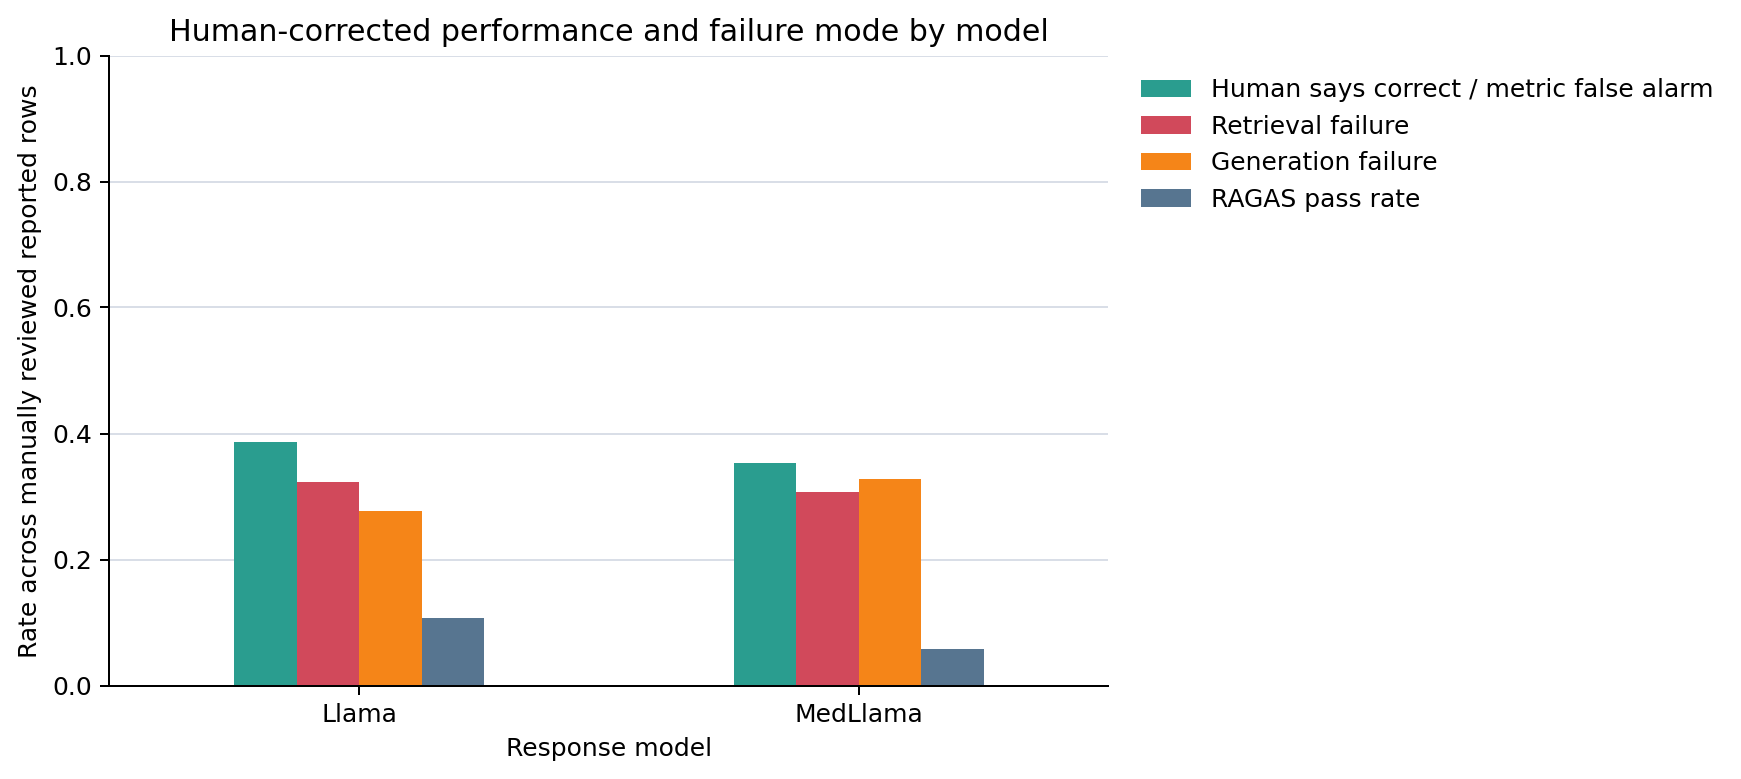

In [14]:
human_model_summary = (
    human_results.groupby("response_family", as_index=False)
    .agg(
        n=("manual_label_clean", "size"),
        human_correct_rate=("manual_label_clean", lambda s: s.eq("model_ok").mean()),
        retrieval_failure_rate=("manual_label_clean", lambda s: s.eq("retrieval_miss").mean()),
        generation_failure_rate=("manual_label_clean", lambda s: s.eq("generation_miss").mean()),
        gt_issue_rate=("manual_label_clean", lambda s: s.eq("gt_error").mean()),
        ambiguous_or_unlabeled_rate=("manual_label_clean", lambda s: s.isin(["unclear", "unlabeled"]).mean()),
        ragas_pass_rate=("is_correct_bool", "mean"),
        mean_ragas_correctness=("correctness_score", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
    )
)

print("Human-corrected model summary")
display(human_model_summary.round(3))

model_metric_plot = human_model_summary.set_index("response_family")[[
    "human_correct_rate",
    "retrieval_failure_rate",
    "generation_failure_rate",
    "ragas_pass_rate",
]].rename(columns={
    "human_correct_rate": "Human says correct / metric false alarm",
    "retrieval_failure_rate": "Retrieval failure",
    "generation_failure_rate": "Generation failure",
    "ragas_pass_rate": "RAGAS pass rate",
})

fig, ax = plt.subplots(figsize=(10, 5), dpi=180)
model_metric_plot.plot(
    kind="bar",
    ax=ax,
    color=["#2a9d8f", "#d1495b", "#f58518", "#577590"],
)
ax.set_ylim(0, 1)
ax.set_xlabel("Response model")
ax.set_ylabel("Rate across manually reviewed reported rows")
ax.set_title("Human-corrected performance and failure mode by model")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(right=0.68, bottom=0.16, top=0.86)
fig.savefig(OUTPUT_DIR / "09_human_corrected_model_comparison.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "09_human_corrected_model_comparison.pdf", bbox_inches="tight")
plt.show()


### Category-Level Human Diagnosis

This table and plot identify which question categories most often fail because the retrieved context lacks the answer versus because the model misses or distorts an answer that is present in the context.

Categories with the highest human-diagnosed actionable failure rate


manual_label_clean,total,retrieval_miss,generation_miss,model_ok,gt_error,unclear,unlabeled,retrieval_failure_rate,generation_failure_rate,metric_false_alarm_rate,actionable_failure_rate
category,,,,,,,,,,,
features.temporal_resolution,22,21,1,0,0,0,0,95.5%,4.5%,0.0%,100.0%
features.derived,24,7,16,0,0,0,1,29.2%,66.7%,0.0%,95.8%
outcome.classbalance,20,10,9,1,0,0,0,50.0%,45.0%,5.0%,95.0%
evaluation.additional_analysis,20,10,8,2,0,0,0,50.0%,40.0%,10.0%,90.0%
cohort.admission_count,8,6,1,1,0,0,0,75.0%,12.5%,12.5%,87.5%
cohort.overview,24,11,10,2,0,0,1,45.8%,41.7%,8.3%,87.5%
evaluation.confidence_interval_and_uncertainty,16,6,8,2,0,0,0,37.5%,50.0%,12.5%,87.5%
evaluation.metrics_per_model,22,13,6,3,0,0,0,59.1%,27.3%,13.6%,86.4%
processing.temporal_handling,24,16,4,4,0,0,0,66.7%,16.7%,16.7%,83.3%


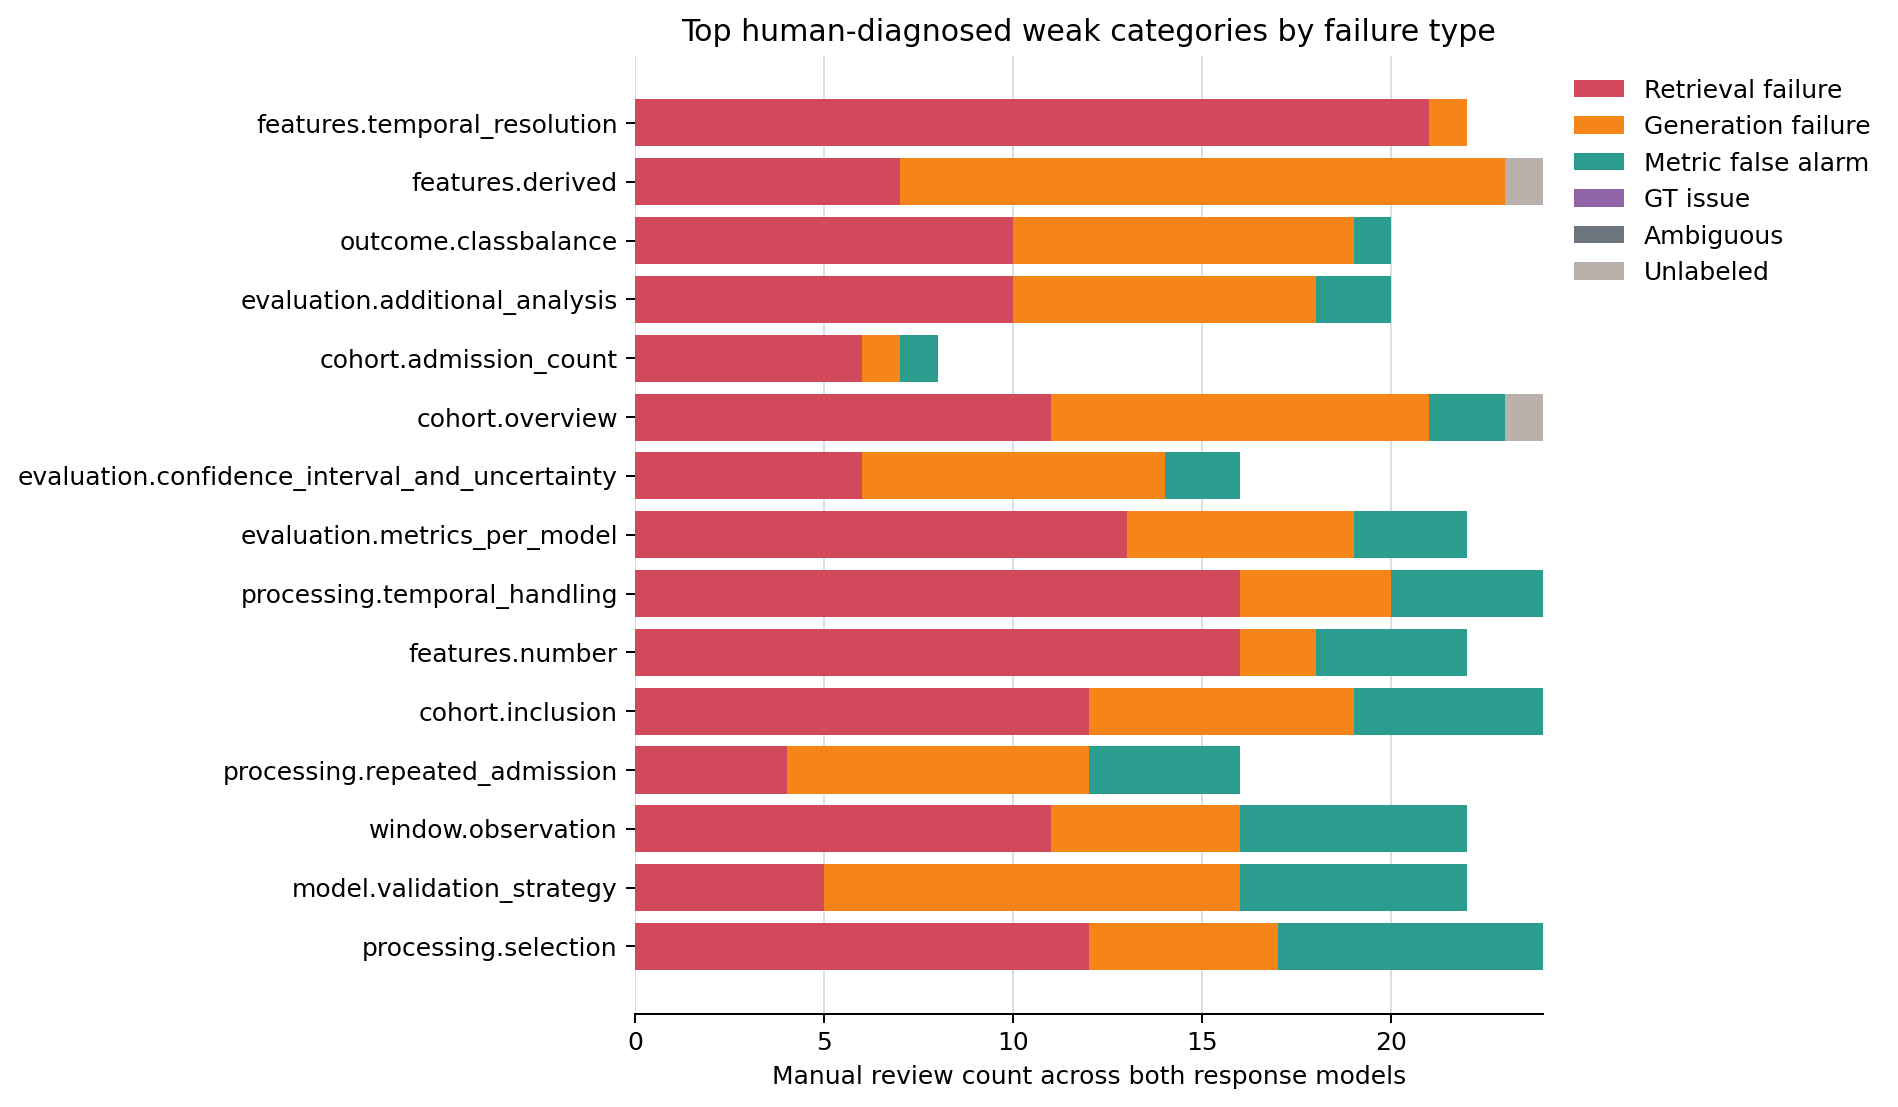

In [ ]:
## TODO: Report as percentage only based on GT, remove metric false alarms
## TODO: Report for each question

category_label_counts = human_results.pivot_table(
    index="category",
    columns="manual_label_clean",
    values="article_id",
    aggfunc="size",
    fill_value=0,
)
for label in MANUAL_LABEL_ORDER:
    if label not in category_label_counts.columns:
        category_label_counts[label] = 0
category_label_counts = category_label_counts[MANUAL_LABEL_ORDER]
category_label_counts["total"] = category_label_counts.sum(axis=1)
category_label_counts["retrieval_failure_rate"] = category_label_counts["retrieval_miss"] / category_label_counts["total"]
category_label_counts["generation_failure_rate"] = category_label_counts["generation_miss"] / category_label_counts["total"]
category_label_counts["metric_false_alarm_rate"] = category_label_counts["model_ok"] / category_label_counts["total"]
category_label_counts["actionable_failure_rate"] = (
    category_label_counts["retrieval_miss"] + category_label_counts["generation_miss"]
) / category_label_counts["total"]

category_diagnosis = category_label_counts.sort_values(
    ["actionable_failure_rate", "retrieval_failure_rate", "generation_failure_rate"],
    ascending=False,
)

print("Categories with the highest human-diagnosed actionable failure rate")
display(
    category_diagnosis[[
        "total",
        "retrieval_miss",
        "generation_miss",
        "model_ok",
        "gt_error",
        "unclear",
        "unlabeled",
        "retrieval_failure_rate",
        "generation_failure_rate",
        "metric_false_alarm_rate",
        "actionable_failure_rate",
    ]]
    .head(15)
    .style.format({
        "retrieval_failure_rate": "{:.1%}",
        "generation_failure_rate": "{:.1%}",
        "metric_false_alarm_rate": "{:.1%}",
        "actionable_failure_rate": "{:.1%}",
    })
)

plot_category = category_diagnosis.head(15).iloc[::-1]
plot_cols = ["retrieval_miss", "generation_miss", "model_ok", "gt_error", "unclear", "unlabeled"]
fig, ax = plt.subplots(figsize=(12, 7), dpi=180)
left = np.zeros(len(plot_category))
y_labels = plot_category.index.tolist()
for label in plot_cols:
    values = plot_category[label].to_numpy()
    ax.barh(
        y_labels,
        values,
        left=left,
        color=MANUAL_LABEL_COLORS[label],
        label=MANUAL_LABEL_SHORT[label],
    )
    left += values
ax.set_xlabel("Manual review count across both response models")
ax.set_ylabel("")
ax.set_title("Top human-diagnosed weak categories by failure type")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="x", color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
fig.subplots_adjust(left=0.30, right=0.72, bottom=0.12, top=0.88)
fig.savefig(OUTPUT_DIR / "10_human_category_failure_modes.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "10_human_category_failure_modes.pdf", bbox_inches="tight")
plt.show()


### Manual Labels Versus Automated Metrics

This connects the human diagnosis back to the judge metrics: retrieval failures should have low context recall, generation failures can have better context metrics but low answer correctness, and `model_ok` rows reveal metric false alarms.

Automated metrics by human diagnosis label


,response_family,manual_label_clean,n,ragas_pass_rate,mean_correctness,mean_faithfulness,mean_answer_relevancy,mean_context_recall,mean_context_precision,manual_label_short
0,Llama,generation_miss,109,0.000,0.488,0.599,0.427,0.437,0.890,Generation failure
1,Llama,gt_error,4,0.000,0.674,0.750,0.523,0.750,1.000,GT issue
2,Llama,model_ok,152,0.276,0.709,0.861,0.645,0.622,0.928,Metric false alarm
3,Llama,retrieval_miss,127,0.000,0.339,0.648,0.255,0.115,0.346,Retrieval failure
4,Llama,unlabeled,1,0.000,0.267,0.800,0.000,0.000,1.000,Unlabeled
5,MedLlama,generation_miss,129,0.008,0.513,0.470,0.579,0.488,0.919,Generation failure
6,MedLlama,gt_error,2,0.000,0.642,0.543,0.757,0.625,0.500,GT issue
7,MedLlama,model_ok,139,0.151,0.671,0.800,0.660,0.553,0.939,Metric false alarm
8,MedLlama,retrieval_miss,121,0.000,0.355,0.453,0.514,0.099,0.306,Retrieval failure
9,MedLlama,unclear,1,0.000,0.585,1.000,0.754,0.000,1.000,Ambiguous


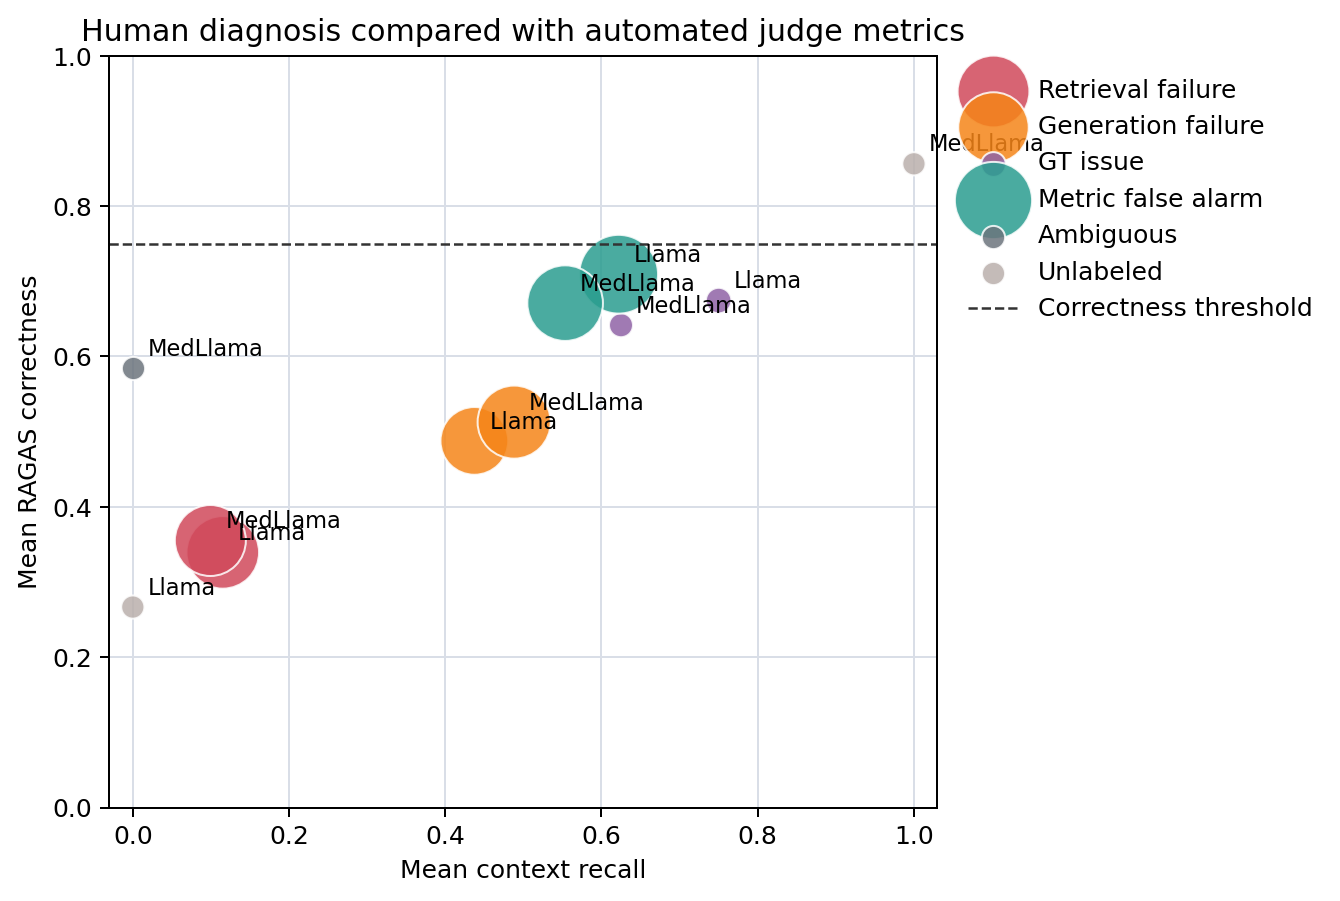

In [ ]:
## TODO: use the same RAGAs metrics as in the main evaluation
## TODO: context recall human evaluator, context recall judge
## TODO: generation failure human evaluator, answer relevancy judge

metric_by_manual_label = (
    human_results.groupby(["response_family", "manual_label_clean"], as_index=False)
    .agg(
        n=("manual_label_clean", "size"),
        ragas_pass_rate=("is_correct_bool", "mean"),
        mean_correctness=("correctness_score", "mean"),
        mean_faithfulness=("faithfulness", "mean"),
        mean_answer_relevancy=("answer_relevancy", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
    )
)
metric_by_manual_label["manual_label_short"] = metric_by_manual_label["manual_label_clean"].map(MANUAL_LABEL_SHORT)

print("Automated metrics by human diagnosis label")
display(metric_by_manual_label.round(3))

fig, ax = plt.subplots(figsize=(8, 5.8), dpi=180)
for label in MANUAL_LABEL_ORDER:
    label_df = metric_by_manual_label[metric_by_manual_label["manual_label_clean"].eq(label)]
    if label_df.empty:
        continue
    ax.scatter(
        label_df["mean_context_recall"],
        label_df["mean_correctness"],
        s=80 + 6 * label_df["n"],
        color=MANUAL_LABEL_COLORS[label],
        label=MANUAL_LABEL_SHORT[label],
        alpha=0.85,
        edgecolor="white",
        linewidth=0.8,
    )
    for _, row in label_df.iterrows():
        ax.annotate(
            row["response_family"],
            (row["mean_context_recall"], row["mean_correctness"]),
            xytext=(6, 5),
            textcoords="offset points",
            fontsize=9,
        )

ax.axhline(0.75, color="#333", linestyle="--", linewidth=1, label="Correctness threshold")
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean context recall")
ax.set_ylabel("Mean RAGAS correctness")
ax.set_title("Human diagnosis compared with automated judge metrics")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
fig.subplots_adjust(right=0.70, bottom=0.14, top=0.86)
fig.savefig(OUTPUT_DIR / "11_human_vs_ragas_metrics.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "11_human_vs_ragas_metrics.pdf", bbox_inches="tight")
plt.show()


### Human RAG Error Metrics

These metrics reproduce the core RAG diagnosis without using RAGAS scores. They use only the human label:

- `retrieval_miss` -> human context recall = 0, human correctness = 0
- `generation_miss` -> human context recall = 1, human correctness = 0
- `model_ok` -> human context recall = 1, human correctness = 1

`gt_error`, `unclear`, and `unlabeled` rows are excluded from the metric denominator because they do not cleanly describe model or retrieval behavior. This gives a human-only recall/correctness map: low recall points to retrieval/chunking/reranking, while high recall but low correctness points to generation/prompt/model capacity.

Human-only RAG error metrics by response model


,response_family,n,human_context_recall,human_correctness,retrieval_error_rate,generation_error_rate,metric_false_alarm_rate,human_generation_success_given_context,dominant_human_error
0,Llama,388,0.673,0.392,0.327,0.281,0.392,0.582,Retrieval
1,MedLlama,389,0.689,0.357,0.311,0.332,0.357,0.519,Generation


Human-only RAG error metrics by category, lowest correctness first


,category,n,human_context_recall,human_correctness,retrieval_error_rate,generation_error_rate,metric_false_alarm_rate,human_generation_success_given_context,dominant_human_error
21,features.temporal_resolution,22,0.045,0.000,0.955,0.045,0.000,0.000,Retrieval
18,features.derived,23,0.696,0.000,0.304,0.696,0.000,0.000,Generation
26,outcome.classbalance,20,0.500,0.050,0.500,0.450,0.050,0.100,Retrieval
6,cohort.overview,23,0.522,0.087,0.478,0.435,0.087,0.167,Retrieval
11,evaluation.additional_analysis,20,0.500,0.100,0.500,0.400,0.100,0.200,Retrieval
0,cohort.admission_count,8,0.250,0.125,0.750,0.125,0.125,0.500,Retrieval
13,evaluation.confidence_interval_and_uncertainty,16,0.625,0.125,0.375,0.500,0.125,0.200,Generation
16,evaluation.metrics_per_model,22,0.409,0.136,0.591,0.273,0.136,0.333,Retrieval
35,processing.temporal_handling,24,0.333,0.167,0.667,0.167,0.167,0.500,Retrieval
20,features.number,22,0.273,0.182,0.727,0.091,0.182,0.667,Retrieval


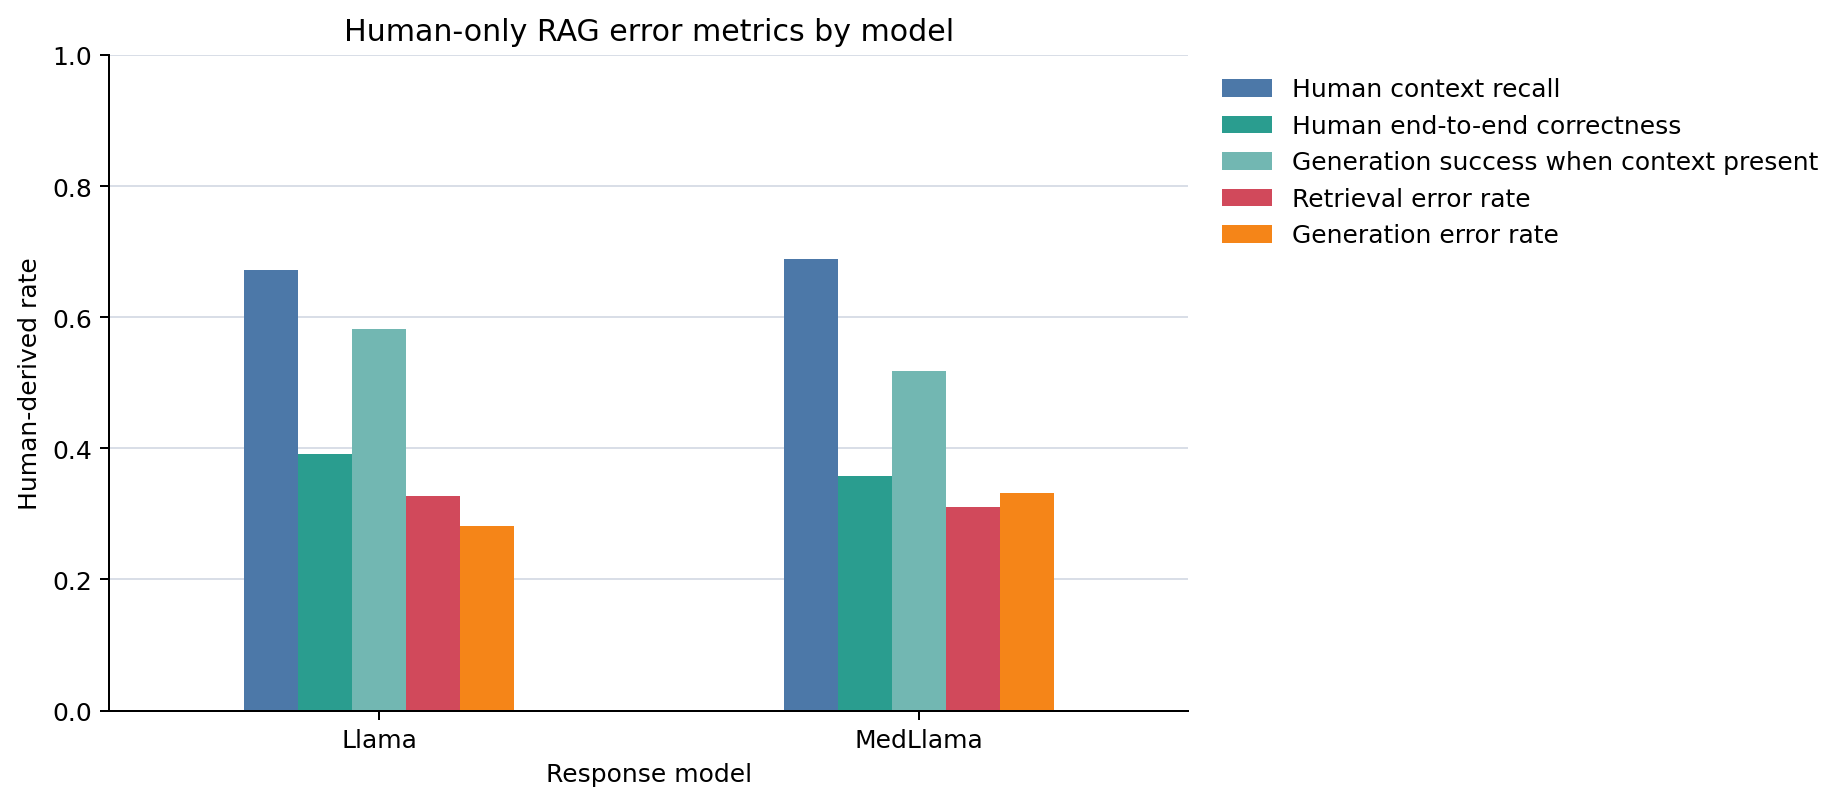

In [18]:
HUMAN_METRIC_LABELS = ["retrieval_miss", "generation_miss", "model_ok"]

human_metric_rows = human_results[
    human_results["manual_label_clean"].isin(HUMAN_METRIC_LABELS)
].copy()
human_metric_rows["human_context_recall"] = human_metric_rows["manual_label_clean"].isin([
    "generation_miss",
    "model_ok",
]).astype(float)
human_metric_rows["human_correctness"] = human_metric_rows["manual_label_clean"].eq("model_ok").astype(float)
human_metric_rows["human_retrieval_error"] = human_metric_rows["manual_label_clean"].eq("retrieval_miss").astype(float)
human_metric_rows["human_generation_error"] = human_metric_rows["manual_label_clean"].eq("generation_miss").astype(float)


def summarize_human_rag_metrics(group_cols):
    summary = (
        human_metric_rows.groupby(group_cols, as_index=False)
        .agg(
            n=("manual_label_clean", "size"),
            human_context_recall=("human_context_recall", "mean"),
            human_correctness=("human_correctness", "mean"),
            retrieval_error_rate=("human_retrieval_error", "mean"),
            generation_error_rate=("human_generation_error", "mean"),
            metric_false_alarm_rate=("manual_label_clean", lambda s: s.eq("model_ok").mean()),
        )
    )
    context_available = summary["n"] * summary["human_context_recall"]
    correct = summary["n"] * summary["human_correctness"]
    summary["human_generation_success_given_context"] = np.divide(
        correct,
        context_available,
        out=np.full(len(summary), np.nan),
        where=context_available.to_numpy() > 0,
    )
    summary["dominant_human_error"] = np.select(
        [
            summary["retrieval_error_rate"] >= summary["generation_error_rate"],
            summary["generation_error_rate"] > summary["retrieval_error_rate"],
        ],
        ["Retrieval", "Generation"],
        default="Mixed",
    )
    summary.loc[summary["human_correctness"].ge(0.5), "dominant_human_error"] = "Mostly correct"
    return summary

human_rag_model_metrics = summarize_human_rag_metrics(["response_family"])
human_rag_category_metrics = summarize_human_rag_metrics(["category"])
human_rag_model_category_metrics = summarize_human_rag_metrics(["response_family", "category"])

print("Human-only RAG error metrics by response model")
display(human_rag_model_metrics.round(3))

print("Human-only RAG error metrics by category, lowest correctness first")
display(
    human_rag_category_metrics
    .sort_values(["human_correctness", "human_context_recall"], ascending=[True, True])
    .head(15)
    .round(3)
)

human_rag_model_plot = human_rag_model_metrics.set_index("response_family")[[
    "human_context_recall",
    "human_correctness",
    "human_generation_success_given_context",
    "retrieval_error_rate",
    "generation_error_rate",
]].rename(columns={
    "human_context_recall": "Human context recall",
    "human_correctness": "Human end-to-end correctness",
    "human_generation_success_given_context": "Generation success when context present",
    "retrieval_error_rate": "Retrieval error rate",
    "generation_error_rate": "Generation error rate",
})

fig, ax = plt.subplots(figsize=(11, 5.2), dpi=180)
human_rag_model_plot.plot(
    kind="bar",
    ax=ax,
    color=["#4c78a8", "#2a9d8f", "#72b7b2", "#d1495b", "#f58518"],
)
ax.set_ylim(0, 1)
ax.set_xlabel("Response model")
ax.set_ylabel("Human-derived rate")
ax.set_title("Human-only RAG error metrics by model")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(right=0.67, bottom=0.16, top=0.86)
fig.savefig(OUTPUT_DIR / "12_human_rag_error_metrics_by_model.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "12_human_rag_error_metrics_by_model.pdf", bbox_inches="tight")
plt.show()


### Human-Derived RAG System Accuracy

This turns the manual diagnosis into an end-to-end RAG system accuracy score. The evaluable denominator contains only labels that directly judge pipeline behavior: `retrieval_miss`, `generation_miss`, and `model_ok`.

- `model_ok` = correct end-to-end RAG output
- `retrieval_miss` = incorrect because the answer was not in the context
- `generation_miss` = incorrect because the answer was in context but the model missed or distorted it

Rows labeled `gt_error`, `unclear`, or left unlabeled are excluded from the accuracy denominator, but their exclusion rate is reported as `evaluable_coverage`.

Overall human-derived RAG system accuracy


,reported_reviewed_n,evaluable_n,evaluable_coverage,correct_n,incorrect_n,rag_system_accuracy,accuracy_level,human_context_accuracy,human_generation_accuracy_given_context,retrieval_failure_rate,generation_failure_rate
0,786,777,0.989,291,486,0.375,Low,0.681,0.55,0.319,0.306


Human-derived RAG system accuracy by response model


,response_family,reported_reviewed_n,evaluable_n,evaluable_coverage,correct_n,incorrect_n,rag_system_accuracy,accuracy_level,human_context_accuracy,human_generation_accuracy_given_context,retrieval_failure_rate,generation_failure_rate
0,Llama,393,388,0.987,152,236,0.392,Low,0.673,0.582,0.327,0.281
1,MedLlama,393,389,0.990,139,250,0.357,Low,0.689,0.519,0.311,0.332


Lowest category-level human-derived RAG system accuracy


,category,reported_reviewed_n,evaluable_n,evaluable_coverage,correct_n,incorrect_n,rag_system_accuracy,accuracy_level,human_context_accuracy,human_generation_accuracy_given_context,retrieval_failure_rate,generation_failure_rate
21,features.temporal_resolution,22,22,1.000,0,22,0.000,Low,0.045,0.000,0.955,0.045
18,features.derived,24,23,0.958,0,23,0.000,Low,0.696,0.000,0.304,0.696
26,outcome.classbalance,20,20,1.000,1,19,0.050,Low,0.500,0.100,0.500,0.450
6,cohort.overview,24,23,0.958,2,21,0.087,Low,0.522,0.167,0.478,0.435
11,evaluation.additional_analysis,20,20,1.000,2,18,0.100,Low,0.500,0.200,0.500,0.400
0,cohort.admission_count,8,8,1.000,1,7,0.125,Low,0.250,0.500,0.750,0.125
13,evaluation.confidence_interval_and_uncertainty,16,16,1.000,2,14,0.125,Low,0.625,0.200,0.375,0.500
16,evaluation.metrics_per_model,22,22,1.000,3,19,0.136,Low,0.409,0.333,0.591,0.273
35,processing.temporal_handling,24,24,1.000,4,20,0.167,Low,0.333,0.500,0.667,0.167
20,features.number,22,22,1.000,4,18,0.182,Low,0.273,0.667,0.727,0.091


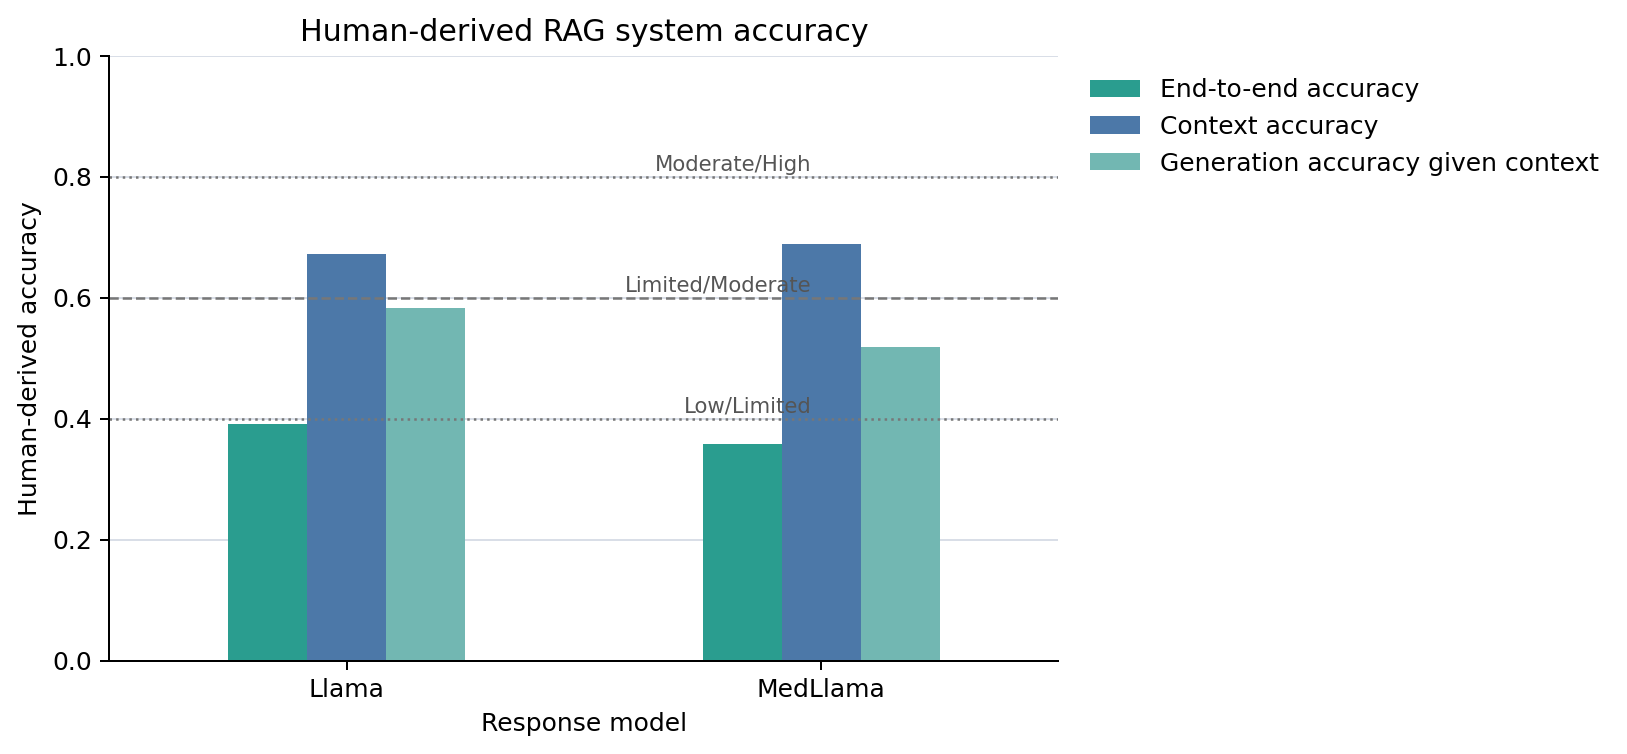

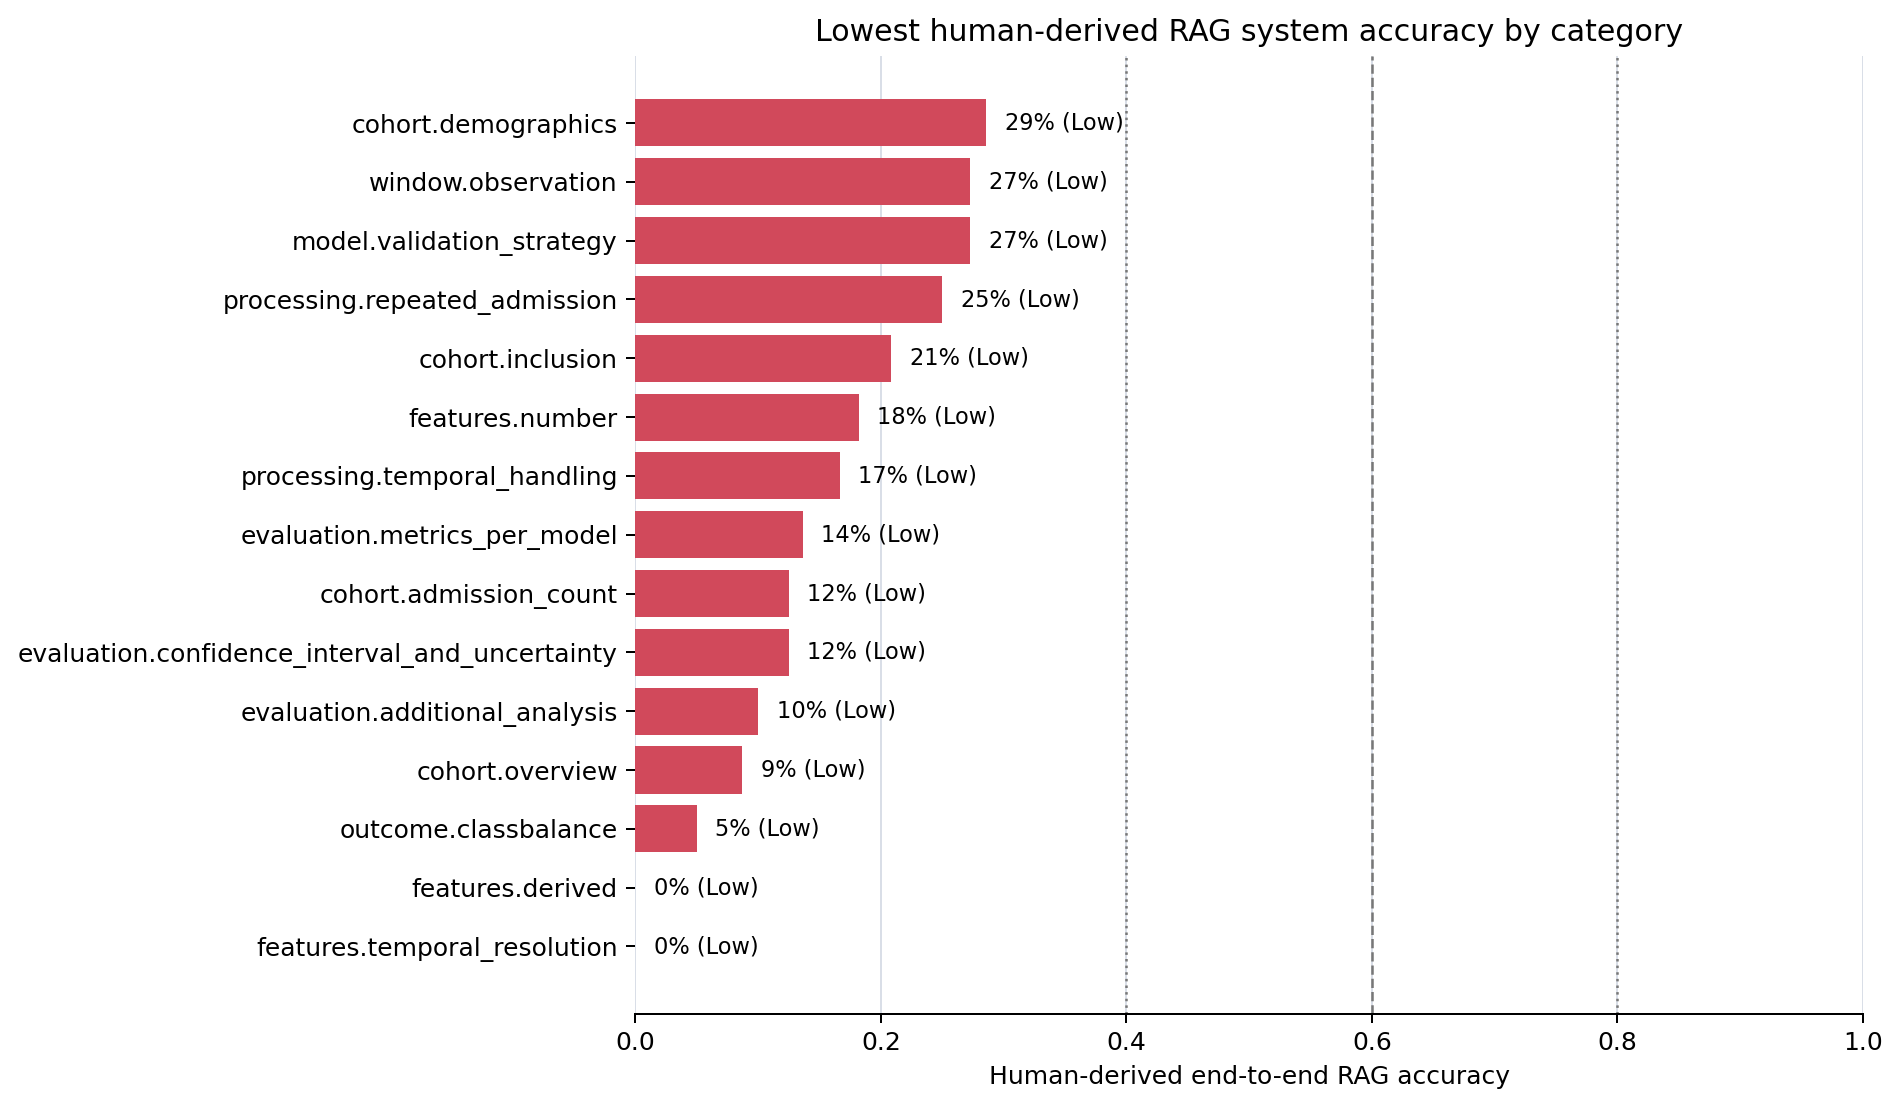

In [19]:
SYSTEM_EVALUABLE_LABELS = ["retrieval_miss", "generation_miss", "model_ok"]
SYSTEM_EXCLUDED_LABELS = ["gt_error", "unclear", "unlabeled"]


def accuracy_level(value):
    if pd.isna(value):
        return "Not estimable"
    if value >= 0.80:
        return "High"
    if value >= 0.60:
        return "Moderate"
    if value >= 0.40:
        return "Limited"
    return "Low"


def summarize_system_accuracy(group_cols=None):
    group_cols = list(group_cols or [])
    reported = human_results.copy()
    evaluable = human_metric_rows.copy()

    if group_cols:
        reported_total = reported.groupby(group_cols).size().rename("reported_reviewed_n")
        summary = evaluable.groupby(group_cols).agg(
            evaluable_n=("manual_label_clean", "size"),
            correct_n=("manual_label_clean", lambda s: s.eq("model_ok").sum()),
            incorrect_n=("manual_label_clean", lambda s: s.isin(["retrieval_miss", "generation_miss"]).sum()),
            retrieval_failure_n=("manual_label_clean", lambda s: s.eq("retrieval_miss").sum()),
            generation_failure_n=("manual_label_clean", lambda s: s.eq("generation_miss").sum()),
        )
        summary = summary.join(reported_total, how="left").reset_index()
    else:
        summary = pd.DataFrame([{
            "reported_reviewed_n": len(reported),
            "evaluable_n": len(evaluable),
            "correct_n": int(evaluable["manual_label_clean"].eq("model_ok").sum()),
            "incorrect_n": int(evaluable["manual_label_clean"].isin(["retrieval_miss", "generation_miss"]).sum()),
            "retrieval_failure_n": int(evaluable["manual_label_clean"].eq("retrieval_miss").sum()),
            "generation_failure_n": int(evaluable["manual_label_clean"].eq("generation_miss").sum()),
        }])

    context_available_n = summary["generation_failure_n"] + summary["correct_n"]
    summary["rag_system_accuracy"] = summary["correct_n"] / summary["evaluable_n"]
    summary["rag_system_error_rate"] = summary["incorrect_n"] / summary["evaluable_n"]
    summary["human_context_accuracy"] = context_available_n / summary["evaluable_n"]
    summary["human_generation_accuracy_given_context"] = np.divide(
        summary["correct_n"],
        context_available_n,
        out=np.full(len(summary), np.nan),
        where=context_available_n.to_numpy() > 0,
    )
    summary["retrieval_failure_rate"] = summary["retrieval_failure_n"] / summary["evaluable_n"]
    summary["generation_failure_rate"] = summary["generation_failure_n"] / summary["evaluable_n"]
    summary["evaluable_coverage"] = summary["evaluable_n"] / summary["reported_reviewed_n"]
    summary["accuracy_level"] = summary["rag_system_accuracy"].map(accuracy_level)
    return summary

rag_system_accuracy_overall = summarize_system_accuracy()
rag_system_accuracy_by_model = summarize_system_accuracy(["response_family"])
rag_system_accuracy_by_field = summarize_system_accuracy(["field_id"])
rag_system_accuracy_by_category = summarize_system_accuracy(["category"])

accuracy_cols = [
    "reported_reviewed_n",
    "evaluable_n",
    "evaluable_coverage",
    "correct_n",
    "incorrect_n",
    "rag_system_accuracy",
    "accuracy_level",
    "human_context_accuracy",
    "human_generation_accuracy_given_context",
    "retrieval_failure_rate",
    "generation_failure_rate",
]

print("Overall human-derived RAG system accuracy")
display(rag_system_accuracy_overall[accuracy_cols].round(3))

print("Human-derived RAG system accuracy by response model")
display(rag_system_accuracy_by_model[["response_family", *accuracy_cols]].round(3))

print("Lowest category-level human-derived RAG system accuracy")
display(
    rag_system_accuracy_by_category
    .sort_values(["rag_system_accuracy", "human_context_accuracy"], ascending=[True, True])
    [["category", *accuracy_cols]]
    .head(15)
    .round(3)
)

fig, ax = plt.subplots(figsize=(9.5, 4.8), dpi=180)
plot_df = rag_system_accuracy_by_model.set_index("response_family")[[
    "rag_system_accuracy",
    "human_context_accuracy",
    "human_generation_accuracy_given_context",
]].rename(columns={
    "rag_system_accuracy": "End-to-end accuracy",
    "human_context_accuracy": "Context accuracy",
    "human_generation_accuracy_given_context": "Generation accuracy given context",
})
plot_df.plot(kind="bar", ax=ax, color=["#2a9d8f", "#4c78a8", "#72b7b2"])
for y, label in [(0.40, "Low/Limited"), (0.60, "Limited/Moderate"), (0.80, "Moderate/High")]:
    ax.axhline(y, color="#777", linestyle=":" if y != 0.60 else "--", linewidth=1)
    ax.text(0.98, y + 0.01, label, fontsize=8.5, color="#555", ha="right")
ax.set_ylim(0, 1)
ax.set_xlabel("Response model")
ax.set_ylabel("Human-derived accuracy")
ax.set_title("Human-derived RAG system accuracy")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(right=0.68, bottom=0.16, top=0.86)
fig.savefig(OUTPUT_DIR / "15_human_rag_system_accuracy_by_model.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "15_human_rag_system_accuracy_by_model.pdf", bbox_inches="tight")
plt.show()

category_accuracy_plot = (
    rag_system_accuracy_by_category
    .sort_values("rag_system_accuracy")
    .head(15)
    .sort_values("rag_system_accuracy", ascending=True)
)
fig, ax = plt.subplots(figsize=(11, 7), dpi=180)
colors = category_accuracy_plot["accuracy_level"].map({
    "Low": "#d1495b",
    "Limited": "#f58518",
    "Moderate": "#4c78a8",
    "High": "#2a9d8f",
    "Not estimable": "#bab0ac",
}).fillna("#bab0ac")
bars = ax.barh(category_accuracy_plot["category"], category_accuracy_plot["rag_system_accuracy"], color=colors)
ax.axvline(0.40, color="#777", linestyle=":", linewidth=1)
ax.axvline(0.60, color="#777", linestyle="--", linewidth=1)
ax.axvline(0.80, color="#777", linestyle=":", linewidth=1)
ax.set_xlim(0, 1)
ax.set_xlabel("Human-derived end-to-end RAG accuracy")
ax.set_ylabel("")
ax.set_title("Lowest human-derived RAG system accuracy by category")
ax.grid(axis="x", color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
for bar, value, level in zip(bars, category_accuracy_plot["rag_system_accuracy"], category_accuracy_plot["accuracy_level"]):
    ax.text(value + 0.015, bar.get_y() + bar.get_height()/2, f"{value:.0%} ({level})", va="center", fontsize=9)
fig.subplots_adjust(left=0.34, right=0.96, bottom=0.12, top=0.88)
fig.savefig(OUTPUT_DIR / "16_human_rag_system_accuracy_by_category.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "16_human_rag_system_accuracy_by_category.pdf", bbox_inches="tight")
plt.show()


### Human Recall-Correctness Error Map

Each point is a question category. The x-axis is human context recall: did the retrieved context contain the answer? The y-axis is human correctness: did the generated answer pass human review? This separates retrieval failures from generation failures without relying on RAGAS.

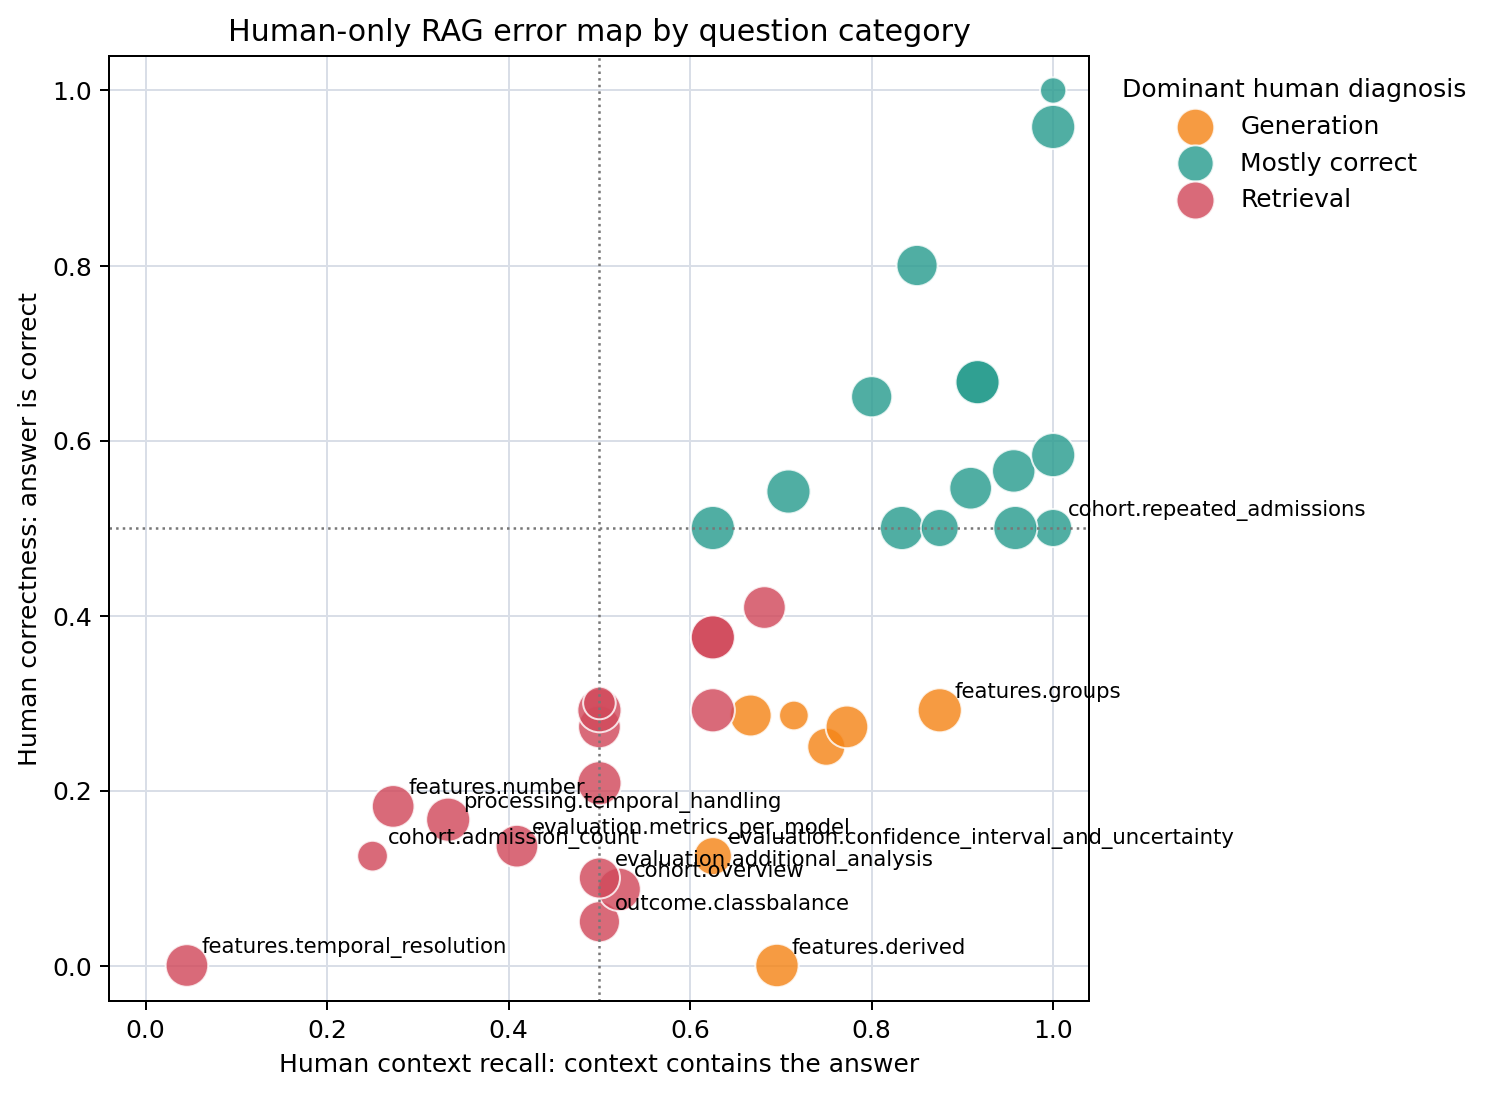

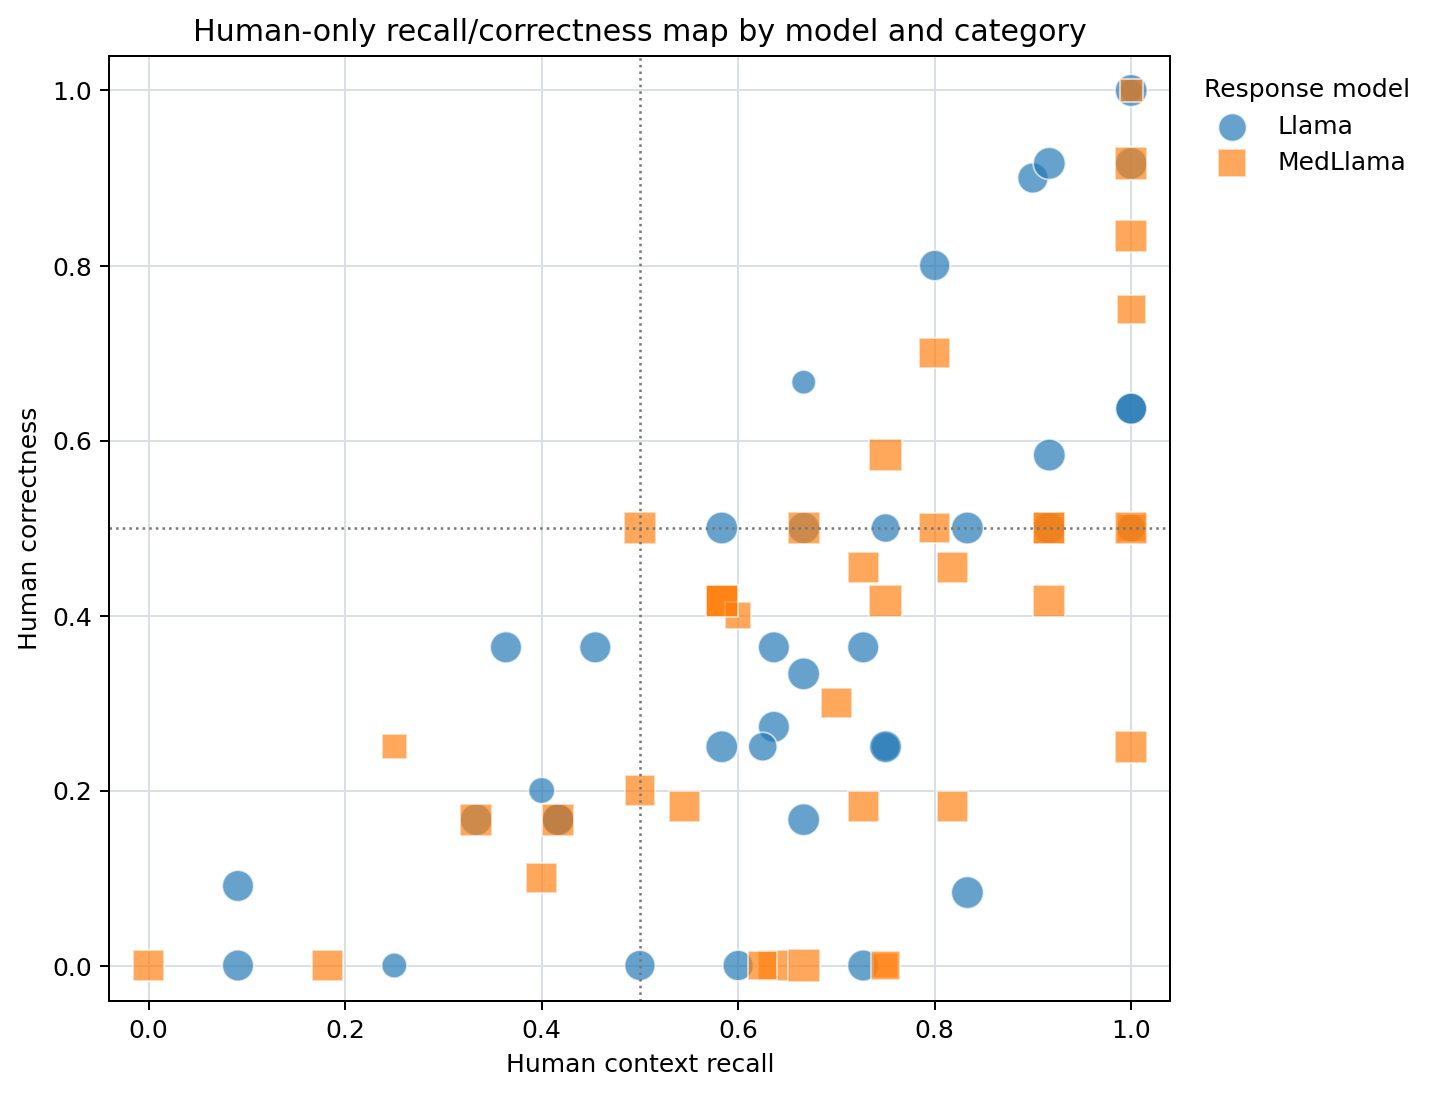

In [20]:
error_palette = {
    "Retrieval": "#d1495b",
    "Generation": "#f58518",
    "Mostly correct": "#2a9d8f",
    "Mixed": "#6c757d",
}

plot_df = human_rag_category_metrics.copy()
plot_df["plot_size"] = 70 + 10 * plot_df["n"]
plot_df = plot_df.sort_values("human_correctness")

fig, ax = plt.subplots(figsize=(9, 7), dpi=180)
for error_mode, error_df in plot_df.groupby("dominant_human_error"):
    ax.scatter(
        error_df["human_context_recall"],
        error_df["human_correctness"],
        s=error_df["plot_size"],
        color=error_palette.get(error_mode, "#6c757d"),
        alpha=0.82,
        edgecolor="white",
        linewidth=0.8,
        label=error_mode,
    )

# Label the lowest-correctness categories and categories with strong retrieval/generation disagreement.
label_candidates = pd.concat([
    plot_df.nsmallest(10, "human_correctness"),
    plot_df.assign(error_gap=(plot_df["retrieval_error_rate"] - plot_df["generation_error_rate"]).abs())
           .nlargest(6, "error_gap"),
]).drop_duplicates("category")
for _, row in label_candidates.iterrows():
    ax.annotate(
        row["category"],
        (row["human_context_recall"], row["human_correctness"]),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=8.5,
    )

ax.axhline(0.50, color="#777", linestyle=":", linewidth=1)
ax.axvline(0.50, color="#777", linestyle=":", linewidth=1)
ax.set_xlim(-0.04, 1.04)
ax.set_ylim(-0.04, 1.04)
ax.set_xlabel("Human context recall: context contains the answer")
ax.set_ylabel("Human correctness: answer is correct")
ax.set_title("Human-only RAG error map by question category")
ax.legend(frameon=False, title="Dominant human diagnosis", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
fig.subplots_adjust(right=0.73, bottom=0.13, top=0.88)
fig.savefig(OUTPUT_DIR / "13_human_recall_correctness_error_map.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "13_human_recall_correctness_error_map.pdf", bbox_inches="tight")
plt.show()

model_category_plot = human_rag_model_category_metrics.copy()
model_markers = {"Llama": "o", "MedLlama": "s"}
fig, ax = plt.subplots(figsize=(9, 7), dpi=180)
for response_family, model_df in model_category_plot.groupby("response_family"):
    ax.scatter(
        model_df["human_context_recall"],
        model_df["human_correctness"],
        s=70 + 8 * model_df["n"],
        marker=model_markers.get(response_family, "o"),
        alpha=0.68,
        label=response_family,
        edgecolor="white",
        linewidth=0.7,
    )
ax.axhline(0.50, color="#777", linestyle=":", linewidth=1)
ax.axvline(0.50, color="#777", linestyle=":", linewidth=1)
ax.set_xlim(-0.04, 1.04)
ax.set_ylim(-0.04, 1.04)
ax.set_xlabel("Human context recall")
ax.set_ylabel("Human correctness")
ax.set_title("Human-only recall/correctness map by model and category")
ax.legend(frameon=False, title="Response model", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(color="#d9dee7", linewidth=0.8)
ax.set_axisbelow(True)
fig.subplots_adjust(right=0.78, bottom=0.13, top=0.88)
fig.savefig(OUTPUT_DIR / "14_human_recall_correctness_by_model_category.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "14_human_recall_correctness_by_model_category.pdf", bbox_inches="tight")
plt.show()


### Cases For Pipeline Diagnosis

Use these sampled rows to trace failure cases through retrieval, chunking, reranking, and generation. The examples are selected from reported-information rows and grouped by model plus manual failure label.

In [17]:
diagnosis_case_cols = [
    "response_family",
    "manual_label_short",
    "query_id",
    "paper_index",
    "category",
    "article_id",
    "article_title",
    "correctness_score",
    "context_recall",
    "llm_context_precision_with_reference",
    "manual_notes",
    "response",
    "reference",
]

case_labels = ["retrieval_miss", "generation_miss", "gt_error", "unclear"]
diagnosis_cases = (
    human_results[human_results["manual_label_clean"].isin(case_labels)]
    .sort_values(["response_family", "manual_label_clean", "correctness_score", "context_recall"], na_position="last")
    .groupby(["response_family", "manual_label_clean"], group_keys=False)
    .head(5)
    .copy()
)

print("Representative human-diagnosed cases to trace through the pipeline")
display(diagnosis_cases[[col for col in diagnosis_case_cols if col in diagnosis_cases.columns]].round(3))


Representative human-diagnosed cases to trace through the pipeline


,response_family,manual_label_short,query_id,paper_index,category,article_id,article_title,correctness_score,context_recall,llm_context_precision_with_reference,manual_notes,response,reference
6,Llama,Generation failure,1,7,cohort.overview,s41467-025-62527-x,The HM-TARGET personalised real-time haemodyna...,0.000,0.00,1.0,NaN,Not reported.,The primary modelling cohorts comprised adult ...
28,Llama,Generation failure,4,3,cohort.inclusion,s12873-022-00582-z,Factors and machine learning models for predic...,0.000,0.00,0.0,NaN,Not reported,Patients were eligible if they: (1) were adult...
32,Llama,Generation failure,4,7,cohort.inclusion,s41467-025-62527-x,The HM-TARGET personalised real-time haemodyna...,0.000,0.00,0.0,NaN,Not reported.,Inclusion required: (1) age ≥18 years; (2) an ...
164,Llama,Generation failure,17,6,outcome.classbalance,s12872-025-04628-5,Comparison of machine learning and nomogram to...,0.000,0.00,0.0,NaN,Not reported.,tion\nIn the complete eICU-CRD development coh...
182,Llama,Generation failure,19,1,window.prediction,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,0.000,0.00,1.0,NaN,Not reported.,The outcome was predicted and assessed at 30 d...
58,Llama,GT issue,7,1,cohort.unit,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,0.333,1.00,1.0,NaN,Not reported.,The unit of analysis appears to be an ICU admi...
134,Llama,GT issue,14,3,outcome.secondary,s12873-022-00582-z,Factors and machine learning models for predic...,0.746,0.50,1.0,NaN,"Yes, the study evaluated several secondary out...",The formal secondary outcomes were CRRT durati...
81,Llama,GT issue,9,1,cohort.demographics,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,0.750,0.50,1.0,NaN,Here are the reported demographic characterist...,The cohort is elderly (≥ 65 years) and the var...
154,Llama,GT issue,16,6,outcome.targe_disease,s12872-025-04628-5,Comparison of machine learning and nomogram to...,0.868,1.00,1.0,NaN,Acute myocardial infarction combined with card...,The target population comprised patients with ...
30,Llama,Retrieval failure,4,5,cohort.inclusion,s40001-023-01593-7,Interpretable machine learning model for early...,0.000,0.00,0.0,NaN,Not reported.,(1) ICU admission; (2) age ≥18 years; (3) seps...


### Human Expert Analysis Takeaway

Use the manual-label distribution as the thesis-facing diagnosis and the RAGAS metric tables as supporting evidence. `retrieval_miss` points to retrieval, chunking, or reranking changes; `generation_miss` points to prompting/model capacity; `gt_error` rows should be corrected or excluded from model claims; and `model_ok` estimates how often the automated metric is too strict.

## Takeaway

Do not use category-level model deltas as the main diagnostic when judges disagree. For RAG weakness, prioritize categories that are consistently low across judges and response models. In these runs, the most robust weak spots are temporal resolution, temporal features, secondary outcomes, class balance, observation/prediction windows, numeric feature counts, MIMIC-IV table details, and extra/additional analysis questions. The strongest categories are missing-data processing, prediction-task category, reported evaluation metrics, clinical domain, cohort unit/setting, and model-method summaries.


# Where Query Categories Live In The Papers

This section uses the `section` annotations in `datasets/ML4EHR.csv` to identify where each query category is usually answered across the 12 papers. This is a RAG design finding: categories that mostly live in Methods, Results, Abstract/Title, tables, or `Not Reported` should be routed and prompted differently.


In [23]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SECTION_DATASET = Path("datasets/ML4EHR.csv")
section_df = pd.read_csv(SECTION_DATASET, encoding="utf-8-sig")
section_df = section_df.loc[:, [c for c in section_df.columns if not str(c).startswith("Unnamed")]]
section_df = section_df.dropna(how="all")

for col in ["article_id", "article_title", "field_id", "category"]:
    if col in section_df.columns:
        section_df[col] = section_df[col].ffill()

section_df = section_df[section_df["category"].notna() & section_df["section"].notna()].copy()

SECTION_CANONICAL_ORDER = [
    "Title", "Abstract", "Methods", "Results", "Tables", "Discussion", "Supplementary", "Not Reported", "Other"
]

def normalize_section_families(value):
    text = str(value).strip()
    if not text or text.lower() in {"nan", "not reported", "not specified"}:
        return ["Not Reported"]

    normalized = text.lower().replace("methodology", "methods").replace("reults", "results")
    parts = re.split(r"\s*(?:,|/|;|\+|and)\s*", normalized)
    families = []
    for part in parts:
        part = part.strip(" .")
        if not part:
            continue
        if "not reported" in part:
            families.append("Not Reported")
        elif "table" in part:
            families.append("Tables")
        elif "title" in part:
            families.append("Title")
        elif "abstract" in part:
            families.append("Abstract")
        elif "method" in part:
            families.append("Methods")
        elif "result" in part:
            families.append("Results")
        elif "discussion" in part:
            families.append("Discussion")
        elif "supplement" in part:
            families.append("Supplementary")
        else:
            families.append("Other")
    return list(dict.fromkeys(families)) or ["Other"]

section_rows = []
for _, row in section_df.iterrows():
    families = normalize_section_families(row["section"])
    for family in families:
        section_rows.append({
            "article_id": row.get("article_id"),
            "article_title": row.get("article_title"),
            "field_id": row.get("field_id"),
            "category": row.get("category"),
            "original_section": row.get("section"),
            "section_family": family,
        })

category_sections_long = pd.DataFrame(section_rows)
category_sections_long.head()

,article_id,article_title,field_id,category,original_section,section_family
0,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.overview,Methods,Methods
1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.setting,Methods,Methods
2,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.mimiciv_tables,Methods,Methods
3,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.inclusion,Methods,Methods
4,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.exclusion,Methods,Methods


## Category By Section Table

This table shows, for every query category, how many annotated answers fall in each paper section family across the 12 papers. Use `total_mentions` to spot categories that are spread across multiple sections, and `dominant_share` to see how concentrated a category is.

In [24]:
section_counts = (
    category_sections_long.groupby(["field_id", "category", "section_family"], as_index=False)
    .agg(section_mentions=("section_family", "size"))
)
section_counts["total_mentions"] = section_counts.groupby("category")["section_mentions"].transform("sum")
section_counts["share"] = section_counts["section_mentions"] / section_counts["total_mentions"]

section_count_table = section_counts.pivot_table(
    index=["field_id", "category"],
    columns="section_family",
    values="section_mentions",
    fill_value=0,
    aggfunc="sum",
)
ordered_section_cols = [col for col in SECTION_CANONICAL_ORDER if col in section_count_table.columns]
section_count_table = section_count_table[ordered_section_cols]
section_count_table["total_mentions"] = section_count_table.sum(axis=1)
section_count_table["dominant_section"] = section_count_table[ordered_section_cols].idxmax(axis=1)
section_count_table["dominant_share"] = (
    section_count_table[ordered_section_cols].max(axis=1) / section_count_table["total_mentions"]
)

section_count_table = section_count_table.sort_index()
display(section_count_table.style.format({"dominant_share": "{:.1%}"}))

## Category By Section Percentages

Same table, but normalized within each category. This makes mixed-section categories easier to see.

In [25]:
section_share_table = section_count_table[ordered_section_cols].div(
    section_count_table["total_mentions"], axis=0
)
section_share_table = section_share_table.join(
    section_count_table[["dominant_section", "dominant_share"]]
)

display(section_share_table.style.format({col: "{:.1%}" for col in ordered_section_cols + ["dominant_share"]}))

## Section Distribution Plots

The first plot shows the dominant section histogram: how many query categories mostly belong to each paper section. The second plot shows the full section mix for every category.

,section_family,category_count
0,Title,1
1,Abstract,1
2,Methods,27
3,Results,8
6,Not Reported,2


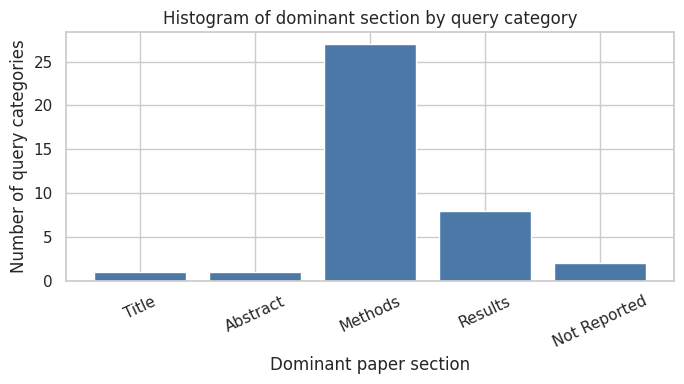

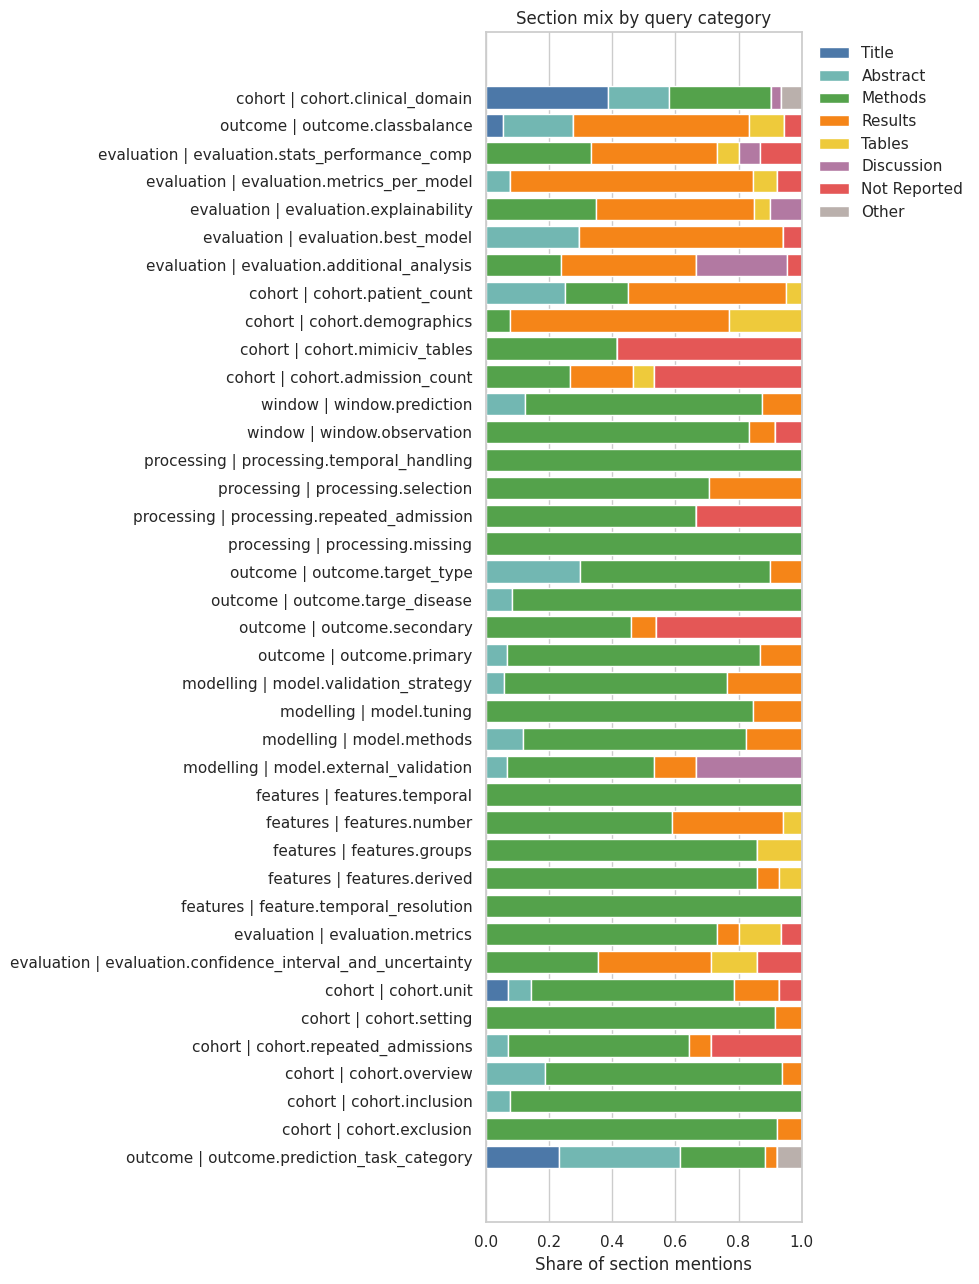

In [26]:
dominant_counts = (
    section_count_table["dominant_section"]
    .value_counts()
    .reindex(ordered_section_cols, fill_value=0)
    .reset_index()
)
dominant_counts.columns = ["section_family", "category_count"]

display(dominant_counts[dominant_counts["category_count"] > 0])

fig, ax = plt.subplots(figsize=(7, 4))
plot_counts = dominant_counts[dominant_counts["category_count"] > 0]
ax.bar(plot_counts["section_family"], plot_counts["category_count"], color="#4c78a8")
ax.set_xlabel("Dominant paper section")
ax.set_ylabel("Number of query categories")
ax.set_title("Histogram of dominant section by query category")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()

category_order = (
    section_count_table
    .sort_values(["dominant_section", "field_id", "category"])
    .index
)
stacked = section_share_table.loc[category_order, ordered_section_cols]

fig, ax = plt.subplots(figsize=(10, 13))
left = np.zeros(len(stacked))
colors = {
    "Title": "#4c78a8",
    "Abstract": "#72b7b2",
    "Methods": "#54a24b",
    "Results": "#f58518",
    "Tables": "#eeca3b",
    "Discussion": "#b279a2",
    "Supplementary": "#9d755d",
    "Not Reported": "#e45756",
    "Other": "#bab0ac",
}
for col in ordered_section_cols:
    values = stacked[col].to_numpy()
    ax.barh(
        [f"{field} | {category}" for field, category in stacked.index],
        values,
        left=left,
        label=col,
        color=colors.get(col, None),
    )
    left += values
ax.set_xlim(0, 1)
ax.set_xlabel("Share of section mentions")
ax.set_ylabel("")
ax.set_title("Section mix by query category")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

## Compact Routing Table

This is a concise version for reporting: each category, its dominant section, and a practical retrieval hint.

In [27]:
category_section_map = section_count_table.reset_index()[
    ["field_id", "category", "dominant_section", "dominant_share", "total_mentions"]
].copy()
category_section_map["routing_hint"] = np.select(
    [
        category_section_map["dominant_section"].eq("Methods"),
        category_section_map["dominant_section"].eq("Results"),
        category_section_map["dominant_section"].isin(["Title", "Abstract"]),
        category_section_map["dominant_section"].eq("Tables"),
        category_section_map["dominant_section"].eq("Not Reported"),
    ],
    [
        "Retrieve Methods first",
        "Retrieve Results and table-adjacent chunks first",
        "Retrieve Title/Abstract first, then Methods",
        "Retrieve serialized tables and captions first",
        "Prompt for explicit not-reported handling",
    ],
    default="Use broad section retrieval",
)

display(
    category_section_map
    .sort_values(["field_id", "category"])
    .style.format({"dominant_share": "{:.1%}"})
)

section_family,field_id,category,dominant_section,dominant_share,total_mentions,routing_hint
0,cohort,cohort.admission_count,Not Reported,46.7%,15,Prompt for explicit not-reported handling
1,cohort,cohort.clinical_domain,Title,38.7%,31,"Retrieve Title/Abstract first, then Methods"
2,cohort,cohort.demographics,Results,69.2%,13,Retrieve Results and table-adjacent chunks first
3,cohort,cohort.exclusion,Methods,92.3%,13,Retrieve Methods first
4,cohort,cohort.inclusion,Methods,92.3%,13,Retrieve Methods first
5,cohort,cohort.mimiciv_tables,Not Reported,58.3%,12,Prompt for explicit not-reported handling
6,cohort,cohort.overview,Methods,75.0%,16,Retrieve Methods first
7,cohort,cohort.patient_count,Results,50.0%,20,Retrieve Results and table-adjacent chunks first
8,cohort,cohort.repeated_admissions,Methods,57.1%,14,Retrieve Methods first
9,cohort,cohort.setting,Methods,91.7%,12,Retrieve Methods first


## Finding

Across the 12 papers, the query categories are mostly Methods-oriented, with a smaller Results/table-oriented group and a few Title/Abstract or Not Reported categories. This supports a category-aware RAG strategy: route Methods-heavy questions to study-design, cohort, outcome-definition, feature-engineering, modelling, and preprocessing chunks; route Results-heavy questions to results and table-adjacent chunks; and handle Not Reported categories with explicit absence detection instead of forcing an inferred answer.